<a href="https://colab.research.google.com/github/CodeWiz04/docvqa-layout-fusion/blob/main/docvqa_layout_fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Layout-Guided Multimodal Fusion for Document VQA: full pipeline notebook

Single notebook, run top to bottom (Colab, GPU runtime).

| Part | Contents | Owner |
|---|---|---|
| 1 | Data loading from Drive, preprocessing, loaders, statistics (full SP-DocVQA, T4 budget) | Person 1 |
| 2 | Evaluation metrics (ANLS, RA, ANLSL, BLEU-4), bootstrap CIs, `evaluate()` | Person 1 |
| 3 | Backbone, baselines V1-V4, proposed fusion V5, training, computational cost | Persons 2 and 3 |
| 4 | Main results, significance, charts, error analysis, attention maps, gallery | Persons 1 and 3 |
| 5 | Complexity scaling (InfographicVQA, ChartQA), robustness (DUDE), OCR-shift control, final summary | Person 1 |
| 6 | In-domain experiments on ChartQA and InfographicVQA, executed on Kaggle (2x T4) | Person 2 |
| 7 | Report compilation: tables, figures, exact parameter counts, CPU latency (runs on CPU) | Person 1 |

# Part 1: Data preparation and preprocessing (full SP-DocVQA, read from Google Drive)

Dataset: **SP-DocVQA** (RRC challenge 17, 2020-23): 39,463 training questions on 10,194 pages and 5,349 validation questions on 1,286 pages, with Microsoft-Read OCR for every page. The three files you uploaded to Drive are read directly (nothing is downloaded from the internet):

| File | Used for |
|---|---|
| `spdocvqa_qas.zip` | questions and answers (`train_v1.0_withQT.json`, `val_v1.0_withQT.json`) |
| `spdocvqa_images.tar.gz` | page images (streamed once, resized, cached) |
| `spdocvqa_ocr.tar.gz` | OCR words and boxes (streamed once, converted to the 0-1000 grid, cached) |

**Splits.** The official test split has no public answers, so: the official **validation** questions become our **test** set; a document-level hold-out of the training set is our **validation** set (used only for early stopping); the rest is **train**. Splitting is by document, so no page text leaks between splits.

**Budget.** One preset controls how much data and how many epochs are used (`PRESET` in section 1). `"t4"` fits a free Colab T4 session; `"dry"` is a 15-minute smoke test; `"full"` uses every question.

**Before running:** Runtime -> Change runtime type -> GPU (T4), then run the cells in order. The first run streams the 8.5 GB image archive once (about 10-25 minutes) and saves a small cache back to Drive, so later sessions start in a minute.

Pipeline: locate files -> read questions -> document-level split -> build page cache -> tokenise `[CLS] question [SEP] OCR [SEP]` with a box per sub-word -> answer-span matching -> resize/pad image -> DataLoaders -> visual check -> dataset statistics.

## 1. Install and settings

In [1]:
# [colab-only]
!pip -q install datasets transformers sacrebleu
import torch
print("torch", torch.__version__, "| GPU available:", torch.cuda.is_available())
from google.colab import drive
drive.mount("/content/drive")

torch 2.11.0+cu130 | GPU available: True


In [2]:
import os, sys, random, re, string
from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import matplotlib.pyplot as plt
import matplotlib.patches as patches



# ---------------------------------------------------------------------------------------------
# RUN BUDGET: change PRESET only. Everything below (data size, image size, epochs) follows from it.
#   "dry"  : ~15-minute smoke test on a few hundred questions (check that the pipeline runs)
#   "t4"   : default for a free Colab T4 (8,000 train / 800 val / 2,000 test questions, 384 px pages, 6 epochs)
#   "full" : every question, 512 px pages, 10 epochs (needs a stronger GPU or several sessions)
# ---------------------------------------------------------------------------------------------
PRESET = "t4"
PRESETS = {
    "dry":  dict(train_q=1000, val_q=200,  test_q=500,  img_size=384, epochs=2),
    "t4":   dict(train_q=8000, val_q=800,  test_q=2000, img_size=384, epochs=6),
    "full": dict(train_q=None, val_q=2000, test_q=None, img_size=512, epochs=10),
}
BUD = PRESETS[PRESET]
ON_COLAB = "google.colab" in sys.modules
RUN_DIR = "/content/drive/MyDrive/docvqa_lgovf" if ON_COLAB else "run"      # outputs that must survive a disconnect
LOCAL_DIR = "/content/docvqa_local" if ON_COLAB else "run_local"            # fast local disk for the page cache

@dataclass
class Config:
    src_dir: str = ""              # folder on Drive that holds the three uploaded files ("" = search My Drive)
    run_dir: str = RUN_DIR
    local_dir: str = LOCAL_DIR
    train_q: object = BUD["train_q"]   # None = all
    val_q: int = BUD["val_q"]
    test_q: object = BUD["test_q"]
    store_side: int = 768          # cached pages are stored with this longer side (JPEG)
    img_size: int = BUD["img_size"]    # longer side fed to the ViT, then padded to a square
    patch_size: int = 16           # ViT patch size -> (384/16)^2 = 576 patches
    img_mean: tuple = (0.5, 0.5, 0.5)
    img_std: tuple = (0.5, 0.5, 0.5)
    tokenizer_name: str = "bert-base-uncased"
    max_seq_len: int = 512         # question + OCR tokens + 3 special tokens
    max_answer_len: int = 32       # target length for the answer head
    box_grid: int = 1000           # boxes normalised to a 0..1000 integer grid
    batch_size: int = 8
    num_workers: int = 2
    accept_partial: bool = True    # continue (and cache) when a damaged archive still yields at least half of the pages
    copy_local: bool = True        # copy each Drive archive to local disk before reading (needs ~9 GB free)
    control_n: int = 100           # first test questions whose full-resolution page is kept (Tesseract control, Part 5)
    seed: int = 42


CFG = Config()


def set_seed(seed=CFG.seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


set_seed()

## 2. Locate the uploaded files and read the questions
The code looks for the three files in `CFG.src_dir` first, then anywhere in My Drive. If they are in a folder with another name, set `CFG.src_dir = "/content/drive/MyDrive/<folder>"` and re-run this cell.

In [ ]:
import glob, json, time, zlib, zipfile, tarfile, io, pickle, shutil, hashlib
import concurrent.futures as cf
import threading
from pathlib import Path

FILES = {"qas": "spdocvqa_qas.zip", "images": "spdocvqa_images.tar.gz", "ocr": "spdocvqa_ocr.tar.gz"}


def find_file(name):
    cands = [Path(CFG.src_dir) / name] if CFG.src_dir else []
    root = "/content/drive/MyDrive" if ON_COLAB else "."
    cands.append(Path(root) / name)
    for p in cands:
        if p.exists():
            return p
    hits = glob.glob(f"{root}/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found under {root}. Set CFG.src_dir to the folder that contains it.")
    return Path(hits[0])


SRC = {k: find_file(v) for k, v in FILES.items()}
for k, p in SRC.items():
    print(f"{k:7s} {p}  ({p.stat().st_size / 1e9:.2f} GB)")


def read_qas(zpath):
    """question list per split: [{qid, stem, doc, question, answers}]"""
    out = {}
    with zipfile.ZipFile(zpath) as z:
        names = z.namelist()
        for split in ("train", "val"):
            cand = [n for n in names if Path(n).name.startswith(f"{split}_v1.0") and n.endswith(".json")]
            cand.sort(key=lambda n: "withQT" not in n)                 # prefer the *_withQT.json file
            if not cand:
                raise FileNotFoundError(f"no {split}_v1.0*.json inside {zpath}: {names[:10]}")
            data = json.loads(z.read(cand[0]))["data"]
            out[split] = [{"qid": d.get("questionId"), "stem": Path(d["image"]).stem,
                           "doc": str(d.get("ucsf_document_id", Path(d["image"]).stem.rsplit("_", 1)[0])),
                           "question": d["question"], "answers": [a for a in d.get("answers", []) if str(a).strip()]}
                          for d in data]
    return out


QA = read_qas(SRC["qas"])
print({k: f"{len(v)} questions, {len({q['stem'] for q in v})} pages" for k, v in QA.items()})
print("example:", QA["train"][0])

## 3. Document-level split: train / val / test
* **test** = random documents from the official validation questions (official test answers are not public);
* **val** = random documents held out of the official training questions (early stopping only);
* **train** = other training documents, until `train_q` questions are collected.

All choices use the fixed seed, so every team member gets the identical split.

In [ ]:
def by_doc(questions):
    g = {}
    for q in questions:
        g.setdefault(q["doc"], []).append(q)
    return g


def take_docs(order, groups, n):
    """Take whole documents in `order` until n questions are collected (n=None: take all); trim to exactly n."""
    taken, used, count = [], [], 0
    for d in order:
        if n is not None and count >= n:
            break
        taken += groups[d]; used.append(d); count += len(groups[d])
    return (taken[:n] if n is not None else taken), used


rng = random.Random(CFG.seed)
g_tr, g_va = by_doc(QA["train"]), by_doc(QA["val"])
order_tr, order_va = sorted(g_tr), sorted(g_va)
rng.shuffle(order_tr); rng.shuffle(order_va)

val_list, used = take_docs(order_tr, g_tr, CFG.val_q)
train_list, _ = take_docs(order_tr[len(used):], g_tr, CFG.train_q)
test_list, _ = take_docs(order_va, g_va, CFG.test_q)
SPLIT_Q = {"train": train_list, "val": val_list, "test": test_list}
assert not ({q["doc"] for q in train_list} & {q["doc"] for q in val_list}), "document leak between train and val"

print("preset:", PRESET, "|", {k: f"{len(v)} q / {len({q['stem'] for q in v})} pages" for k, v in SPLIT_Q.items()})
NEED = {q["stem"] for v in SPLIT_Q.values() for q in v}
NEED_FULL = {q["stem"] for q in test_list[:CFG.control_n]}      # full-resolution copies for the Tesseract control (Part 5)
print("pages to cache:", len(NEED))

## 4. Build the page cache (images + OCR), once
The two archives are **streamed** (never fully unpacked): only the pages the split needs are kept. Pages are resized to `CFG.store_side` and saved as JPEG; OCR is converted to words with boxes on the 0-1000 grid. The result is copied back to Drive as one tar file, so after a disconnect the next session restores it in about a minute instead of re-reading 8.5 GB. Change `PRESET` and the cache is rebuilt automatically for the new page set.

In [ ]:
from PIL import Image

LOCAL = Path(CFG.local_dir); IMG_DIR, FULL_DIR, OCR_PKL = LOCAL / "images", LOCAL / "images_full", LOCAL / "ocr.pkl"
_key = hashlib.md5(json.dumps(sorted(NEED) + sorted(NEED_FULL) + [CFG.store_side]).encode()).hexdigest()[:10]
CACHE_TAR = Path(CFG.run_dir) / f"spdocvqa_cache_{_key}.tar"


def parse_spdocvqa_ocr(obj):
    """Microsoft-Read JSON -> (words, boxes on the 0-1000 grid). Pixel boxes are divided by the page size stored in the file."""
    res = None
    if "recognitionResults" in obj:
        res = obj["recognitionResults"][0]
    elif "analyzeResult" in obj:
        res = obj["analyzeResult"]["readResults"][0]
    if res is None:
        return [], []
    W, H = float(res.get("width") or 1), float(res.get("height") or 1)
    g = lambda v: int(min(max(v, 0), 1000))
    words, boxes = [], []
    for line in res.get("lines", []):
        items = line.get("words") or [{"text": t, "boundingBox": line["boundingBox"]} for t in str(line.get("text", "")).split()]
        for wd in items:
            t = str(wd.get("text", "")).strip()
            if not t:
                continue
            xs, ys = wd["boundingBox"][0::2], wd["boundingBox"][1::2]
            words.append(t)
            boxes.append([g(1000 * min(xs) / W), g(1000 * min(ys) / H), g(1000 * max(xs) / W), g(1000 * max(ys) / H)])
    return words, boxes


def stream_tar(path, wanted, handler, desc, workers=2):
    """Read a .tar.gz sequentially; call handler(stem, bytes) in a small thread pool for the wanted members only."""
    wanted, found, sem = set(wanted), set(), threading.Semaphore(32)
    errs = []

    def run(stem, data):
        try:
            handler(stem, data)
        except Exception as e:                      # keep going: one broken page must not stop the build
            errs.append((stem, repr(e)))
        finally:
            sem.release()

    t0, broken = time.time(), None
    path = local_copy(path, desc)
    with cf.ThreadPoolExecutor(workers) as pool:
        try:
            with tarfile.open(path, "r|gz") as tf:
                for m in tf:
                    if not m.isfile():
                        continue
                    stem = Path(m.name).stem
                    if stem not in wanted or stem in found:
                        continue
                    data = tf.extractfile(m).read()
                    found.add(stem)
                    sem.acquire()
                    pool.submit(run, stem, data)
                    if len(found) % 500 == 0:
                        print(f"  {desc}: {len(found)}/{len(wanted)} ({(time.time() - t0) / 60:.1f} min)")
                    if len(found) == len(wanted):
                        break
        except (tarfile.ReadError, EOFError, zlib.error, OSError) as e:       # corrupt or truncated archive
            broken = repr(e)
    print(f"  {desc}: found {len(found)}/{len(wanted)} in {(time.time() - t0) / 60:.1f} min" + (f" | {len(errs)} errors, e.g. {errs[0]}" if errs else ""))
    if broken:
        print(f"  !! {desc} archive is damaged after {len(found)} wanted pages: {broken}")
        print("     The file in Drive is corrupt or was truncated by the upload. Pages read before the damage are kept (the run can continue")
        print(f"     with fewer questions), but re-uploading {Path(path).name} is the proper fix. Check: `!gzip -t <file>` must print nothing.")
    if not broken and len(found) < len(wanted):
        print(f"  !! {desc}: the archive ended after {len(found)} of {len(wanted)} wanted pages (truncated upload, or the pages are not in it).")
        print("     Re-upload the file; check with `!gzip -t <file>`.")
    return found, broken is None and len(found) == len(wanted)


def local_copy(path, desc):
    """Copy a Drive archive to the fast local disk first (Drive streaming can return damaged reads); verify the size."""
    path = Path(path)
    if not CFG.copy_local:
        return path
    dst = LOCAL / "src" / path.name
    dst.parent.mkdir(parents=True, exist_ok=True)
    if not dst.exists() or dst.stat().st_size != path.stat().st_size:
        print(f"  copying {path.name} ({path.stat().st_size / 1e9:.2f} GB) to local disk ...")
        t0 = time.time(); shutil.copyfile(path, dst)
        print(f"  copied in {(time.time() - t0) / 60:.1f} min")
    if dst.stat().st_size != path.stat().st_size:
        raise IOError(f"{desc}: local copy has {dst.stat().st_size} bytes, Drive file has {path.stat().st_size}. Re-run the cell.")
    return dst


def build_cache():
    for d in (IMG_DIR, FULL_DIR):
        d.mkdir(parents=True, exist_ok=True)
    ocr = {}

    def do_image(stem, data):
        im = Image.open(io.BytesIO(data)).convert("RGB")
        if stem in NEED_FULL:
            (FULL_DIR / f"{stem}.png").write_bytes(data)
        sc = CFG.store_side / max(im.size)
        if sc < 1:
            im = im.resize((max(1, round(im.width * sc)), max(1, round(im.height * sc))), Image.LANCZOS)
        im.save(IMG_DIR / f"{stem}.jpg", quality=92)

    def do_ocr(stem, data):
        ocr[stem] = parse_spdocvqa_ocr(json.loads(data))

    print("streaming OCR archive ..."); _, ok1 = stream_tar(SRC["ocr"], NEED, do_ocr, "ocr")
    print("streaming image archive ..."); _, ok2 = stream_tar(SRC["images"], NEED, do_image, "images")
    with open(OCR_PKL, "wb") as f:
        pickle.dump(ocr, f)
    return ok1 and ok2


def cache_complete():
    return OCR_PKL.exists() and all((IMG_DIR / f"{s}.jpg").exists() for s in NEED) \
        and all((FULL_DIR / f"{s}.png").exists() for s in NEED_FULL)


if cache_complete():
    print("local cache already present")
elif CACHE_TAR.exists():
    print("restoring cache from Drive:", CACHE_TAR)
    with tarfile.open(CACHE_TAR) as tf:
        tf.extractall(LOCAL)
else:
    complete = build_cache()
    got = sum((IMG_DIR / f"{s_}.jpg").exists() for s_ in NEED)
    partial_ok = (not complete) and CFG.accept_partial and got >= 0.5 * len(NEED)
    if partial_ok:
        print(f"NOTE: a damaged archive gave {got}/{len(NEED)} pages ({100 * got / len(NEED):.0f}%). Continuing with the pages that could be read:")
        print("      the selected documents are random, so the remaining questions are still a random sample, just smaller.")
        print("      The partial cache is saved to Drive so the next session does not read the archives again.")
    if complete or partial_ok:
        Path(CFG.run_dir).mkdir(parents=True, exist_ok=True)
        tmp = LOCAL / "cache.tar"
        with tarfile.open(tmp, "w") as tf:
            for p in (IMG_DIR, FULL_DIR, OCR_PKL):
                tf.add(p, arcname=p.relative_to(LOCAL))
        shutil.copy(tmp, CACHE_TAR); tmp.unlink()
        print("cache saved to Drive:", CACHE_TAR, f"({CACHE_TAR.stat().st_size / 1e9:.2f} GB)")
    else:
        print("WARNING: less than half of the pages could be read (see the messages above), so the cache was NOT saved. Re-upload the damaged archive.")

with open(OCR_PKL, "rb") as f:
    OCR_STORE = pickle.load(f)
have_img = {s for s in NEED if (IMG_DIR / f"{s}.jpg").exists() and s in OCR_STORE}
for k in SPLIT_Q:      # drop questions whose page image or OCR is missing (none expected; printed so you can check)
    n0 = len(SPLIT_Q[k]); SPLIT_Q[k] = [q for q in SPLIT_Q[k] if q["stem"] in have_img]
    if len(SPLIT_Q[k]) != n0:
        print(f"WARNING {k}: dropped {n0 - len(SPLIT_Q[k])} questions without a page image or OCR")
assert all(len(v) > 0 for v in SPLIT_Q.values()), "a split is empty because pages are missing from the archives: re-upload the damaged archive (see the messages above)"
print({k: len(v) for k, v in SPLIT_Q.items()}, "| pages with OCR:", sum(s in OCR_STORE for s in have_img), "/", len(have_img))

## 5. Split objects
`DriveSplit` behaves like a Hugging Face split for the rest of the notebook (`len`, indexing, `.select`, `.select_columns`): each item is `{image, query, answers, words, bounding_boxes}`. Page images are opened lazily, so reading only the OCR words (error analysis, statistics) never decodes an image.

In [ ]:
class _Row(dict):
    """dict whose "image" entry is opened on first access."""
    def __init__(self, loader, **kw):
        super().__init__(**kw); self._loader = loader

    def __getitem__(self, k):
        if k == "image" and not dict.__contains__(self, "image"):
            dict.__setitem__(self, "image", self._loader())
        return dict.__getitem__(self, k)


class DriveSplit:
    def __init__(self, qs, ocr, img_dir, full_dir, cols=None):
        self.qs, self.ocr, self.img_dir, self.full_dir, self.cols = qs, ocr, Path(img_dir), Path(full_dir), cols

    def __len__(self):
        return len(self.qs)

    def __getitem__(self, i):
        q = self.qs[i]
        words, boxes = self.ocr.get(q["stem"], ([], []))
        d = {"query": q["question"], "answers": list(q["answers"]), "words": words, "bounding_boxes": boxes,
             "questionId": q["qid"], "page": q["stem"]}
        if self.cols is not None:
            return {k: d[k] for k in self.cols}
        path = self.img_dir / f"{q['stem']}.jpg"
        return _Row(lambda: Image.open(path), **d)

    def select(self, idx):
        return DriveSplit([self.qs[i] for i in idx], self.ocr, self.img_dir, self.full_dir, self.cols)

    def select_columns(self, cols):
        return DriveSplit(self.qs, self.ocr, self.img_dir, self.full_dir, list(cols))

    def full_image(self, i):
        """Full-resolution page (kept only for the first CFG.control_n test questions); falls back to the cached page."""
        p = self.full_dir / f"{self.qs[i]['stem']}.png"
        return Image.open(p).convert("RGB") if p.exists() else self[i]["image"].convert("RGB")


splits = {k: DriveSplit(v, OCR_STORE, IMG_DIR, FULL_DIR) for k, v in SPLIT_Q.items()}
ex = splits["train"][0]
print({k: len(v) for k, v in splits.items()}, "questions per split")
print("question:", ex["query"]); print("answers :", ex["answers"])
print("n words :", len(ex["words"]), "| first words:", ex["words"][:5], "| first boxes:", ex["bounding_boxes"][:2])
print("cached page size:", ex["image"].size)

## 5b. Text, box and answer helpers
* `normalize_text`: lower-case, strip punctuation (used for answer matching).
* Boxes: the cache already stores boxes on the 0-1000 grid (section 4 divides the pixel boxes by the page size in the OCR file); `detect_box_mode` double-checks this on 100 pages and must print `norm1000`.
* `find_answer_span`: finds an OCR word span matching a ground-truth answer (`-1, -1` if the answer is not an exact OCR span).

In [5]:
def normalize_text(s):
    s = s.lower().strip().translate(str.maketrans("", "", string.punctuation))
    return re.sub(r"\s+", " ", s)


def get_question(ex):
    q = ex["query"]
    if isinstance(q, dict):
        q = q.get("en") or next(v for v in q.values() if v)
    return q


def flatten_box(b):
    """Accept [x0,y0,x1,y1] or an 8-number quadrilateral; return [xmin,ymin,xmax,ymax]."""
    b = [float(v) for v in np.array(b).flatten()]
    if len(b) >= 8:
        xs, ys = b[0:8:2], b[1:8:2]
        return [min(xs), min(ys), max(xs), max(ys)]
    return b[:4]


def detect_box_mode(hf_split, n=100):
    """Pages differ in width, so the right-most OCR x is stable relative to the page width if boxes are in
    pixels, and stable relative to 1000 if they are already on the 0-1000 grid. Pick the steadier one."""
    r_pix, r_norm, max_all = [], [], 0.0
    for i in range(min(n, len(hf_split))):
        ex = hf_split[i]
        w, h = ex["image"].size
        if not len(ex["bounding_boxes"]):
            continue
        fb = [flatten_box(b) for b in ex["bounding_boxes"]]
        mx = max(b[2] for b in fb)
        max_all = max(max_all, max(max(b) for b in fb))
        r_pix.append(mx / w); r_norm.append(mx / 1000.0)
    if max_all <= 1.5:
        return "unit"
    cv = lambda a: float(np.std(a) / (np.mean(a) + 1e-9))
    print(f"spread of right-edge ratio: pixel={cv(r_pix):.3f}  norm1000={cv(r_norm):.3f}  (lower = better fit)")
    return "pixel" if cv(r_pix) < cv(r_norm) else "norm1000"


def to_grid(box, w, h, mode):
    x0, y0, x1, y1 = flatten_box(box)
    if mode == "unit":
        vals = [x0, y0, x1, y1]; vals = [v * CFG.box_grid for v in vals]
    elif mode == "norm1000":
        vals = [x0, y0, x1, y1]
    else:  # pixel
        vals = [x0 / w * CFG.box_grid, y0 / h * CFG.box_grid, x1 / w * CFG.box_grid, y1 / h * CFG.box_grid]
    return [int(min(max(v, 0), CFG.box_grid)) for v in vals]


BOX_MODE = detect_box_mode(splits["train"])
print("Detected box mode:", BOX_MODE)
assert BOX_MODE == "norm1000", "the cache stores OCR boxes on the 0-1000 grid, so norm1000 is expected"


def get_words_boxes(ex, w, h):
    words, boxes = [], []
    for word, box in zip(ex["words"], ex["bounding_boxes"]):
        if word is None or not str(word).strip():
            continue
        words.append(str(word))
        boxes.append(to_grid(box, w, h, BOX_MODE))
    return words, boxes


def find_answer_span(words, answers, max_ngram=12):
    targets = {normalize_text(a) for a in answers if a and a.strip()}
    norm_words = [normalize_text(w) for w in words]
    for n in range(1, max_ngram + 1):
        for i in range(len(words) - n + 1):
            if " ".join(norm_words[i:i + n]).strip() in targets:
                return i, i + n - 1
    return -1, -1

spread of right-edge ratio: pixel=0.255  norm1000=0.049  (lower = better fit)
Detected box mode: norm1000


## 5c. Image transform
Longer side -> `img_size`, pasted top-left on a white square canvas, then normalised. Light augmentation (brightness/contrast, +-2 degree rotation, mild noise) is applied to the training split only; text and boxes are never augmented.

In [6]:
def build_image_transform(train):
    size = CFG.img_size

    def resize_pad(img):
        w, h = img.size
        scale = size / max(w, h)
        img = img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.BICUBIC)
        canvas = Image.new("RGB", (size, size), (255, 255, 255))
        canvas.paste(img, (0, 0))
        return canvas

    class GaussianNoise:
        def __call__(self, x):
            return (x + torch.randn_like(x) * 0.02).clamp(0, 1)

    steps = [T.Lambda(resize_pad)]
    if train:
        steps += [T.ColorJitter(brightness=0.2, contrast=0.2), T.RandomRotation(2, fill=255),
                  T.ToTensor(), T.RandomApply([GaussianNoise()], p=0.3)]
    else:
        steps += [T.ToTensor()]
    steps += [T.Normalize(CFG.img_mean, CFG.img_std)]
    return T.Compose(steps)

## 6. Tokenizer

In [7]:
# [colab-only]
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(CFG.tokenizer_name)
print(type(tok).__name__, "| fast:", tok.is_fast)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BertTokenizer | fast: True


## 7. Dataset class
Each sample: `[CLS] question [SEP] OCR tokens [SEP]` padded to 512. Every sub-word inherits its word's box; question tokens get box `[0,0,0,0]`. Raw question and answers are kept for ANLS later.

In [8]:
class DocVQADataset(Dataset):
    def __init__(self, hf_split, tokenizer, train=False):
        self.hf, self.tok, self.train = hf_split, tokenizer, train
        self.transform = build_image_transform(train)

    def __len__(self):
        return len(self.hf)

    def get_raw_image(self, idx):
        return self.hf[idx]["image"].convert("RGB")

    def _encode(self, question, words, boxes):
        tok, L = self.tok, CFG.max_seq_len
        q_ids = tok(question, add_special_tokens=False, truncation=True, max_length=64)["input_ids"]
        if words:
            ocr = tok(words, is_split_into_words=True, add_special_tokens=False)
            ocr_ids, word_ids = ocr["input_ids"], ocr.word_ids()
        else:
            ocr_ids, word_ids = [], []
        budget = L - len(q_ids) - 3
        ocr_ids, word_ids = ocr_ids[:budget], word_ids[:budget]

        input_ids = [tok.cls_token_id] + q_ids + [tok.sep_token_id] + ocr_ids + [tok.sep_token_id]
        bbox = [[0, 0, 0, 0]] * (len(q_ids) + 2) + [boxes[w] for w in word_ids] + [[1000, 1000, 1000, 1000]]
        full_word_ids = [-1] * (len(q_ids) + 2) + list(word_ids) + [-1]

        pad = L - len(input_ids)
        attention_mask = [1] * len(input_ids) + [0] * pad
        input_ids += [tok.pad_token_id] * pad
        bbox += [[0, 0, 0, 0]] * pad
        full_word_ids += [-1] * pad
        return {"input_ids": torch.tensor(input_ids), "attention_mask": torch.tensor(attention_mask),
                "bbox": torch.tensor(bbox), "word_ids": full_word_ids}

    @staticmethod
    def _word_span_to_token_span(word_ids, w_start, w_end):
        if w_start < 0:
            return -1, -1
        pos = [i for i, w in enumerate(word_ids) if w_start <= w <= w_end]
        return (pos[0], pos[-1]) if pos else (-1, -1)

    def _text_features(self, ex, w, h):
        question = get_question(ex)
        words, boxes = get_words_boxes(ex, w, h)
        answers = [a for a in (ex.get("answers") or []) if a and str(a).strip()]
        enc = self._encode(question, words, boxes)
        ws, we = find_answer_span(words, answers) if answers else (-1, -1)
        st, en = self._word_span_to_token_span(enc["word_ids"], ws, we)
        return question, words, answers, enc, st, en

    def __getitem__(self, idx):
        ex = self.hf[idx]
        image = ex["image"].convert("RGB")
        w, h = image.size
        question, words, answers, enc, st, en = self._text_features(ex, w, h)

        target = self.tok(answers[0] if answers else "", add_special_tokens=True, truncation=True,
                          max_length=CFG.max_answer_len, padding="max_length", return_tensors="pt")["input_ids"][0]
        labels = target.clone()
        labels[labels == self.tok.pad_token_id] = -100       # ignored by cross-entropy

        return {
            "pixel_values": self.transform(image),            # (3, S, S)
            "input_ids": enc["input_ids"],                    # (L,)
            "attention_mask": enc["attention_mask"],          # (L,)
            "bbox": enc["bbox"],                              # (L, 4) on 0..1000
            "labels": labels,                                 # (A,)
            "start_positions": torch.tensor(st),              # -1 if not an exact OCR span
            "end_positions": torch.tensor(en),
            "index": idx,
            "question": question,
            "answers": answers,
        }

    def stats_row(self, idx):
        ex = self.hf[idx]
        w, h = ex["image"].size
        question, words, answers, enc, st, en = self._text_features(ex, w, h)
        return {"ocr_words": len(words), "tokens": int(enc["attention_mask"].sum()), "extractive": st >= 0}


def collate_fn(batch):
    out = {}
    for key in batch[0]:
        vals = [b[key] for b in batch]
        out[key] = torch.stack(vals) if isinstance(vals[0], torch.Tensor) else vals
    return out


def make_loader(ds, shuffle=False):
    return DataLoader(ds, batch_size=CFG.batch_size, shuffle=shuffle, num_workers=CFG.num_workers,
                      collate_fn=collate_fn, pin_memory=torch.cuda.is_available())

## 8. Build datasets and loaders, check one batch

In [9]:
datasets_ = {name: DocVQADataset(hf, tok, train=(name == "train")) for name, hf in splits.items()}
loaders = {name: make_loader(ds, shuffle=(name == "train")) for name, ds in datasets_.items()}

batch = next(iter(loaders["train"]))
for k, v in batch.items():
    print(f"{k:16s}", tuple(v.shape) if hasattr(v, "shape") else f"list[{len(v)}]")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (575 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (590 > 512). Running this sequence through the model will result in indexing errors


pixel_values     (8, 3, 512, 512)
input_ids        (8, 512)
attention_mask   (8, 512)
bbox             (8, 512, 4)
labels           (8, 32)
start_positions  (8,)
end_positions    (8,)
index            list[8]
question         list[8]
answers          list[8]


## 9. Visual check: raw page vs preprocessed page with OCR boxes
Red boxes are the OCR word boxes mapped onto the resized page. If they do not sit on the text, the box mode in section 4 is wrong. This is also the "raw vs preprocessed" figure for the report.

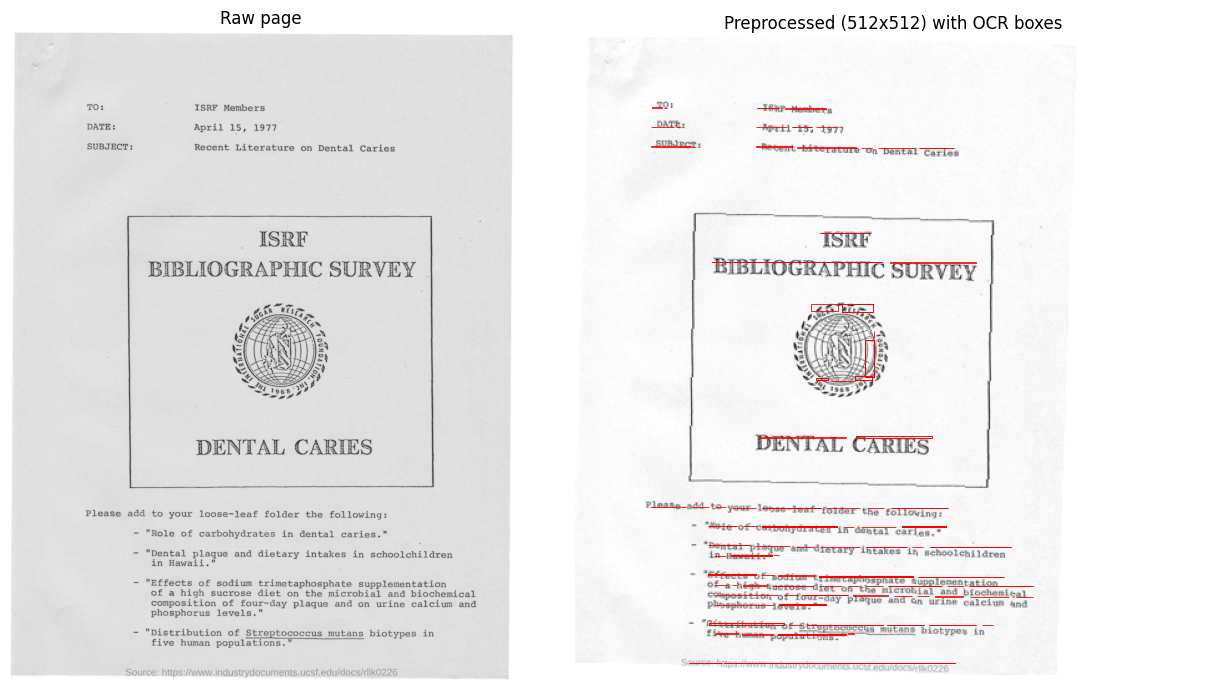

Question  : Which biotypes distribution is taken place in five human populations?
Answers   : ['streptococcus mutans', 'Streptococcus mutans']
Span found: streptococcus mutans


In [10]:
def denormalize(pv):
    mean = np.array(CFG.img_mean)[:, None, None]; std = np.array(CFG.img_std)[:, None, None]
    return np.clip((pv.numpy() * std + mean).transpose(1, 2, 0), 0, 1)


def show_sample(ds, idx, max_boxes=600, save_path=None):
    s = ds[idx]
    raw_img = ds.get_raw_image(idx)
    prep = denormalize(s["pixel_values"])
    S = prep.shape[0]
    w, h = raw_img.size
    scale = S / max(w, h)

    fig, ax = plt.subplots(1, 2, figsize=(13, 7))
    ax[0].imshow(raw_img); ax[0].set_title("Raw page"); ax[0].axis("off")
    ax[1].imshow(prep); ax[1].set_title(f"Preprocessed ({S}x{S}) with OCR boxes"); ax[1].axis("off")
    for box, m in list(zip(s["bbox"].tolist(), s["attention_mask"].tolist()))[:max_boxes]:
        if not m or box in ([0, 0, 0, 0], [1000, 1000, 1000, 1000]):
            continue
        x0, y0 = box[0] / 1000 * w * scale, box[1] / 1000 * h * scale
        x1, y1 = box[2] / 1000 * w * scale, box[3] / 1000 * h * scale
        ax[1].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=0.6))
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Question  :", s["question"])
    print("Answers   :", s["answers"])
    st, en = int(s["start_positions"]), int(s["end_positions"])
    print("Span found:", ds.tok.decode(s["input_ids"][st:en + 1]) if st >= 0
          else "none (answer is not an exact OCR span; the generative head handles these)")


show_sample(datasets_["train"], 0)

## 10. Dataset statistics (for the report's dataset table)
Also reports how many pages exceed the 512-token limit (answer may be truncated) and how many answers are exact OCR spans.

Columns are computed on the first 2,000 questions of each split; `questions` is the full split size.

In [11]:
rows = []
STAT_N = 2000      # statistics on the first 2,000 questions of each split (splits are randomly ordered)
for name, ds in datasets_.items():
    st = pd.DataFrame([ds.stats_row(i) for i in range(min(len(ds), STAT_N))])
    rows.append({
        "split": name,
        "questions": len(ds),
        "avg OCR words": round(st["ocr_words"].mean(), 1),
        "avg tokens (<=512)": round(st["tokens"].mean(), 1),
        "% truncated at 512": round(100 * (st["tokens"] >= CFG.max_seq_len).mean(), 1),
        "% extractive answers": round(100 * st["extractive"].mean(), 1),
    })
stats_df = pd.DataFrame(rows)
stats_df

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (521 > 512). Running this sequence through the model will result in indexing errors


,split,questions,avg OCR words,avg tokens (<=512),% truncated at 512,% extractive answers
0,train,800,273.4,368.1,33.9,87.0
1,val,200,272.1,350.6,33.0,85.0
2,test,200,202.4,302.2,20.0,95.0


# Part 2: Evaluation metrics and `evaluate()`

Implements the metrics defined in the methodology (Section I-E):

| Metric | Used on | Definition |
|---|---|---|
| **ANLS** (primary) | DocVQA, InfographicVQA, DUDE | Eq. (2): 1 - normalised Levenshtein distance, zeroed when the distance ratio is >= 0.5; max over ground-truth answers; mean over questions |
| **RA** (secondary) | ChartQA | Eq. (3): numeric answers within 5% relative error, otherwise exact string match |
| **ANLSL** (tertiary) | list-valued questions (InfographicVQA, DUDE) | ANLS between list elements after optimal alignment |
| **BLEU-4** (secondary) | all datasets | SacreBLEU corpus score, smoothed, lower-cased |

Plus bootstrap 95% confidence intervals (1,000 resamples), the paired V4-vs-V5 bootstrap test, and one `evaluate(model, loader)` function that every variant goes through. The sanity tests in section 18 must print "All metric sanity tests passed."

## 11. Imports for the metrics

In [12]:
import re
import numpy as np
import pandas as pd
import torch
from scipy.optimize import linear_sum_assignment

try:
    from tqdm.auto import tqdm
except ImportError:                      # tqdm is optional
    def tqdm(x, **kw):
        return x

## 12. ANLS (primary metric)

In [13]:
# ----------------------------------------------------------------------------- ANLS (primary metric)
def norm_answer(s):
    """Official ANLS normalisation: strip, lower-case, collapse whitespace (punctuation is kept)."""
    return " ".join(str(s if s is not None else "").strip().lower().split())


def levenshtein(a, b):
    """Edit distance d_L(a, b) with insertions, deletions and substitutions all costing 1."""
    if a == b:
        return 0
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def nls(pred, gt, tau=0.5):
    """Eq. (2): NLS = 1 - d_L/max(|pred|,|gt|) if that distance ratio is < 0.5, else 0."""
    p, g = norm_answer(pred), norm_answer(gt)
    m = max(len(p), len(g))
    if m == 0:
        return 1.0                       # both empty -> identical
    delta = levenshtein(p, g) / m
    return 1.0 - delta if delta < tau else 0.0


def score_anls(pred, gts):
    """One question: maximum NLS over all acceptable ground-truth answers."""
    if isinstance(gts, str):
        gts = [gts]
    if not gts:
        return 0.0
    return max(nls(pred, g) for g in gts)

## 13. Relaxed Accuracy (ChartQA)

In [14]:
# ----------------------------------------------------------------------------- Relaxed Accuracy (ChartQA)
def to_number(s):
    """Parse '1,200', '$45.5', '12%' -> float. Returns None if the string is not numeric."""
    t = str(s if s is not None else "").strip().lower().replace(",", "").replace("$", "").replace("%", "")
    try:
        return float(t)
    except ValueError:
        return None


def ra_single(pred, gt, tol=0.05):
    """Eq. (3): numeric gt -> |pred-gt|/|gt| <= 5%; non-numeric gt -> exact (normalised) string match."""
    g = to_number(gt)
    if g is None:
        return 1.0 if norm_answer(pred) == norm_answer(gt) else 0.0
    p = to_number(pred)
    if p is None:
        return 0.0
    if g == 0:
        return 1.0 if p == 0 else 0.0
    return 1.0 if abs(p - g) / abs(g) <= tol else 0.0


def score_ra(pred, gts, tol=0.05):
    if isinstance(gts, str):
        gts = [gts]
    if not gts:
        return 0.0
    return max(ra_single(pred, g, tol) for g in gts)

## 14. ANLSL (list-valued answers)
The sum of aligned NLS values is divided by the longer list, so missing and extra elements both lower the score. The methodology says only 'element-wise after optimal alignment'; this normalisation is the choice made here, so state it in the report.

In [15]:
# ----------------------------------------------------------------------------- ANLSL (list-valued answers)
def anlsl_single(pred_list, gt_list):
    """NLS between the elements of two lists after optimal (Hungarian) alignment.
    The sum of matched NLS is divided by max(len(pred), len(gt)), so missing and extra elements are penalised."""
    if not pred_list and not gt_list:
        return 1.0
    if not pred_list or not gt_list:
        return 0.0
    M = np.array([[nls(p, g) for g in gt_list] for p in pred_list])
    r, c = linear_sum_assignment(-M)
    return float(M[r, c].sum() / max(len(pred_list), len(gt_list)))


def score_anlsl(pred, gts):
    """pred: list[str] (a plain string is treated as a one-element list).
    gts: list of acceptable ground-truth lists (a single list[str] is also accepted); best match wins."""
    pred = [pred] if isinstance(pred, str) else list(pred or [])
    if gts and isinstance(gts[0], str):
        gts = [gts]
    if not gts:
        return 0.0
    return max(anlsl_single(pred, list(g)) for g in gts)

## 15. BLEU-4

In [16]:
# ----------------------------------------------------------------------------- BLEU-4 (secondary, corpus level)
def corpus_bleu4(preds, refs):
    """SacreBLEU corpus BLEU-4 on a 0-100 scale; lower-cased, whitespace-normalised, smoothed ('exp') because many
    document answers are shorter than four tokens. refs[i] is the list of acceptable references for question i."""
    from sacrebleu.metrics import BLEU
    clean = lambda s: " ".join(str(s).lower().split())
    hyps = [clean(p) for p in preds]
    refs = [list(r) if len(r) else [""] for r in refs]
    n_ref = max(len(r) for r in refs)
    streams = [[clean(r[i] if i < len(r) else r[0]) for r in refs] for i in range(n_ref)]
    # effective_order=True ignores n-gram orders that do not exist (e.g. no 4-grams when every answer is one word);
    # without it SacreBLEU returns 0 even for a perfect match on very short answers.
    return float(BLEU(smooth_method="exp", effective_order=True).corpus_score(hyps, streams).score)

## 16. Bootstrap confidence intervals and the paired V4-vs-V5 test

In [17]:
# ----------------------------------------------------------------------------- bootstrap confidence intervals
def bootstrap_ci(scores, n_boot=1000, alpha=0.05, seed=42):
    """Mean and (1-alpha) percentile CI of the per-question scores, resampling questions with replacement."""
    s = np.asarray(scores, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(s), size=(n_boot, len(s)))
    means = s[idx].mean(axis=1)
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(s.mean()), (float(lo), float(hi))


def paired_bootstrap_diff(scores_new, scores_base, n_boot=1000, alpha=0.05, seed=42):
    """Paired bootstrap of (new - base) on the SAME questions, e.g. V5 vs V4.
    Returns the absolute gap, relative gap (%), 95% CI of the gap, and a one-sided p-value
    (share of resamples where the gap is <= 0)."""
    a, b = np.asarray(scores_new, float), np.asarray(scores_base, float)
    assert a.shape == b.shape, "scores must come from the same questions in the same order"
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), size=(n_boot, len(a)))
    diffs = (a - b)[idx].mean(axis=1)
    lo, hi = np.percentile(diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    gap = float((a - b).mean())
    return {
        "mean_new": float(a.mean()), "mean_base": float(b.mean()),
        "abs_gap": gap,
        "rel_gap_pct": float(100 * gap / b.mean()) if b.mean() > 0 else float("nan"),
        "ci95": (float(lo), float(hi)),
        "p_one_sided": float((np.sum(diffs <= 0) + 1) / (n_boot + 1)),
        "significant": bool(lo > 0 or hi < 0),
    }

## 17. `evaluate(model, loader)`
Any model works if it has `.generate_answers(batch) -> list[str]` or is a function `batch -> list[str]`. Person 2 and Person 3 only need to give their models that one method; the loaders come from the preprocessing notebook.

In [18]:
# ----------------------------------------------------------------------------- evaluate(model, dataset)
SCORERS = {"anls": score_anls, "ra": score_ra, "anlsl": score_anlsl}


def _to_device(batch, device):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}


def evaluate(model, loader, metric="anls", device=None, n_boot=1000, seed=42, show_progress=True):
    """Evaluate any model on any loader built by the preprocessing code.

    model  : an object with .generate_answers(batch) -> list[str], OR any callable batch -> list[str].
             (for metric="anlsl" the predictions are list[str] per question). The model/wrapper is responsible for
             running its own forward pass; pass `device` to move the tensors in the batch there first.
    loader : iterable of batches, each a dict containing "answers" (list of acceptable answers per question).
    metric : "anls" (DocVQA, InfographicVQA, DUDE), "ra" (ChartQA) or "anlsl" (list-valued questions).
    Returns per-question scores (needed for the paired V4-vs-V5 test), mean, 95% bootstrap CI and BLEU-4.
    """
    score_fn = SCORERS[metric]
    predict = model.generate_answers if hasattr(model, "generate_answers") else model
    if hasattr(model, "eval"):
        model.eval()

    preds, refs, qids = [], [], []
    with torch.no_grad():
        for batch in tqdm(loader, disable=not show_progress, desc=f"evaluate[{metric}]"):
            out = predict(_to_device(batch, device) if device else batch)
            assert len(out) == len(batch["answers"]), "model returned a different number of answers than questions"
            preds.extend(out)
            refs.extend(batch["answers"])
            qids.extend(batch.get("question_id", batch.get("index", [None] * len(out))))

    scores = np.array([score_fn(p, r) for p, r in zip(preds, refs)])
    mean, ci = bootstrap_ci(scores, n_boot=n_boot, seed=seed)
    bleu = corpus_bleu4(preds, refs) if metric != "anlsl" else None
    return {"metric": metric, "n": len(scores), "scores": scores, "mean": mean, "ci95": ci,
            "bleu4": bleu, "preds": preds, "refs": refs, "question_ids": qids}


def fmt_ci(mean, ci):
    """'62.31 [58.10, 66.42]' (percent)."""
    return f"{100 * mean:.2f} [{100 * ci[0]:.2f}, {100 * ci[1]:.2f}]"


def results_table(results):
    """results: {"V1": evaluate(...), "V2": ...} -> tidy DataFrame for the report (all values in %)."""
    rows = []
    for name, r in results.items():
        rows.append({"Variant": name, f"{r['metric'].upper()} (%) [95% CI]": fmt_ci(r["mean"], r["ci95"]),
                     "BLEU-4": None if r["bleu4"] is None else round(r["bleu4"], 2), "N": r["n"]})
    return pd.DataFrame(rows)


def compare_variants(results, new="V5", base="V4", **kw):
    """Paired bootstrap of new vs base on the same questions (the headline V4-vs-V5 number)."""
    d = paired_bootstrap_diff(results[new]["scores"], results[base]["scores"], **kw)
    print(f"{new} vs {base}: {100 * d['mean_new']:.2f} vs {100 * d['mean_base']:.2f}  |  "
          f"abs gap {100 * d['abs_gap']:+.2f} pts, relative {d['rel_gap_pct']:+.1f}%  |  "
          f"95% CI [{100 * d['ci95'][0]:+.2f}, {100 * d['ci95'][1]:+.2f}]  |  "
          f"one-sided p = {d['p_one_sided']:.4f}  |  significant: {d['significant']}")
    return d

## 18. Sanity tests

In [19]:
# ----------------------------------------------------------------------------- sanity tests (run these once)
def approx(a, b, tol=1e-9):
    return abs(a - b) < tol


# ANLS
assert nls("hello", "hello") == 1.0
assert approx(nls("abc", "abd"), 1 - 1 / 3)             # one substitution out of 3 characters
assert nls("abc", "xyz") == 0.0                          # completely different
assert nls("abcd", "abxy") == 0.0                        # distance ratio exactly 0.5 -> not < 0.5 -> 0
assert nls("  Total   Amount ", "total amount") == 1.0   # case and whitespace do not matter
assert nls("", "") == 1.0 and nls("", "abc") == 0.0
assert approx(score_anls("45.5", ["45.50", "forty five"]), nls("45.5", "45.50"))   # best of several GTs
assert score_anls("zzz", ["abc", "abd"]) == 0.0
assert levenshtein("kitten", "sitting") == 3

# Relaxed accuracy
assert score_ra("45", "45.5") == 1.0                     # 1.1% error
assert score_ra("90", "100") == 0.0                      # 10% error
assert score_ra("$1,200", "1200") == 1.0
assert score_ra("95", "100") == 1.0                      # exactly 5% -> allowed
assert score_ra("Red", "red") == 1.0 and score_ra("blue", "red") == 0.0
assert score_ra("0", "0.0") == 1.0 and score_ra("0.01", "0") == 0.0
assert score_ra("abc", "12") == 0.0                      # prediction not numeric

# ANLSL
assert anlsl_single(["a", "b"], ["b", "a"]) == 1.0       # order does not matter
assert approx(anlsl_single(["a"], ["a", "b"]), 0.5)      # one element missing
assert approx(anlsl_single(["a", "b", "c"], ["a", "b"]), 2 / 3)   # one extra element
assert anlsl_single([], []) == 1.0 and anlsl_single([], ["a"]) == 0.0
assert score_anlsl(["a", "b"], [["x"], ["a", "b"]]) == 1.0        # best acceptable list

# BLEU-4
assert corpus_bleu4(["the cat sat on the mat"], [["the cat sat on the mat"]]) > 99.9
assert corpus_bleu4(["dog"], [["the cat sat on the mat"]]) < 5
assert corpus_bleu4(["alpha", "beta"], [["alpha"], ["beta"]]) > 99.9       # one-word answers must not collapse to 0
assert corpus_bleu4(["alpha", "zzz"], [["alpha"], ["beta"]]) < 100        # and a wrong one must still lower it
assert corpus_bleu4(["45.50", "march 3"], [["45.50"], ["MARCH  3"]]) > 99.9   # case/whitespace normalised

# Bootstrap
m, (lo, hi) = bootstrap_ci(np.full(50, 0.7))
assert approx(m, 0.7) and approx(lo, 0.7) and approx(hi, 0.7)
rng = np.random.default_rng(0)
s = rng.random(400)
m, (lo, hi) = bootstrap_ci(s)
assert lo < m < hi and hi - lo < 0.2
d0 = paired_bootstrap_diff(s, s)
assert d0["abs_gap"] == 0 and not d0["significant"]
d1 = paired_bootstrap_diff(np.clip(s + 0.1, 0, 1.5), s)
assert d1["significant"] and d1["ci95"][0] > 0 and d1["p_one_sided"] < 0.01

# evaluate(): oracle must score 100, an empty predictor 0
fake_batches = [{"answers": [["alpha"], ["beta", "Beta"]], "question_id": [1, 2]},
                {"answers": [["gamma"]], "question_id": [3]}]
oracle = lambda b: [a[0] for a in b["answers"]]
empty = lambda b: ["" for _ in b["answers"]]
assert evaluate(oracle, fake_batches, show_progress=False)["mean"] == 1.0
assert evaluate(empty, fake_batches, show_progress=False)["mean"] == 0.0
r = evaluate(oracle, fake_batches, metric="ra", show_progress=False)
assert r["mean"] == 1.0 and r["n"] == 3

print("All metric sanity tests passed.")

All metric sanity tests passed.


## 19. Quick check on the real loaders
Uses the `loaders` built in Part 1. It evaluates two trivial predictors on the validation split: an **oracle** (must score 100) and an **empty** answer (must score 0). This proves the loader and the metrics work together before any model is trained.

In [20]:
if "loaders" in globals():
    oracle = lambda b: [a[0] if a else "" for a in b["answers"]]
    empty = lambda b: ["" for _ in b["answers"]]
    res = {"oracle": evaluate(oracle, loaders["val"]), "empty": evaluate(empty, loaders["val"])}
    display(results_table(res))
else:
    print("Run the preprocessing notebook first (needs `loaders`).")

evaluate[anls]:   0%|          | 0/25 [00:00<?, ?it/s]

evaluate[anls]:   0%|          | 0/25 [00:00<?, ?it/s]

,Variant,ANLS (%) [95% CI],BLEU-4,N
0,oracle,"100.00 [100.00, 100.00]",100.0,200
1,empty,"0.00 [0.00, 0.00]",0.0,200


## 20. How Persons 2 and 3 use this
```python
# Person 2 / 3: wrap each trained variant once
class V5Wrapper:
    def __init__(self, net, tok, device): ...
    def generate_answers(self, batch):        # batch comes from the loaders
        ...                                   # forward pass + decode -> list[str]

results = {"V1": evaluate(v1, loaders["test"], device="cuda"),
           ...
           "V5": evaluate(v5, loaders["test"], device="cuda")}
results_table(results)                        # main ablation table
compare_variants(results, new="V5", base="V4")  # headline gap + 95% CI + p-value
```
For ChartQA use `metric="ra"`; for list-valued DUDE / InfographicVQA questions use `metric="anlsl"`.

# Part 3: Backbone, baselines V1-V4, proposed fusion V5, training (Persons 2 and 3)

One shared backbone; **only the fusion module changes** between variants (Table I of the methodology).

| Variant | Inputs | What reaches the answer head |
|---|---|---|
| V1 | image (+ the question text) | ViT patch tokens and question tokens |
| V2 | OCR text | BERT tokens over `[question; OCR]` |
| V3 | image + OCR | ViT patches and BERT tokens, concatenated |
| V4 | image + OCR + layout | ViT patches and `Linear([BERT ; layout])` tokens, concatenated |
| **V5 (proposed)** | image + OCR + layout | text tokens that cross-attend to ViT patches, with layout added to the query (Eq. 1) |

**Design decisions to state in the report** (the methodology leaves these open):
1. **V1 still receives the question as text.** A model that saw only the page image could not know what is being asked. BERT encodes the question tokens only; OCR words and boxes are masked out. A unit test below proves V1 cannot see the OCR text.
2. **V3 / V4 concatenate along the token axis** with a learned modality embedding. V4 first concatenates each text token with its layout embedding (feature axis) and projects back to `d`.
3. **V5 implements Eq. (1) per attention head** (queries `(T+L)W_Q` from the text tokens, keys and values from the ViT patches), then adds the usual residual connection, LayerNorm and a small feed-forward layer so the text content is not lost.
4. **Answer head:** 2-layer Transformer decoder, greedy decoding, token embeddings initialised from BERT and tied with the output layer. Output is cleaned by one shared `detokenize` function for every variant (e.g. `45. 50` becomes `45.50`).
5. **Training follows Table II** (AdamW, discriminative LRs, 10% warm-up, clipping 1.0, FP16, early stopping on validation ANLS, patience 3) **except the batch:** micro-batch 4 with 8 accumulation steps gives the same effective batch of 32 but fits a 16 GB T4.
6. The ViT is ImageNet-21k pretrained only (no document-image adaptation is available), and its position embeddings are interpolated to the 512 px page.

Ownership: **Person 2** = sections 21-23 (configuration, backbone, V1-V4), 26-28 (training, sanity check, training V1-V4) and 30 (computational cost). **Person 3** = section 24 (V5 fusion), 29 (training V5) and Part 4 sections 33-35 (error analysis, attention maps, gallery). Section 25 (unit tests) is shared. **Person 1** = Part 4 section 32 (results tables, significance, charts).

## 21. Configuration (Person 2)

In [ ]:
import gc, math, time, pickle, textwrap
from dataclasses import dataclass
from pathlib import Path

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import ViTModel, ViTConfig, BertModel, BertConfig, get_linear_schedule_with_warmup

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print("device:", DEVICE, "|", GPU_NAME)

VARIANTS = {   # Table I of the methodology
    "V1": {"inputs": "Image (+ question)", "fusion": "none (ViT -> answer head)"},
    "V2": {"inputs": "OCR text", "fusion": "none (BERT -> answer head)"},
    "V3": {"inputs": "Image + OCR", "fusion": "static concatenation"},
    "V4": {"inputs": "Image + OCR + layout", "fusion": "static concatenation"},
    "V5": {"inputs": "Image + OCR + layout", "fusion": "cross-attention (Eq. 1)"},
}


@dataclass
class ModelConfig:
    vit_name: str = "google/vit-base-patch16-224-in21k"
    bert_name: str = "bert-base-uncased"
    dec_layers: int = 2
    dec_ff: int = 2048
    fusion_ffn_mult: int = 2
    dropout: float = 0.1
    max_answer_len: int = CFG.max_answer_len
    grad_ckpt: bool = False      # set True if the GPU runs out of memory (about 30% slower)
    tiny: bool = False           # random 64-dim encoders, ONLY for fast unit tests, never for reported results


@dataclass
class TrainConfig:               # Table II
    micro_batch: int = 4         # 4 x 8 accumulation = effective batch 32 (Table II: 16 x 2, too large for a T4)
    accum_steps: int = 8
    eval_batch: int = 16
    epochs: int = BUD["epochs"]
    patience: int = 3
    lr_pretrained: float = 3e-5  # ViT and BERT
    lr_new: float = 1e-4         # layout, fusion, answer head
    weight_decay: float = 0.01   # not applied to biases and LayerNorm
    warmup_frac: float = 0.10
    clip: float = 1.0
    fp16: bool = True
    save_dir: str = f"{RUN_DIR}/checkpoints"      # on Drive when running in Colab
    seed: int = 42
    resume: bool = True          # reuse saved results and continue half-trained variants after a Colab disconnect
    save_last: bool = True       # write {variant}_last.pt after every epoch (model + optimiser) so a disconnect loses at most one epoch


MCFG, TCFG = ModelConfig(), TrainConfig()


def build_loaders(tcfg):
    return {name: DataLoader(ds, batch_size=tcfg.micro_batch if name == "train" else tcfg.eval_batch,
                             shuffle=(name == "train"), num_workers=CFG.num_workers, collate_fn=collate_fn,
                             pin_memory=DEVICE.type == "cuda")
            for name, ds in datasets_.items()}


loaders = build_loaders(TCFG)      # replaces the batch-8 loaders from Part 1
Path(TCFG.save_dir).mkdir(parents=True, exist_ok=True)
print({k: len(v) for k, v in loaders.items()}, "batches per split")

## 22. Layout encoder, answer head and helpers (Person 2)
* `LayoutEncoder`: four learned tables over the quantised `x_min, y_min, x_max, y_max` (0-1000), summed into one embedding per token (as in LayoutLM).
* `AnswerHead`: 2-layer Transformer decoder over the variant's memory tokens; `[CLS] answer [SEP]` target sequence from Part 1.
* `detokenize`: turns generated token ids into a string; the same cleaning is applied to every variant.

In [ ]:
def to_device(batch, device):
    return {k: (v.to(device, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}


def pick_heads(d, preferred):
    for h in (preferred, 8, 4, 2, 1):
        if d % h == 0:
            return h


class LayoutEncoder(nn.Module):
    def __init__(self, d, grid=CFG.box_grid, dropout=0.1):
        super().__init__()
        self.grid = grid
        self.x0, self.y0, self.x1, self.y1 = (nn.Embedding(grid + 1, d) for _ in range(4))
        for e in (self.x0, self.y0, self.x1, self.y1):
            nn.init.normal_(e.weight, std=0.02)
        self.ln, self.drop = nn.LayerNorm(d), nn.Dropout(dropout)

    def forward(self, bbox):                                   # (B, L, 4) integers in 0..grid
        b = bbox.clamp(0, self.grid)
        e = self.x0(b[..., 0]) + self.y0(b[..., 1]) + self.x1(b[..., 2]) + self.y1(b[..., 3])
        return self.drop(self.ln(e))                           # (B, L, d)


class AnswerHead(nn.Module):
    def __init__(self, d, vocab_size, max_len, n_layers, n_heads, ff, dropout, init_embedding=None, pad_id=0):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d, padding_idx=pad_id)
        if init_embedding is not None:
            self.tok_emb.weight.data.copy_(init_embedding)
        self.pos_emb = nn.Embedding(max_len, d)
        nn.init.normal_(self.pos_emb.weight, std=0.02)
        layer = nn.TransformerDecoderLayer(d, n_heads, ff, dropout, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, n_layers)
        self.ln = nn.LayerNorm(d)

    def forward(self, tgt_ids, memory, memory_pad_mask):       # memory_pad_mask: True where the memory token is padding
        T = tgt_ids.size(1)
        x = self.tok_emb(tgt_ids) + self.pos_emb(torch.arange(T, device=tgt_ids.device))[None]
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=tgt_ids.device), diagonal=1)
        h = self.decoder(x, memory, tgt_mask=causal, memory_key_padding_mask=memory_pad_mask)
        return self.ln(h) @ self.tok_emb.weight.T              # (B, T, vocab), output layer tied to the embedding


def detokenize(tok, ids):
    """Generated token ids -> answer string. One shared clean-up for all variants."""
    ids = list(ids)
    if tok.sep_token_id in ids:
        ids = ids[:ids.index(tok.sep_token_id)]
    s = tok.decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=True)
    s = re.sub(r"(?<=\d)\s*([./:,\-])\s*(?=\d)", r"\1", s)    # '45. 50' -> '45.50', '1 / 8 / 93' -> '1/8/93'
    s = re.sub(r"\$\s+(?=\d)", "$", s)                         # '$ 45' -> '$45'
    s = re.sub(r"(?<=\d)\s+%", "%", s)                         # '12 %' -> '12%'
    return s.strip()


assert detokenize(tok, tok.encode("total 45.50", add_special_tokens=False)) == "total 45.50"

## 23. Backbone and the five variants (Person 2)
`DocVQAModel(variant)` builds only the parts a variant needs, so parameter counts and speed in the computational table are honest. Memory token layout per variant: V1 = patches + question tokens; V2 = text tokens; V3, V4 = patches + text tokens; V5 = fused text tokens.

In [ ]:
def build_bert(mcfg, tok):
    if mcfg.tiny:
        cfg = BertConfig(vocab_size=len(tok), hidden_size=64, num_hidden_layers=2, num_attention_heads=2,
                         intermediate_size=128, max_position_embeddings=512, type_vocab_size=2,
                         pad_token_id=tok.pad_token_id)
        return BertModel(cfg, add_pooling_layer=False)
    return BertModel.from_pretrained(mcfg.bert_name, add_pooling_layer=False)


def build_vit(mcfg, d):
    if mcfg.tiny:
        cfg = ViTConfig(image_size=64, patch_size=CFG.patch_size, hidden_size=d, num_hidden_layers=2,
                        num_attention_heads=2, intermediate_size=2 * d)
        return ViTModel(cfg, add_pooling_layer=False)
    return ViTModel.from_pretrained(mcfg.vit_name, add_pooling_layer=False)


class DocVQAModel(nn.Module):
    def __init__(self, variant, mcfg, tok):
        super().__init__()
        assert variant in VARIANTS, f"unknown variant {variant}"
        self.variant, self.mcfg, self.tok = variant, mcfg, tok
        self.pad_id, self.sep_id, self.cls_id = tok.pad_token_id, tok.sep_token_id, tok.cls_token_id
        self.use_vision = variant in ("V1", "V3", "V4", "V5")
        self.use_layout = variant in ("V4", "V5")

        self.bert = build_bert(mcfg, tok)                      # every variant needs text: V1 uses it for the question only
        d = self.d = self.bert.config.hidden_size
        if self.use_vision:
            self.vit = build_vit(mcfg, d)
            assert self.vit.config.hidden_size == d, "ViT and BERT hidden sizes must match"
        if self.use_layout:
            self.layout = LayoutEncoder(d, dropout=mcfg.dropout)
        if variant in ("V1", "V3", "V4"):                      # modality embedding: 0 = vision token, 1 = text token
            self.modality = nn.Embedding(2, d)
            nn.init.normal_(self.modality.weight, std=0.02)
        if variant == "V4":                                    # static concatenation of text and layout, per token
            self.text_layout = nn.Sequential(nn.Linear(2 * d, d), nn.LayerNorm(d))
        if variant == "V5":
            self.fusion = CrossAttentionFusion(d, pick_heads(d, 12), mcfg.dropout, mcfg.fusion_ffn_mult)   # section 26
        self.head = AnswerHead(d, self.bert.config.vocab_size, mcfg.max_answer_len, mcfg.dec_layers,
                               pick_heads(d, 8), mcfg.dec_ff, mcfg.dropout,
                               init_embedding=self.bert.embeddings.word_embeddings.weight.data.clone(),
                               pad_id=self.pad_id)
        if mcfg.grad_ckpt:
            self.bert.gradient_checkpointing_enable()
            if self.use_vision:
                self.vit.gradient_checkpointing_enable()

    # ---------------------------------------------------------------- encoders
    def _segments(self, ids):
        """Positions up to the first [SEP] are the question; the rest is OCR text."""
        first_sep = (ids == self.sep_id).int().argmax(dim=1)
        pos = torch.arange(ids.size(1), device=ids.device)[None]
        return pos <= first_sep[:, None], (pos > first_sep[:, None]).long()      # q_mask, token_type_ids

    def encode(self, batch):
        """Returns (memory (B, M, d), memory_pad_mask (B, M) with True = padding) for the answer head."""
        ids, am, bbox = batch["input_ids"], batch["attention_mask"], batch["bbox"]
        q_mask, token_type = self._segments(ids)
        v = self.variant

        V = None
        if self.use_vision:
            V = self.vit(pixel_values=batch["pixel_values"], interpolate_pos_encoding=True).last_hidden_state[:, 1:]
            V_pad = torch.zeros(V.shape[:2], dtype=torch.bool, device=V.device)

        if v == "V1":                                          # question tokens only: OCR words never enter the model
            keep = (am.bool() & q_mask)
            qlen = int(keep.sum(1).max())
            T = self.bert(input_ids=ids[:, :qlen], attention_mask=keep[:, :qlen].long(),
                          token_type_ids=torch.zeros_like(ids[:, :qlen])).last_hidden_state
            T = T * keep[:, :qlen, None].to(T.dtype)           # masked positions (OCR tokens inside a longer question's window) -> 0
            mem = torch.cat([V + self.modality.weight[0], T + self.modality.weight[1]], dim=1)
            return mem, torch.cat([V_pad, ~keep[:, :qlen]], dim=1)

        T = self.bert(input_ids=ids, attention_mask=am, token_type_ids=token_type).last_hidden_state
        T_pad = am == 0
        if v == "V2":
            return T, T_pad
        if v == "V3":
            return torch.cat([V + self.modality.weight[0], T + self.modality.weight[1]], 1), torch.cat([V_pad, T_pad], 1)
        L = self.layout(bbox)
        if v == "V4":
            TL = self.text_layout(torch.cat([T, L], dim=-1))
            return torch.cat([V + self.modality.weight[0], TL + self.modality.weight[1]], 1), torch.cat([V_pad, T_pad], 1)
        return self.fusion(T, L, V), T_pad                     # V5

    # ---------------------------------------------------------------- loss and generation
    def forward(self, batch):
        memory, pad = self.encode(batch)
        labels = batch["labels"]                               # [CLS] answer [SEP] [-100 ...]
        dec_in = labels[:, :-1].clone()
        dec_in[dec_in == -100] = self.pad_id
        logits = self.head(dec_in, memory, pad)
        return F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), labels[:, 1:].reshape(-1), ignore_index=-100)

    def _greedy(self, memory, pad, max_len=None):
        """Greedy decoding from encoded memory (B, M, d). Shared by the single-page and multi-page paths."""
        dev, B = memory.device, memory.size(0)
        max_len = max_len or self.mcfg.max_answer_len
        ys = torch.full((B, 1), self.cls_id, dtype=torch.long, device=dev)
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        for _ in range(max_len - 1):
            nxt = self.head(ys, memory, pad)[:, -1].argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, self.pad_id), nxt)
            ys = torch.cat([ys, nxt[:, None]], dim=1)
            done |= nxt == self.sep_id
            if bool(done.all()):
                break
        return [detokenize(self.tok, row[1:]) for row in ys.tolist()]

    def _amp(self, dev):
        return torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=dev.type == "cuda" and TCFG.fp16)

    @torch.no_grad()
    def generate_answers(self, batch, max_len=None):
        dev = next(self.parameters()).device
        batch = to_device(batch, dev)
        self.eval()
        with self._amp(dev):
            memory, pad = self.encode(batch)
            return self._greedy(memory, pad, max_len)

    @torch.no_grad()
    def generate_multipage(self, page_batch, max_len=None):
        """P5 (evaluation only): ONE question over several pages. `page_batch` holds one row per page (same question).
        Each page is encoded independently by the shared backbone; the page-level memories are then concatenated along
        the token axis before the answer head, so the head can read from every page."""
        dev = next(self.parameters()).device
        page_batch = to_device(page_batch, dev)
        self.eval()
        with self._amp(dev):
            memory, pad = self.encode(page_batch)                      # (pages, M, d)
            memory, pad = memory.reshape(1, -1, memory.size(-1)), pad.reshape(1, -1)
            return self._greedy(memory, pad, max_len)[0]


def count_params(model):
    return (sum(p.numel() for p in model.parameters()),
            sum(p.numel() for p in model.parameters() if p.requires_grad))

## 24. Proposed fusion module, V5 (Person 3)
Eq. (1) per head: `F = softmax( ((T + L) W_Q (V W_K)^T) / sqrt(d_h) ) (V W_V)`, where `T` are the BERT text tokens, `L` the layout embeddings of the same tokens and `V` the ViT patch tokens. Adding `L` to the query lets each text token ask "which image region, given where I sit on the page?". The attention weights can be stored (`store_attn=True`) for the attention-map figures in section 34.

In [ ]:
class CrossAttentionFusion(nn.Module):
    def __init__(self, d, n_heads=12, dropout=0.1, ffn_mult=2):
        super().__init__()
        self.h, self.dh = n_heads, d // n_heads
        self.wq, self.wk, self.wv, self.wo = (nn.Linear(d, d) for _ in range(4))
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, ffn_mult * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(ffn_mult * d, d))
        self.drop, self.p = nn.Dropout(dropout), dropout
        self.store_attn, self.last_attn = False, None

    def forward(self, T, L, V):
        B, n, d = T.shape
        m = V.size(1)
        q = self.wq(T + L).view(B, n, self.h, self.dh).transpose(1, 2)       # queries: text + layout
        k = self.wk(V).view(B, m, self.h, self.dh).transpose(1, 2)           # keys:    vision patches
        v = self.wv(V).view(B, m, self.h, self.dh).transpose(1, 2)           # values:  vision patches
        if self.store_attn:                                                  # explicit softmax so the weights can be kept
            attn = (q @ k.transpose(-1, -2) / math.sqrt(self.dh)).float().softmax(-1)
            self.last_attn = attn.detach()                                   # (B, heads, n_text, n_patches)
            out = self.drop(attn.to(v.dtype)) @ v
        else:
            out = F.scaled_dot_product_attention(q, k, v, dropout_p=self.p if self.training else 0.0)
        out = self.wo(out.transpose(1, 2).reshape(B, n, d))
        x = self.ln1(T + self.drop(out))                                     # residual keeps the text content
        return self.ln2(x + self.drop(self.ffn(x)))

## 25. Unit tests for the five variants (Person 2 and 3)
Random 64-dim encoders (`tiny=True`) so this runs in seconds. Checks shapes, loss and backward, generation, and, most importantly, that the **ablation is controlled**: V1 cannot see OCR text, V2 cannot see the image, V2/V3 cannot see the layout, V4/V5 can.

In [ ]:
_tiny = ModelConfig(tiny=True)
_batch = to_device(collate_fn([datasets_["train"][i] for i in range(3)]), DEVICE)
_P = (CFG.img_size // CFG.patch_size) ** 2
_ids = _batch["input_ids"]
_first_sep = (_ids == tok.sep_token_id).int().argmax(1)
_qlen = int((_first_sep + 1).max())
_expected = {"V1": _P + _qlen, "V2": CFG.max_seq_len, "V3": _P + CFG.max_seq_len,
             "V4": _P + CFG.max_seq_len, "V5": CFG.max_seq_len}

_pos = torch.arange(_ids.size(1), device=_ids.device)[None]
_after_q = _pos > _first_sep[:, None]
_b_ocr = dict(_batch); _b_ocr["input_ids"] = torch.where(_after_q, (_ids + 1) % len(tok), _ids)    # change OCR text only
_b_img = dict(_batch); _b_img["pixel_values"] = torch.randn_like(_batch["pixel_values"])           # change the image only
_b_box = dict(_batch); _b_box["bbox"] = (_batch["bbox"] + 137) % 1001                              # change the layout only

rows = []
for v in VARIANTS:
    torch.manual_seed(0)
    m = DocVQAModel(v, _tiny, tok).to(DEVICE)
    m.eval()
    with torch.no_grad():
        mem, pad = m.encode(_batch)
        assert mem.shape[1] == _expected[v] and pad.shape == mem.shape[:2], (v, mem.shape, _expected[v])
        same = lambda b: torch.allclose(m.encode(b)[0], mem, atol=1e-5)
        sees_ocr, sees_img, sees_box = not same(_b_ocr), not same(_b_img), not same(_b_box)
    expect = {"V1": (False, True, False), "V2": (True, False, False), "V3": (True, True, False),
              "V4": (True, True, True), "V5": (True, True, True)}[v]
    assert (sees_ocr, sees_img, sees_box) == expect, f"{v}: sees OCR/image/layout = {(sees_ocr, sees_img, sees_box)}, expected {expect}"

    m.train()
    loss = m(_batch); loss.backward()
    assert torch.isfinite(loss), v
    gen = m.generate_answers(_batch)
    assert len(gen) == 3 and all(isinstance(s, str) for s in gen), v
    one = {k: (x[:1] if torch.is_tensor(x) else x[:1]) for k, x in _batch.items()}
    assert m.generate_multipage(one) == m.generate_answers(one)[0], f"{v}: one-page multi-page path must equal the single-page path"
    assert isinstance(m.generate_multipage(_batch), str), v          # three pages, one question
    if v == "V5":
        m.fusion.store_attn = True; m.eval(); m.encode(_batch)
        assert m.fusion.last_attn.shape == (3, pick_heads(m.d, 12), CFG.max_seq_len, _P), m.fusion.last_attn.shape
        assert torch.allclose(m.fusion.last_attn.sum(-1), torch.ones(1, device=DEVICE), atol=1e-4)
    rows.append({"variant": v, "memory tokens": mem.shape[1], "sees OCR": sees_ocr, "sees image": sees_img,
                 "sees layout": sees_box, "params (tiny)": count_params(m)[0], "loss": round(float(loss), 3)})
    del m

# gradient checkpointing path must also work
torch.manual_seed(0)
_m = DocVQAModel("V4", ModelConfig(tiny=True, grad_ckpt=True), tok).to(DEVICE).train()
_m(_batch).backward(); del _m

# detokenizer
assert detokenize(tok, tok.encode("45.50", add_special_tokens=False) + [tok.sep_token_id, tok.pad_token_id]) == "45.50"
assert re.sub(r"(?<=\d)\s*([./:,\-])\s*(?=\d)", r"\1", "1 / 8 / 93 and 10, 000") == "1/8/93 and 10,000"
display(pd.DataFrame(rows))
print("All model unit tests passed.")

## 26. Training utilities (Person 2)
`train_variant` follows Table II. `run_and_evaluate` trains a variant, reloads its best-validation checkpoint, evaluates on validation and test (Part 2 `evaluate`), measures inference time and saves everything to `checkpoints/`, so a Colab disconnect does not lose finished variants (`TCFG.resume`). **Tip:** copy the `checkpoints/` folder to Google Drive after each variant.

In [ ]:
def make_param_groups(model, tcfg):
    groups = {}
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        key = (name.startswith(("vit.", "bert.")), p.ndim == 1 or name.endswith(".bias"))   # (pretrained?, no weight decay?)
        groups.setdefault(key, []).append(p)
    return [{"params": ps, "lr": tcfg.lr_pretrained if pre else tcfg.lr_new, "weight_decay": 0.0 if nod else tcfg.weight_decay}
            for (pre, nod), ps in groups.items()]


def train_variant(variant, tcfg=None, mcfg=None, verbose=True):
    tcfg, mcfg = tcfg or TCFG, mcfg or MCFG
    set_seed(tcfg.seed)
    model = DocVQAModel(variant, mcfg, tok).to(DEVICE)
    total, trainable = count_params(model)
    use_amp = tcfg.fp16 and DEVICE.type == "cuda"

    opt = torch.optim.AdamW(make_param_groups(model, tcfg), betas=(0.9, 0.999), eps=1e-8)
    n_batches = len(loaders["train"])
    total_steps = math.ceil(n_batches / tcfg.accum_steps) * tcfg.epochs
    sched = get_linear_schedule_with_warmup(opt, int(tcfg.warmup_frac * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ckpt = Path(tcfg.save_dir) / f"{variant}_best.pt"
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    last = Path(tcfg.save_dir) / f"{variant}_last.pt"
    history, best, bad, t_prior, first_epoch = [], -1.0, 0, 0.0, 1
    if tcfg.resume and last.exists():                                  # continue after a Colab disconnect
        st = torch.load(last, map_location="cpu", weights_only=False)
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"])
        sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
        history, best, bad, t_prior, first_epoch = st["history"], st["best"], st["bad"], st["train_s"], st["epoch"] + 1
        if bad >= tcfg.patience:
            first_epoch = tcfg.epochs + 1
        print(f"[{variant}] resuming after epoch {st['epoch']} (best val ANLS {100 * best:.2f})")
        del st
    t_start = time.time() - t_prior
    for epoch in range(first_epoch, tcfg.epochs + 1):
        model.train()
        t_ep, run_loss = time.time(), 0.0
        opt.zero_grad(set_to_none=True)
        for i, batch in enumerate(loaders["train"], 1):
            batch = to_device(batch, DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                loss = model(batch)
            scaler.scale(loss / tcfg.accum_steps).backward()
            run_loss += loss.item()
            if i % tcfg.accum_steps == 0 or i == n_batches:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg.clip)
                scaler.step(opt); scaler.update(); sched.step()
                opt.zero_grad(set_to_none=True)
        val = evaluate(model, loaders["val"], device=DEVICE, show_progress=False)
        improved = val["mean"] > best
        if improved:
            best, bad = val["mean"], 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        history.append({"epoch": epoch, "train_loss": run_loss / n_batches, "val_anls": val["mean"], "epoch_time_s": time.time() - t_ep})
        if tcfg.save_last:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                        "scaler": scaler.state_dict(), "history": history, "best": best, "bad": bad,
                        "epoch": epoch, "train_s": time.time() - t_start}, last)
        if verbose:
            print(f"[{variant}] epoch {epoch:2d} | train loss {history[-1]['train_loss']:.3f} | "
                  f"val ANLS {100 * val['mean']:.2f}{' *' if improved else '  '} | {history[-1]['epoch_time_s']:.0f}s")
        if bad >= tcfg.patience:
            print(f"[{variant}] early stopping (no validation improvement for {tcfg.patience} epochs)")
            break

    train_time = time.time() - t_start
    peak = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else float("nan")
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))        # best-validation checkpoint
    info = {"variant": variant, "params_total": total, "params_trainable": trainable, "epochs_run": len(history),
            "best_val_anls": best, "train_time_min": train_time / 60,
            "time_per_epoch_s": float(np.mean([h["epoch_time_s"] for h in history])),
            "peak_mem_gb": peak, "gpu": GPU_NAME, "history": history}
    return model, info


@torch.no_grad()
def measure_inference(model, loader, n_batches=5):
    """Milliseconds per question for greedy generation (first batch is a warm-up and is not counted)."""
    model.eval()
    times, count, warm = [], 0, None
    for k, batch in enumerate(loader):
        if k > n_batches:
            break
        batch = to_device(batch, DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t = time.time()
        model.generate_answers(batch)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        dt = time.time() - t
        if k == 0:
            warm = (dt, len(batch["answers"]))
        else:
            times.append(dt); count += len(batch["answers"])
    if not times:
        return 1000 * warm[0] / warm[1]
    return 1000 * sum(times) / count


def run_and_evaluate(variant, tcfg=None, mcfg=None):
    tcfg = tcfg or TCFG
    out = Path(tcfg.save_dir) / f"{variant}_results.pkl"
    if tcfg.resume and out.exists():
        print(f"[{variant}] found saved results, skipping training ({out})")
        with open(out, "rb") as f:
            return pickle.load(f)
    model, info = train_variant(variant, tcfg, mcfg)
    res = {"val": evaluate(model, loaders["val"], device=DEVICE, show_progress=False),
           "test": evaluate(model, loaders["test"], device=DEVICE, show_progress=False), "info": info}
    res["info"]["infer_ms_per_sample"] = measure_inference(model, loaders["test"])
    with open(out, "wb") as f:
        pickle.dump(res, f)
    (Path(tcfg.save_dir) / f"{variant}_last.pt").unlink(missing_ok=True)      # resume state no longer needed
    print(f"[{variant}] test ANLS {fmt_ci(res['test']['mean'], res['test']['ci95'])} | val ANLS {100 * res['val']['mean']:.2f}")
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return res


def load_trained(variant, mcfg=None, tcfg=None):
    model = DocVQAModel(variant, mcfg or MCFG, tok).to(DEVICE)
    model.load_state_dict(torch.load(Path((tcfg or TCFG).save_dir) / f"{variant}_best.pt", map_location=DEVICE))
    return model.eval()


RES = {}      # variant -> {"val": evaluate(...), "test": evaluate(...), "info": {...}}

## 27. Sanity check: can each model overfit 16 questions? (Person 2)
Run this **before** the long training runs. A correct pipeline should drive the loss on 16 questions close to zero and answer most of them correctly. If it cannot, there is a bug in the model or the data, not a lack of training data. Set `OVERFIT["variant"]` to test any variant.

In [ ]:
OVERFIT = dict(variant="V5", n=16, epochs=30, lr=1e-4)


def overfit_test(variant, n, epochs, lr):
    set_seed()
    sub = DocVQADataset(splits["train"].select(range(n)), tok, train=False)
    dl = DataLoader(sub, batch_size=min(n, TCFG.micro_batch), shuffle=True, collate_fn=collate_fn)
    model = DocVQAModel(variant, MCFG, tok).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    use_amp = TCFG.fp16 and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    losses = []
    for ep in range(epochs):
        model.train(); tot = 0.0
        for batch in dl:
            batch = to_device(batch, DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                loss = model(batch)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()
        losses.append(tot / len(dl))
    r = evaluate(model, DataLoader(sub, batch_size=n, collate_fn=collate_fn), device=DEVICE, show_progress=False)
    del model
    gc.collect()
    return losses, r

In [ ]:
losses, r = overfit_test(**OVERFIT)
print(f"{OVERFIT['variant']}: loss {losses[0]:.3f} -> {losses[-1]:.3f} | ANLS on the {OVERFIT['n']} training questions: {100 * r['mean']:.1f}%")
print("PASS" if losses[-1] < 0.5 * losses[0] else "CHECK: the loss did not fall by half; look for a bug before training for real")
for p, a in list(zip(r["preds"], r["refs"]))[:5]:
    print(f"  pred: {p!r:35s} gt: {a[0]!r}")

## 27b. Speed probe: how long will training take on this GPU? (Person 2)
Runs a few real training steps of V1, V3 and V5 (the cheapest, a mid-range and the most expensive variant) and extrapolates to the whole run. Use it to decide whether `PRESET` fits your session. It does not change any weights that are used later.

In [ ]:
def speed_probe(variants=("V1", "V3", "V5"), n_steps=10, warm=2):
    out = {}
    dl = loaders["train"]
    for v in variants:
        set_seed()
        model = DocVQAModel(v, MCFG, tok).to(DEVICE).train()
        opt = torch.optim.AdamW(model.parameters(), lr=1e-5)
        use_amp = TCFG.fp16 and DEVICE.type == "cuda"
        scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        t, n = None, 0
        for k, batch in enumerate(dl):
            if k == warm:
                if DEVICE.type == "cuda": torch.cuda.synchronize()
                t = time.time()
            if k >= warm + n_steps:
                break
            batch = to_device(batch, DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                loss = model(batch)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if k >= warm:
                n += len(batch["answers"])
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        sps = n / max(time.time() - t, 1e-9) if t else float("nan")
        n_train = len(datasets_["train"])
        ep_min = n_train / sps / 60
        mem = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else float("nan")
        out[v] = dict(samples_per_s=round(sps, 1), min_per_epoch=round(ep_min, 1), peak_mem_gb=round(mem, 1))
        del model, opt; gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    df = pd.DataFrame(out).T
    print(df)
    avg = df["min_per_epoch"].mean()
    print(f"\nRough total for 5 variants x {TCFG.epochs} epochs (+ validation passes): about {5 * TCFG.epochs * avg / 60:.1f} hours "
          f"(preset {PRESET!r}, {len(datasets_['train'])} train questions). If that is too long: lower PRESET, TCFG.epochs, or CFG.train_q.")
    return df


_ = speed_probe()

## 28. Train and evaluate V1-V4 (Person 2)
Each variant prints one line per epoch (train loss, validation ANLS, seconds). **First run:** run the speed probe (27b) first, then check that the epoch count of your preset fits your session; lower `TCFG.epochs` or set `MCFG.grad_ckpt = True` if memory is the problem. The run order below is cheapest first.

In [ ]:
for v in ["V2", "V1", "V3", "V4"]:
    RES[v] = run_and_evaluate(v)

## 29. Train and evaluate V5, the proposed model (Person 3)
Same function, same configuration, same seed; only the fusion module differs.

In [ ]:
RES["V5"] = run_and_evaluate("V5")

## 30. Computational performance (Person 2)
Parameters, training time, inference time and peak GPU memory per variant, all measured on the same hardware (printed above the table). Last two columns relate accuracy to cost.

In [ ]:
def computational_table(RES):
    rows = []
    for v in sorted(RES):
        i, t = RES[v]["info"], RES[v]["test"]
        rows.append({"Variant": v, "Trainable params (M)": round(i["params_trainable"] / 1e6, 1),
                     "Epochs run": i["epochs_run"], "Train time (min)": round(i["train_time_min"], 1),
                     "Time/epoch (s)": round(i["time_per_epoch_s"], 1),
                     "Inference (ms/question)": round(i["infer_ms_per_sample"], 1),
                     "Peak GPU mem (GB)": round(i["peak_mem_gb"], 2), "Test ANLS (%)": round(100 * t["mean"], 2)})
    return pd.DataFrame(rows)


print("Hardware:", GPU_NAME, "| FP16:", TCFG.fp16 and DEVICE.type == "cuda", "| image size:", CFG.img_size)
comp_df = computational_table(RES)
display(comp_df)
if {"V4", "V5"} <= set(RES):
    a, b = RES["V4"], RES["V5"]
    dp = (b["info"]["params_trainable"] - a["info"]["params_trainable"]) / 1e6
    dt = 100 * (b["info"]["infer_ms_per_sample"] / a["info"]["infer_ms_per_sample"] - 1)
    da = 100 * (b["test"]["mean"] - a["test"]["mean"])
    print(f"V5 vs V4: {dp:+.1f} M parameters ({100 * dp * 1e6 / a['info']['params_trainable']:+.1f}%), "
          f"{dt:+.1f}% inference time, {da:+.2f} ANLS points")

# Part 4: Results and qualitative analysis

Every number below comes from the checkpoints trained in Part 3 and is computed on the held-out **test** split (random documents from the official SP-DocVQA validation set, see Part 1 for the size), with the best-validation checkpoint of each variant. The training budget (number of training questions, page resolution, epochs) is the `PRESET` chosen in Part 1 and must be stated in the report.

## 31. Plot style (shared)
One colour per variant, used in every figure; marker shapes and direct labels carry the identity as well, so no figure relies on colour alone. Palette checked for colour-vision separation.

In [ ]:
import matplotlib.pyplot as plt
FIG_DIR = Path(RUN_DIR) / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = Path(RUN_DIR) / "tables"; TAB_DIR.mkdir(parents=True, exist_ok=True)

VCOL = {"V1": "#2a78d6", "V2": "#eb6834", "V3": "#1baf7a", "V4": "#eda100", "V5": "#e87ba4"}
VMARK = {"V1": "o", "V2": "s", "V3": "^", "V4": "D", "V5": "P"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white"})

## 32. Main ablation table, significance tests and charts (Person 1)
**Table:** all five variants on the test split (ANLS with 95% bootstrap CI, BLEU-4), plus validation ANLS and the gap to V4. **Significance:** paired bootstrap over the same test questions (1,000 resamples). V5 vs V4 is the headline comparison because the two share identical inputs.

In [ ]:
def main_ablation_table(RES):
    best = max(RES, key=lambda v: RES[v]["test"]["mean"])
    rows = []
    for v in sorted(RES):
        t, va = RES[v]["test"], RES[v]["val"]
        row = {"Variant": v + (" (best)" if v == best else ""), "Inputs": VARIANTS[v]["inputs"], "Fusion": VARIANTS[v]["fusion"],
               "Test ANLS (%) [95% CI]": fmt_ci(t["mean"], t["ci95"]), "Val ANLS (%)": round(100 * va["mean"], 2),
               "Test BLEU-4": round(t["bleu4"], 2)}
        if "V4" in RES:
            row["Gap to V4 (pts)"] = round(100 * (t["mean"] - RES["V4"]["test"]["mean"]), 2)
        rows.append(row)
    return pd.DataFrame(rows)


abl_df = main_ablation_table(RES)
display(abl_df)
abl_df.to_csv(TAB_DIR / "main_ablation.csv", index=False)

test_res = {v: RES[v]["test"] for v in RES}
print("\nPaired bootstrap on the same test questions (1,000 resamples):")
sig = {}
for new, base in [("V5", "V4"), ("V4", "V3"), ("V3", "V2"), ("V3", "V1")]:
    if new in test_res and base in test_res:
        sig[(new, base)] = compare_variants(test_res, new=new, base=base)

In [ ]:
# Figure 1: test ANLS per variant with 95% CI
vs = sorted(RES)
means = np.array([100 * RES[v]["test"]["mean"] for v in vs])
lo = np.array([100 * RES[v]["test"]["ci95"][0] for v in vs]); hi = np.array([100 * RES[v]["test"]["ci95"][1] for v in vs])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(vs))
ax.bar(x, means, width=0.55, color=[VCOL[v] for v in vs], zorder=2)
ax.errorbar(x, means, yerr=[means - lo, hi - means], fmt="none", ecolor=INK2, elinewidth=1.4, capsize=4, zorder=3)
for xi, m, h in zip(x, means, hi):
    ax.text(xi, h + 0.02 * max(hi.max(), 1), f"{m:.1f}", ha="center", va="bottom", color=INK, fontsize=10)
ax.set_xticks(x); ax.set_xticklabels([f"{v}\n{VARIANTS[v]['inputs']}" for v in vs], fontsize=8.5)
ax.set_ylabel("Test ANLS (%)"); ax.set_ylim(0, max(hi.max() * 1.15, 1)); ax.grid(axis="x", visible=False)
ax.set_title("DocVQA test: ANLS by variant (bars = mean, whiskers = 95% bootstrap CI)", fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_ablation_anls.png", dpi=200); plt.show()

In [ ]:
# Figure 2: training curves (loss and validation ANLS per epoch)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for v in vs:
    h = RES[v]["info"]["history"]; ep = [r["epoch"] for r in h]
    ax[0].plot(ep, [r["train_loss"] for r in h], color=VCOL[v], marker=VMARK[v], ms=5, lw=2, label=v)
    ax[1].plot(ep, [100 * r["val_anls"] for r in h], color=VCOL[v], marker=VMARK[v], ms=5, lw=2, label=v)
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Training loss (token cross-entropy)"); ax[0].set_title("Training loss", loc="left", fontsize=10)
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Validation ANLS (%)"); ax[1].set_title("Validation ANLS (drives early stopping)", loc="left", fontsize=10)
ax[1].legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_training_curves.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
# Figure 3: accuracy versus computational cost (each point is one variant, labelled directly)
LABEL_OFFSET = {"V1": (8, 8), "V2": (8, -15), "V3": (-28, 8), "V4": (-28, -15), "V5": (8, 22)}   # distinct, so labels never overprint
if "V1" in RES and "V3" in RES and RES["V1"]["info"]["params_trainable"] == RES["V3"]["info"]["params_trainable"]:
    print("Note: V1 and V3 have the same number of trainable parameters (V3 adds no new parameters), so they share an x position in the left panel.")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
for k, (xkey, xlabel) in enumerate([("params_trainable", "Trainable parameters (millions)"), ("infer_ms_per_sample", "Inference time (ms per question)")]):
    for v in vs:
        xv = RES[v]["info"][xkey] / (1e6 if xkey == "params_trainable" else 1)
        m, (l, h) = 100 * RES[v]["test"]["mean"], [100 * c for c in RES[v]["test"]["ci95"]]
        ax[k].errorbar(xv, m, yerr=[[max(m - l, 0)], [max(h - m, 0)]], fmt=VMARK[v], color=VCOL[v], ecolor=INK2, elinewidth=1, capsize=3, ms=9, mec="white", mew=1.5)
        ax[k].annotate(v, (xv, m), textcoords="offset points", xytext=LABEL_OFFSET[v], fontsize=10, color=INK)
    ax[k].set_xlabel(xlabel); ax[k].set_ylabel("Test ANLS (%)")
ax[0].set_title("Accuracy vs model size", loc="left", fontsize=10); ax[1].set_title("Accuracy vs inference cost", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_accuracy_vs_cost.png", dpi=200); plt.show()

## 33. Where do the models fail? Error analysis (Person 3)
A prediction counts as wrong when its ANLS is below 0.5 (the metric's own threshold, so wrong means score 0). Each wrong prediction is placed in one category by checking it against the page's OCR words:

* **empty prediction**
* **wrong numeric field (TOTAL/SUBTOTAL-type):** the model returned a number that does exist on the page, but it is a different number from the answer. This is the failure mode that motivated the project.
* **wrong text span:** a non-numeric string that exists on the page, but is not the answer
* **answer not an OCR span:** the correct answer cannot be copied from the OCR text at all (OCR error or truncation), so no extractive model could get it
* **generation error:** the prediction is not on the page and the answer was available

In [ ]:
CATS = ["empty prediction", "wrong numeric field (TOTAL/SUBTOTAL-type)", "wrong text span",
        "answer not an OCR span", "generation error (text not on page)"]


def categorize(pred, answers, words):
    if not norm_answer(pred):
        return CATS[0]
    if find_answer_span(words, [pred])[0] >= 0:
        if to_number(pred) is not None and any(to_number(a) is not None for a in answers):
            return CATS[1]
        return CATS[2]
    if find_answer_span(words, answers)[0] < 0:
        return CATS[3]
    return CATS[4]


def error_table(RES, split="test"):
    hf = datasets_[split].hf.select_columns(["words"])      # avoids decoding the page images
    cols = {}
    for v in sorted(RES):
        r = RES[v][split]
        counts = dict.fromkeys(CATS, 0)
        for s, p, a, idx in zip(r["scores"], r["preds"], r["refs"], r["question_ids"]):
            if s < 0.5:
                counts[categorize(p, a, hf[int(idx)]["words"])] += 1
        counts["total wrong"] = sum(counts.values())
        cols[v] = counts
    return pd.DataFrame(cols)


err_df = error_table(RES)
display(err_df)
err_df.to_csv(TAB_DIR / "error_breakdown.csv")

if {"V4", "V5"} <= set(RES):
    s4, s5 = RES["V4"]["test"]["scores"] >= 0.5, RES["V5"]["test"]["scores"] >= 0.5
    trans = pd.DataFrame({"V5 correct": [int((s4 & s5).sum()), int((~s4 & s5).sum())],
                          "V5 wrong": [int((s4 & ~s5).sum()), int((~s4 & ~s5).sum())]}, index=["V4 correct", "V4 wrong"])
    print("\nQuestion-level transitions, V4 -> V5 (test split):")
    display(trans)

## 34. Attention maps of the proposed fusion (Person 3)
Where does a text token look on the page? For each example the heat map shows the V5 cross-attention (averaged over heads) from the **answer tokens** to the ViT patches, overlaid on the preprocessed page. The dashed box marks where OCR places the answer. If the fusion works as intended, attention should concentrate on and around the answer region rather than being spread evenly.

In [ ]:
@torch.no_grad()
def v5_attention(model, sample):
    batch = to_device(collate_fn([sample]), DEVICE)
    model.eval(); model.fusion.store_attn = True
    model.encode(batch)
    attn = model.fusion.last_attn[0].float().mean(0)                       # (n_text, n_patches), mean over heads
    model.fusion.store_attn = False
    ids = sample["input_ids"]
    st, en = int(sample["start_positions"]), int(sample["end_positions"])
    if st >= 0:
        rows, label = list(range(st, en + 1)), "answer tokens"
    else:
        rows, label = list(range(1, int((ids == tok.sep_token_id).nonzero()[0]))), "question tokens (answer is not an OCR span)"
    a = attn[rows].mean(0)
    g = int(round(a.numel() ** 0.5))
    heat = F.interpolate(a.view(1, 1, g, g), size=(CFG.img_size, CFG.img_size), mode="bilinear", align_corners=False)[0, 0]
    return heat.cpu().numpy(), label, (st, en)


def answer_box(sample, ds, idx, st, en):
    """Union of the OCR boxes of the answer tokens, in pixels of the resized page."""
    w, h = ds.get_raw_image(idx).size
    sc = CFG.img_size / max(w, h)
    b = sample["bbox"][st:en + 1].numpy()
    return b[:, 0].min() / 1000 * w * sc, b[:, 1].min() / 1000 * h * sc, b[:, 2].max() / 1000 * w * sc, b[:, 3].max() / 1000 * h * sc


def pick_cases(RES, n_good=4, n_bad=4, seed=CFG.seed):
    """Successes: V5 right (preferring cases V4 got wrong). Failures: V5 wrong (preferring cases V4 got right).
    If there are too few of either kind, the list is filled with the highest-scoring (or lowest-scoring) V5 questions,
    so the figures always render; each panel states whether V5 was actually correct."""
    sc4, sc5 = RES["V4"]["test"]["scores"], RES["V5"]["test"]["scores"]
    s4, s5 = sc4 >= 0.5, sc5 >= 0.5
    rng = np.random.default_rng(seed)
    order = lambda m: [int(i) for i in rng.permutation(np.where(m)[0])]
    good = order(~s4 & s5) + order(s4 & s5)
    bad = order(s4 & ~s5) + order(~s4 & ~s5)
    good += [int(i) for i in np.argsort(-sc5, kind="stable") if int(i) not in good]
    bad += [int(i) for i in np.argsort(sc5, kind="stable") if int(i) not in bad]
    return good[:n_good], bad[:n_bad]


if "V5" in RES:
    good, bad = pick_cases(RES)
    v5 = load_trained("V5")
    test_ds = datasets_["test"]
    fig, axes = plt.subplots(1, len(good), figsize=(4.2 * len(good), 5), squeeze=False)
    for ax, k in zip(axes[0], good):
        idx = int(RES["V5"]["test"]["question_ids"][k]); s = test_ds[idx]
        heat, label, (st, en) = v5_attention(v5, s)
        ax.imshow(denormalize(s["pixel_values"]))
        h01 = (heat - heat.min()) / (heat.max() - heat.min() + 1e-9)       # 0..1 within this example
        ax.imshow(h01, cmap="Reds", vmin=0, vmax=1, alpha=np.clip(h01, 0, 1) * 0.75)   # low attention stays transparent
        if st >= 0:
            x0, y0, x1, y1 = answer_box(s, test_ds, idx, st, en)
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=INK, linestyle="--", linewidth=1.3))
        ax.axis("off"); ax.set_title("\n".join(textwrap.wrap(s["question"], 38)[:3]) + f"\nanswer: {s['answers'][0]}", fontsize=8.5, loc="left")
    plt.suptitle("V5 cross-attention from answer tokens to image patches (darker red = more attention; dashed box = OCR answer region)", fontsize=10, x=0.01, ha="left")
    plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_attention_maps.png", dpi=200, bbox_inches="tight"); plt.show()
    del v5

## 35. Success and failure gallery (Person 3)
Top row: questions V5 answers correctly (preferring ones V4 got wrong). Bottom row: representative failures of V5 (preferring ones V4 got right). Each panel lists the ground truth and both predictions.

In [ ]:
if "V5" in RES and "V4" in RES:
    test_ds = datasets_["test"]
    good, bad = pick_cases(RES)
    n = max(len(good), len(bad), 1)
    fig, axes = plt.subplots(2, n, figsize=(4.4 * n, 11), squeeze=False)
    for row, (ks, name) in enumerate([(good, "success"), (bad, "failure")]):
        for col in range(n):
            ax = axes[row][col]; ax.axis("off")
            if col >= len(ks):
                continue
            k = ks[col]
            idx = int(RES["V5"]["test"]["question_ids"][k])
            ax.imshow(test_ds.get_raw_image(idx))
            q = "\n".join(textwrap.wrap(test_ds[idx]["question"], 40)[:3])
            gt = RES["V5"]["test"]["refs"][k][0]
            p4, p5 = RES["V4"]["test"]["preds"][k], RES["V5"]["test"]["preds"][k]
            ok4, ok5 = RES["V4"]["test"]["scores"][k] >= 0.5, RES["V5"]["test"]["scores"][k] >= 0.5
            ax.set_title(f"[{'V5 correct' if ok5 else 'V5 wrong'}] {q}", fontsize=8.5, loc="left")
            ax.text(0, -0.02, f"truth: {gt}\nV4: {p4}  ({'correct' if ok4 else 'wrong'})\nV5: {p5}  ({'correct' if ok5 else 'wrong'})",
                    transform=ax.transAxes, va="top", fontsize=8.5)
    plt.suptitle("Test questions: successes (top) and failures (bottom) of the proposed model V5, with V4 for comparison", fontsize=10.5, x=0.01, ha="left")
    plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_gallery.png", dpi=200, bbox_inches="tight"); plt.show()

## 36. Results summary
The text below is generated from the saved results, so the numbers always match the tables. Copy it into the report's Results Summary and keep interpretation for the Discussion section.

In [ ]:
def results_summary(RES):
    tests = {v: RES[v]["test"] for v in RES}
    best = max(tests, key=lambda v: tests[v]["mean"])
    L = [f"Best configuration on DocVQA test: {best} with ANLS {fmt_ci(tests[best]['mean'], tests[best]['ci95'])} % "
         f"(BLEU-4 {tests[best]['bleu4']:.2f}); all variants were trained with the identical configuration and evaluated on {tests[best]['n']} questions."]
    L.append("ANLS by variant: " + ", ".join(f"{v} {100 * tests[v]['mean']:.2f}" for v in sorted(tests)) + ".")
    if {"V4", "V5"} <= set(tests):
        d = paired_bootstrap_diff(tests["V5"]["scores"], tests["V4"]["scores"])
        verdict = ("the 95% CI of the gap excludes zero" if d["significant"] else "the 95% CI of the gap includes zero, so the gap is not statistically significant")
        L.append(f"V5 vs V4 (identical inputs): {100 * d['mean_new']:.2f} vs {100 * d['mean_base']:.2f}, an absolute gap of "
                 f"{100 * d['abs_gap']:+.2f} points ({d['rel_gap_pct']:+.1f}% relative), 95% CI [{100 * d['ci95'][0]:+.2f}, {100 * d['ci95'][1]:+.2f}]; {verdict} (one-sided p = {d['p_one_sided']:.3f}).")
    if {"V1", "V2", "V3"} <= set(tests):
        L.append(f"Modalities: vision-only V1 {100 * tests['V1']['mean']:.2f}, OCR-only V2 {100 * tests['V2']['mean']:.2f}, "
                 f"image + OCR V3 {100 * tests['V3']['mean']:.2f}" + (f", adding layout V4 {100 * tests['V4']['mean']:.2f}." if "V4" in tests else "."))
    if {"V4", "V5"} <= set(RES):
        a, b = RES["V4"]["info"], RES["V5"]["info"]
        L.append(f"Cost of V5 relative to V4: {(b['params_trainable'] - a['params_trainable']) / 1e6:+.1f} M trainable parameters, "
                 f"{100 * (b['infer_ms_per_sample'] / a['infer_ms_per_sample'] - 1):+.1f}% inference time, "
                 f"{100 * (b['train_time_min'] / a['train_time_min'] - 1):+.1f}% training time.")
    L.append("Research question 1 (does explicit inference-time fusion outperform the baselines on DocVQA?) is answered by the V5 vs V4 and V5 vs V1-V3 comparisons above. "
             "Research questions 2 and 3 (complexity scaling and robustness) are addressed by the cross-dataset results in Part 5.")
    return "\n\n".join(L)


summary = results_summary(RES)
print(summary)
Path(TAB_DIR / "results_summary.txt").write_text(summary)

# Part 5: Complexity scaling, robustness and final summary (Person 1)

The five variants trained **only on DocVQA** are now evaluated, with no retraining, on three held-out sources (Section I-A of the methodology):

| Research question | Dataset | Metric | What is tested |
|---|---|---|---|
| RQ2 complexity scaling | InfographicVQA | ANLS (ANLSL on list-valued questions) | does the V5 advantage grow with structural complexity? |
| RQ2 complexity scaling | ChartQA | Relaxed Accuracy (5% tolerance) | does it grow with visual complexity? |
| RQ3 robustness | DUDE | ANLS (ANLSL on list-valued questions) | does it persist under multi-domain, multi-page shift? |

**How the evaluation sets are built (state this in the report).**
* Each set is a **random subset** that fits a free Colab session (sizes in section 37), loaded straight from Hugging Face, so nothing has to be uploaded.
* **OCR.** The DocVQA models were trained on Microsoft OCR. InfographicVQA uses the OCR shipped with the dataset when it can be parsed; ChartQA and DUDE have no usable OCR in these copies, so **Tesseract** supplies words and boxes (and DUDE pages are OCR'd one by one). Because an OCR change could by itself move the scores, section 41 re-OCRs a slice of the DocVQA test set with Tesseract as a **control**.
* **DUDE multi-page (P5).** Each page is encoded independently by the shared backbone and the page memories are concatenated before the answer head. At most `P5["dude_max_pages"]` first pages are used per document.
* Models only see single answers, so list-valued questions are scored with ANLSL after splitting the predicted string on commas, semicolons, `|` and "and".
* Every comparison is paired: V5 and V4 are scored on exactly the same questions.

## 37. Settings and OCR tools (Person 1)

In [ ]:
# [colab-only]
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip -q install pytesseract

In [ ]:
import json, hashlib, concurrent.futures as cf

P5 = dict(
    n_info=300,                                    # InfographicVQA validation questions
    n_chart=500,                                   # ChartQA test questions (half human-written, half machine-generated)
    dude_source="jordyvl/DUDE_subset_100val",      # small DUDE validation subset on the Hugging Face Hub
    dude_questions=150,                            # questions used from it
    dude_max_pages=4,                              # first pages kept per document (P5)
    control_n=100,                                 # DocVQA test questions re-OCR'd with Tesseract (control)
    ocr_workers=4,
    max_side=2500,                                 # pages are shrunk to this longer side before OCR
)
assert BOX_MODE == "norm1000", "Part 5 expects the 0-1000 box grid detected in Part 1"


def tesseract_ocr(image):
    """Words and boxes (0-1000 grid) from Tesseract."""
    try:
        import pytesseract
    except ImportError as e:
        raise RuntimeError("pytesseract / tesseract are not installed: run the install cell above") from e
    img = image.convert("RGB")
    sc = min(1.0, P5["max_side"] / max(img.size))
    if sc < 1:
        img = img.resize((round(img.width * sc), round(img.height * sc)), Image.BICUBIC)
    W, H = img.size
    d = pytesseract.image_to_data(img, output_type=pytesseract.Output.DICT)
    words, boxes = [], []
    for t, c, x, y, bw, bh in zip(d["text"], d["conf"], d["left"], d["top"], d["width"], d["height"]):
        if not str(t).strip() or float(c) < 0:
            continue
        words.append(str(t).strip())
        boxes.append([int(min(max(v, 0), 1000)) for v in (1000 * x / W, 1000 * y / H, 1000 * (x + bw) / W, 1000 * (y + bh) / H)])
    return words, boxes


OCR_FN = tesseract_ocr


def parse_provided_ocr(raw, w, h):
    """The OCR shipped with a dataset -> (words, boxes on the 0-1000 grid), or None if it cannot be parsed.
    Handles AWS-Textract-style JSON ({'Blocks': [... 'WORD' ...]}), Microsoft-Read-style JSON ({'recognitionResults': ...})
    and lists of {text, bbox}. Plain text without boxes returns None (Tesseract is used instead)."""
    try:
        obj = json.loads(raw) if isinstance(raw, (str, bytes)) else raw
    except Exception:
        return None
    g = lambda v: int(min(max(v, 0), 1000))
    words, boxes = [], []
    try:
        blocks = obj.get("Blocks") if isinstance(obj, dict) else (obj if isinstance(obj, list) else None)
        if blocks and isinstance(blocks[0], dict) and "BlockType" in blocks[0]:
            for b in blocks:
                if b.get("BlockType") == "WORD" and str(b.get("Text", "")).strip():
                    bb = b["Geometry"]["BoundingBox"]
                    words.append(b["Text"])
                    boxes.append([g(1000 * bb["Left"]), g(1000 * bb["Top"]),
                                  g(1000 * (bb["Left"] + bb["Width"])), g(1000 * (bb["Top"] + bb["Height"]))])
        elif isinstance(obj, dict) and "recognitionResults" in obj:
            res = obj["recognitionResults"][0]
            W, H = res["width"], res["height"]
            for line in res["lines"]:
                for wd in line["words"]:
                    xs, ys = wd["boundingBox"][0::2], wd["boundingBox"][1::2]
                    words.append(wd["text"])
                    boxes.append([g(1000 * min(xs) / W), g(1000 * min(ys) / H), g(1000 * max(xs) / W), g(1000 * max(ys) / H)])
        elif isinstance(blocks, list) and blocks and isinstance(blocks[0], dict):
            for b in blocks:
                t, bb = b.get("text", b.get("word", b.get("Text"))), b.get("bbox", b.get("box", b.get("boundingBox")))
                if t is None or bb is None:
                    continue
                x0, y0, x1, y1 = flatten_box(bb)
                vals = [1000 * x0, 1000 * y0, 1000 * x1, 1000 * y1] if max(x0, y0, x1, y1) <= 1.5 else \
                       [1000 * x0 / w, 1000 * y0 / h, 1000 * x1 / w, 1000 * y1 / h]
                words.append(str(t)); boxes.append([g(v) for v in vals])
    except Exception:
        return None
    return (words, boxes) if len(words) >= 3 else None


def attach_ocr(pages, mode="tesseract", desc="", cache_name=None):
    """Adds 'words' and 'bounding_boxes' to every page dict. mode='provided' parses page['_raw_ocr'] and falls back to
    Tesseract per page; mode='tesseract' always runs Tesseract. Results are cached on disk by image content, so a
    Colab restart does not repeat the (slow) OCR, and identical pages are OCR'd once."""
    cache_path = Path(TCFG.save_dir) / f"ocr_{cache_name}_{mode}.pkl" if cache_name else None
    cache = pickle.load(open(cache_path, "rb")) if cache_path and cache_path.exists() else {}
    keys = [hashlib.md5(p["image"].tobytes()).hexdigest() for p in pages]
    todo = {k: i for i, k in reversed(list(enumerate(keys))) if k not in cache}

    def work(item):
        k, i = item
        p = pages[i]
        if mode == "provided" and p.get("_raw_ocr"):
            parsed = parse_provided_ocr(p["_raw_ocr"], *p["image"].size)
            if parsed:
                return k, (parsed[0], parsed[1], "provided")
        w_, b_ = OCR_FN(p["image"])
        return k, (w_, b_, "tesseract")

    if todo:
        with cf.ThreadPoolExecutor(P5["ocr_workers"]) as ex:
            for k, out in tqdm(ex.map(work, todo.items()), total=len(todo), desc=f"OCR {desc}"):
                cache[k] = out
        if cache_path:
            pickle.dump(cache, open(cache_path, "wb"))
    for p, k in zip(pages, keys):
        p["words"], p["bounding_boxes"], p["_ocr_source"] = cache[k]
    src = pd.Series([p["_ocr_source"] for p in pages]).value_counts().to_dict()
    print(f"{desc}: OCR source {src} | average words per page {np.mean([len(p['words']) for p in pages]):.1f}")
    return pages

## 38. Evaluation-set registry, scoring and cross-dataset evaluation (Person 1)
`register_eval_set` wraps a list of records with the **same preprocessing class as Part 1** (`DocVQADataset`), so every dataset reaches the models in the identical format. `evaluate_set` runs one trained variant on one set. List-valued questions are scored with ANLSL and all others with ANLS (or RA for ChartQA); the per-question scores keep the same order for every variant, which is what the paired bootstrap needs.

In [ ]:
EVAL_SETS = {}


def register_eval_set(name, records, metric, multipage=False, note=""):
    """single page: records = [{image, query, answers, words, bounding_boxes, is_list, group}]
       multi page : records = [{pages: [{image, words, bounding_boxes}], query, answers, is_list, group}]"""
    if multipage:
        flat, page_idx = [], []
        for r in records:
            page_idx.append(list(range(len(flat), len(flat) + len(r["pages"]))))
            for p in r["pages"]:
                flat.append({"image": p["image"], "query": r["query"], "answers": r["answers"],
                             "words": p["words"], "bounding_boxes": p["bounding_boxes"]})
        EVAL_SETS[name] = dict(ds=DocVQADataset(flat, tok, train=False), page_idx=page_idx, loader=None)
    else:
        ds = DocVQADataset(records, tok, train=False)
        EVAL_SETS[name] = dict(ds=ds, page_idx=None, loader=DataLoader(
            ds, batch_size=TCFG.eval_batch, shuffle=False, num_workers=CFG.num_workers, collate_fn=collate_fn))
    EVAL_SETS[name].update(records=records, metric=metric, multipage=multipage, note=note,
                           flags=np.array([bool(r.get("is_list")) for r in records]),
                           groups=[r.get("group", "all") for r in records])
    print(f"registered {name}: {len(records)} questions | metric {metric} | list-valued {int(EVAL_SETS[name]['flags'].sum())}"
          + (f" | pages {len(EVAL_SETS[name]['ds'])}" if multipage else ""))


def split_list(s):
    parts = [p.strip() for p in re.split(r"\s*(?:,|;|\||\band\b)\s*", str(s)) if p.strip()]
    return parts or [str(s).strip()]


def rescore(base, flags, metric):
    """Per-question score: RA for ChartQA; otherwise ANLSL for list-valued questions and ANLS for the rest."""
    scores = []
    for p, r, is_list in zip(base["preds"], base["refs"], flags):
        if metric == "ra":
            scores.append(score_ra(p, r))
        elif is_list:
            scores.append(score_anlsl(split_list(p), [r]))      # r is the one list of expected items
        else:
            scores.append(score_anls(p, r))
    scores = np.array(scores)
    mean, ci = bootstrap_ci(scores)
    keep = [i for i, f in enumerate(flags) if not f]
    bleu = corpus_bleu4([base["preds"][i] for i in keep], [base["refs"][i] for i in keep]) if keep else None
    out = dict(base)
    out.update(scores=scores, mean=mean, ci95=ci, bleu4=bleu, metric="ra" if metric == "ra" else "anls", n=len(scores))
    return out


@torch.no_grad()
def evaluate_multipage(model, es):
    """P5: one question over several pages, each page encoded independently, memories concatenated."""
    model.eval()
    preds = []
    for idxs in tqdm(es["page_idx"], desc="multi-page", leave=False):
        preds.append(model.generate_multipage(collate_fn([es["ds"][i] for i in idxs])))
    return {"preds": preds, "refs": [r["answers"] for r in es["records"]], "question_ids": list(range(len(preds)))}


def evaluate_set(model, name):
    es = EVAL_SETS[name]
    if es["multipage"]:
        base = evaluate_multipage(model, es)
    else:
        base = evaluate(model, es["loader"], metric="ra" if es["metric"] == "ra" else "anls", device=DEVICE, show_progress=False)
    return rescore(base, es["flags"], es["metric"])


CROSS = {}      # variant -> {set name -> result dict}


def run_cross_eval(variants=("V1", "V2", "V3", "V4", "V5")):
    for v in variants:
        path = Path(TCFG.save_dir) / f"{v}_cross.pkl"
        done = pickle.load(open(path, "rb")) if (TCFG.resume and path.exists()) else {}
        todo = [n for n in EVAL_SETS if n not in done]
        if todo:
            model = load_trained(v)
            for n in todo:
                done[n] = evaluate_set(model, n)
                print(f"[{v}] {n}: {fmt_ci(done[n]['mean'], done[n]['ci95'])}  ({done[n]['metric'].upper()}, n={done[n]['n']})")
            del model
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
            pickle.dump(done, open(path, "wb"))
        CROSS[v] = {n: done[n] for n in EVAL_SETS}

## 39. InfographicVQA subset: complexity scaling (Person 1)
A random sample of validation questions from the Hugging Face copy `lmms-lab/DocVQA` (config `InfographicVQA`), streamed so that only the first shards are downloaded. The first cell prints the column names and the start of the dataset's OCR field, so you can see what format it has; the builder cell parses it when it can and otherwise falls back to Tesseract.

In [ ]:
# [colab-only]
from datasets import load_dataset
info_rows = None
try:
    stream = load_dataset("lmms-lab/DocVQA", "InfographicVQA", split="validation", streaming=True)
    info_rows = []
    for row in stream.take(P5["n_info"]):
        row = dict(row)
        im = row["image"].convert("RGB"); im.thumbnail((P5["max_side"], P5["max_side"]))
        row["image"] = im
        info_rows.append(row)
    print(len(info_rows), "questions | columns:", list(info_rows[0].keys()))
    print("OCR field starts with:", str(info_rows[0].get("ocr"))[:300].replace("\n", " "))
except Exception as e:
    print("Could not load InfographicVQA, it will be skipped:", repr(e)[:400])

In [ ]:
def build_infographic_records(rows):
    recs = []
    for r in rows:
        types = [str(t).lower() for t in (r.get("answer_type") or [])]
        is_list = any("multi" in t for t in types)
        recs.append({"image": r["image"].convert("RGB"), "query": r["question"], "is_list": is_list,
                     "answers": [a for a in r["answers"] if str(a).strip()],
                     "group": "multi-span (ANLSL)" if is_list else (types[0] if types else "other"), "_raw_ocr": r.get("ocr")})
    return recs


if info_rows:
    info_recs = build_infographic_records(info_rows)
    attach_ocr(info_recs, mode="provided", desc="InfographicVQA", cache_name="info")
    ocr_src = pd.Series([r["_ocr_source"] for r in info_recs]).value_counts().to_dict()
    register_eval_set("InfographicVQA", info_recs, "anls", note=f"{len(info_recs)} validation questions; OCR {ocr_src}")

## 40. ChartQA subset: complexity scaling (Person 1)
Random test questions from `HuggingFaceM4/ChartQA`, half human-written and half machine-generated. ChartQA ships no OCR, so Tesseract reads the axis labels, legends and printed values.

In [ ]:
# [colab-only]
from datasets import load_dataset
chart_rows = None
try:
    cq = load_dataset("HuggingFaceM4/ChartQA", split="test")
    hm = np.array(cq["human_or_machine"])                   # 0 = human, 1 = machine
    rng = np.random.default_rng(CFG.seed)
    pick = lambda v: rng.choice(np.where(hm == v)[0], size=min(P5["n_chart"] // 2, int((hm == v).sum())), replace=False)
    idx = sorted(int(i) for i in np.concatenate([pick(0), pick(1)]))
    chart_rows = [dict(cq[i]) for i in idx]
    print(len(chart_rows), "questions | columns:", list(chart_rows[0].keys()))
except Exception as e:
    print("Could not load ChartQA, it will be skipped:", repr(e)[:400])

In [ ]:
def build_chart_records(rows):
    return [{"image": r["image"].convert("RGB"), "query": r["query"], "answers": [str(a) for a in r["label"]], "is_list": False,
             "group": "human" if int(r["human_or_machine"]) == 0 else "machine"} for r in rows]


if chart_rows:
    chart_recs = build_chart_records(chart_rows)
    attach_ocr(chart_recs, mode="tesseract", desc="ChartQA", cache_name="chart")
    register_eval_set("ChartQA", chart_recs, "ra", note=f"{len(chart_recs)} test questions (human + machine); OCR Tesseract")

## 41. DUDE subset: robustness under multi-page, multi-domain shift (Person 1)
A small validation subset of DUDE from the Hugging Face Hub. This is the **least certain** loader in the notebook, because the column layout of community copies differs: the fetch cell prints the columns, and `build_dude_records` looks for a question, an answers and a page-images column under several common names and stops with a clear message if none matches (then adapt that one function). If the dataset cannot be loaded, the notebook simply continues without DUDE and the summary says so.

In [ ]:
# [colab-only]
from datasets import load_dataset
dude_rows = None
try:
    ds_d, last = None, None
    for split in ("validation", "val", "test", "train"):
        try:
            ds_d = load_dataset(P5["dude_source"], split=split); break
        except Exception as e:
            last = e
    if ds_d is None:
        raise last
    print("columns:", ds_d.column_names, "| rows:", len(ds_d))
    dude_rows = [dict(ds_d[i]) for i in range(min(len(ds_d), P5["dude_questions"]))]
    print({k: type(v).__name__ for k, v in dude_rows[0].items()})
except Exception as e:
    print("Could not load DUDE, it will be skipped:", repr(e)[:400])

In [ ]:
def build_dude_records(rows, max_pages):
    r0 = rows[0]
    pick = lambda names: next((n for n in names if n in r0), None)
    c_q, c_a = pick(["question", "questionText", "query"]), pick(["answers", "answer"])
    c_img, c_type = pick(["images", "image", "pages", "document_images"]), pick(["answer_type", "answerType"])
    if not (c_q and c_a and c_img):
        raise KeyError(f"DUDE columns not recognised: {list(r0)}. Edit build_dude_records for this schema.")
    recs = []
    for r in rows:
        imgs = r[c_img] if isinstance(r[c_img], (list, tuple)) else [r[c_img]]
        imgs = [im.convert("RGB") for im in list(imgs)[:max_pages] if im is not None]
        for im in imgs:
            im.thumbnail((P5["max_side"], P5["max_side"]))
        if not imgs:
            continue
        ans = [r[c_a]] if isinstance(r[c_a], str) else [str(a) for a in r[c_a] if str(a).strip()]
        t = str(r[c_type]).lower() if c_type and r[c_type] is not None else "unknown"
        recs.append({"pages": [{"image": im} for im in imgs], "query": r[c_q], "answers": ans,
                     "is_list": ("list" in t) or ("multi" in t), "group": t})
    return recs


if dude_rows:
    try:
        dude_recs = build_dude_records(dude_rows, P5["dude_max_pages"])
        attach_ocr([p for r in dude_recs for p in r["pages"]], mode="tesseract", desc="DUDE pages", cache_name="dude")
        n_pages = sum(len(r["pages"]) for r in dude_recs)
        register_eval_set("DUDE", dude_recs, "anls", multipage=True,
                          note=f"{len(dude_recs)} validation questions, {n_pages} pages (first {P5['dude_max_pages']} per document); OCR Tesseract")
    except KeyError as e:
        print("DUDE skipped:", e)

## 42. OCR-shift control (Person 1)
Same DocVQA test questions, but OCR'd with **Tesseract instead of the Microsoft OCR** the models were trained on. If scores drop here by about as much as on the other datasets, a good part of the cross-dataset drop is an OCR effect and not a domain effect. The table compares both OCR sources on exactly the same questions.

In [ ]:
def records_from_hf(split, n):
    hf, recs = splits[split], []
    for i in range(min(n, len(hf))):
        ex = hf[i]
        recs.append({"image": hf.full_image(i) if hasattr(hf, "full_image") else ex["image"].convert("RGB"), "query": get_question(ex), "is_list": False, "group": "DocVQA",
                     "answers": [a for a in ex["answers"] if a and str(a).strip()]})
    return recs


ctrl_recs = records_from_hf("test", P5["control_n"])
attach_ocr(ctrl_recs, mode="tesseract", desc="DocVQA test (control)", cache_name="control")
register_eval_set("DocVQA (Tesseract OCR)", ctrl_recs, "anls", note=f"first {len(ctrl_recs)} DocVQA test questions re-OCR'd with Tesseract")

## 43. Evaluate all five variants on every set (Person 1)
Loads each variant's best checkpoint from Part 3 and scores it on every registered set. Results are saved per variant (`checkpoints/V*_cross.pkl`), so a restart only evaluates what is missing. **This needs the checkpoints from Part 3** (same session, or copied back from Drive).

In [ ]:
run_cross_eval()
print("\nSets evaluated:", list(EVAL_SETS))

## 44. Cross-dataset tables (Person 1)
* **Table A:** every variant on every dataset, with 95% bootstrap CIs.
* **Table B (headline):** V5 against V4 on each dataset, paired on the same questions, with the absolute and relative gap, its 95% CI and significance. This is the table that answers RQ2 and RQ3.
* **Table C:** the OCR-shift control, with provided OCR against Tesseract on the same DocVQA questions.
* **Table D:** scores by question group (human vs machine charts, answer types).

In [ ]:
ORDER = ["DocVQA", "DocVQA (Tesseract OCR)", "InfographicVQA", "ChartQA", "DUDE"]


def all_results(v):
    d = {"DocVQA": RES[v]["test"]}
    d.update(CROSS[v])
    return d


NAMES = [n for n in ORDER if n in all_results("V4")]


def cross_table():
    rows = []
    for v in sorted(CROSS):
        row = {"Variant": v}
        for n in NAMES:
            r = all_results(v)[n]
            row[f"{n} ({r['metric'].upper()})"] = fmt_ci(r["mean"], r["ci95"])
        rows.append(row)
    return pd.DataFrame(rows)


def gap_table(base="V4", new="V5"):
    rows = []
    for n in NAMES:
        a, b = all_results(new)[n], all_results(base)[n]
        d = paired_bootstrap_diff(a["scores"], b["scores"])
        rows.append({"Dataset": n, "Metric": a["metric"].upper(), "Questions": a["n"], base: round(100 * d["mean_base"], 2),
                     new: round(100 * d["mean_new"], 2), "Gap (pts)": round(100 * d["abs_gap"], 2),
                     "Relative gap (%)": round(d["rel_gap_pct"], 1), "95% CI of gap (pts)": f"[{100 * d['ci95'][0]:+.2f}, {100 * d['ci95'][1]:+.2f}]",
                     "Significant": d["significant"], "p (one-sided)": round(d["p_one_sided"], 3)})
    return pd.DataFrame(rows)


def ocr_shift_table():
    if "DocVQA (Tesseract OCR)" not in EVAL_SETS:
        return None
    n = len(EVAL_SETS["DocVQA (Tesseract OCR)"]["records"])
    rows = []
    for v in sorted(CROSS):
        t = RES[v]["test"]
        mask = np.array(t["question_ids"]) < n                       # the same first-n test questions
        prov = t["scores"][mask]
        tess = CROSS[v]["DocVQA (Tesseract OCR)"]["scores"]
        rows.append({"Variant": v, "Questions": int(mask.sum()), "ANLS, provided OCR (%)": round(100 * prov.mean(), 2),
                     "ANLS, Tesseract OCR (%)": round(100 * tess.mean(), 2), "Change (pts)": round(100 * (tess.mean() - prov.mean()), 2)})
    return pd.DataFrame(rows)


def group_table(name):
    es = EVAL_SETS[name]
    groups = np.array(es["groups"])
    rows = []
    for g in sorted(set(groups)):
        m = groups == g
        row = {"Group": g, "Questions": int(m.sum())}
        for v in sorted(CROSS):
            row[v] = round(100 * CROSS[v][name]["scores"][m].mean(), 1)
        rows.append(row)
    return pd.DataFrame(rows)


tab_a, tab_b, tab_c = cross_table(), gap_table(), ocr_shift_table()
print("Table A: all variants on all datasets (mean [95% CI], %)"); display(tab_a)
print("\nTable B: V5 vs V4, paired on the same questions"); display(tab_b)
if tab_c is not None:
    print("\nTable C: OCR-shift control on the same DocVQA test questions"); display(tab_c)
for n in NAMES:
    if n in EVAL_SETS and len(set(EVAL_SETS[n]["groups"])) > 1:
        print(f"\nTable D: {n} by question group (mean score, %)"); display(group_table(n))
tab_a.to_csv(TAB_DIR / "cross_dataset_all_variants.csv", index=False)
tab_b.to_csv(TAB_DIR / "cross_dataset_v5_vs_v4.csv", index=False)
if tab_c is not None:
    tab_c.to_csv(TAB_DIR / "ocr_shift_control.csv", index=False)

## 45. Cross-dataset figures (Person 1)
**Figure 6:** every variant on every dataset (bars = mean, whiskers = 95% bootstrap CI; each panel has its own metric). **Figure 7:** the V5 - V4 gap on each dataset with its 95% CI; whiskers that cross the dashed zero line mean the difference is not statistically distinguishable from zero.

In [ ]:
vs = sorted(CROSS)
fig, axes = plt.subplots(1, len(NAMES), figsize=(3.3 * len(NAMES), 3.9), squeeze=False)
for ax, n in zip(axes[0], NAMES):
    r = all_results
    m = np.array([100 * r(v)[n]["mean"] for v in vs])
    lo = np.array([100 * r(v)[n]["ci95"][0] for v in vs]); hi = np.array([100 * r(v)[n]["ci95"][1] for v in vs])
    x = np.arange(len(vs))
    ax.bar(x, m, width=0.62, color=[VCOL[v] for v in vs], zorder=2)
    ax.errorbar(x, m, yerr=[np.maximum(m - lo, 0), np.maximum(hi - m, 0)], fmt="none", ecolor=INK2, elinewidth=1.2, capsize=3, zorder=3)
    for xi, mv, h in zip(x, m, hi):
        ax.text(xi, h + 0.02 * max(hi.max(), 1), f"{mv:.1f}", ha="center", va="bottom", fontsize=8.5, color=INK)
    ax.set_xticks(x); ax.set_xticklabels(vs, fontsize=9); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(hi.max() * 1.18, 1))
    ax.set_title("\n".join(textwrap.wrap(f"{n} ({all_results(vs[0])[n]['metric'].upper()})", 22)), fontsize=9.5, loc="left")
axes[0][0].set_ylabel("Score (%)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_cross_dataset.png", dpi=200); plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(1.9 * len(NAMES) + 1.5, 4.0))
for i, n in enumerate(NAMES):
    d = paired_bootstrap_diff(all_results("V5")[n]["scores"], all_results("V4")[n]["scores"])
    g, (lo, hi) = 100 * d["abs_gap"], [100 * c for c in d["ci95"]]
    ax.errorbar(i, g, yerr=[[max(g - lo, 0)], [max(hi - g, 0)]], fmt=VMARK["V5"], color=VCOL["V5"], ecolor=INK2, elinewidth=1.4,
                capsize=5, ms=11, mec="white", mew=1.5, zorder=3)
    ax.text(i + 0.12, g, f"{g:+.2f}", va="center", fontsize=10, color=INK)
ax.axhline(0, color=INK2, lw=1, ls="--", zorder=1)
ax.set_xticks(range(len(NAMES))); ax.set_xticklabels(["\n".join(textwrap.wrap(n, 14)) for n in NAMES], fontsize=9)
ax.set_xlim(-0.5, len(NAMES) - 0.5); ax.grid(axis="x", visible=False)
ax.set_ylabel("V5 minus V4 (score points)")
ax.set_title("Does the fusion advantage change with dataset complexity? (marker = gap, whiskers = 95% CI)", fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig7_v5_minus_v4_gap.png", dpi=200); plt.show()

## 46. Final results summary (all three research questions)
Generated from the saved results so the numbers always match the tables. It states the findings and their statistical status without interpreting them; reasons, implications, limitations and comparison with the literature belong in the Discussion section.

In [ ]:
def verdict(row):
    if row["Significant"] and row["Gap (pts)"] > 0:
        return "V5 is higher and the 95% CI excludes zero"
    if row["Significant"]:
        return "V5 is lower and the 95% CI excludes zero"
    return "the 95% CI includes zero, so the difference is not statistically significant"


def final_summary():
    gt = tab_b.set_index("Dataset")
    L = [results_summary(RES)]
    L.append("Cross-dataset results (models trained on DocVQA only, no retraining; V5 against V4 on identical questions):")
    for n in NAMES:
        r = gt.loc[n]
        L.append(f"- {n} ({r['Metric']}, {r['Questions']} questions): V5 {r['V5']:.2f} vs V4 {r['V4']:.2f}, gap {r['Gap (pts)']:+.2f} points "
                 f"({r['Relative gap (%)']:+.1f}% relative), 95% CI {r['95% CI of gap (pts)']}; {verdict(r)}.")
    for n in NAMES:
        best = max(vs, key=lambda v: all_results(v)[n]["mean"])
        L.append(f"- Best variant on {n}: {best} ({100 * all_results(best)[n]['mean']:.2f}).")
    L.append("Research question 2 (does the fusion advantage grow with structural and visual complexity?) is addressed by the InfographicVQA and "
             "ChartQA gaps compared with the DocVQA gap above. Research question 3 (does it persist under multi-domain, multi-page shift?) is "
             "addressed by the DUDE gap" + ("." if "DUDE" in NAMES else " (DUDE could not be loaded in this run, so RQ3 is not answered by these results)."))
    if tab_c is not None:
        L.append(f"OCR control: on the same {int(tab_c['Questions'].iloc[0])} DocVQA test questions, swapping Microsoft OCR for Tesseract changes the V5 score by "
                 f"{tab_c.set_index('Variant').loc['V5', 'Change (pts)']:+.2f} points and the V4 score by {tab_c.set_index('Variant').loc['V4', 'Change (pts)']:+.2f} points.")
    L.append("Evaluation-set sizes and OCR sources: " + "; ".join(f"{n}: {EVAL_SETS[n]['note']}" for n in EVAL_SETS) + ".")
    return "\n\n".join(L)


summary_all = final_summary()
print(summary_all)
(TAB_DIR / "final_summary.txt").write_text(summary_all)

## 47. Reproducibility record and download bundle
Writes the exact configuration, library versions and hardware to `tables/run_config.json` and zips the figures and tables for the report.

In [ ]:
import dataclasses, platform, shutil, importlib

def _ver(name):
    try:
        return importlib.import_module(name).__version__
    except Exception:
        return "n/a"

run_config = {
    "python": platform.python_version(), "torch": torch.__version__, "transformers": _ver("transformers"),
    "datasets": _ver("datasets"), "sacrebleu": _ver("sacrebleu"), "hardware": GPU_NAME, "device": str(DEVICE),
    "preset": PRESET, "seed": CFG.seed, "data_config": dataclasses.asdict(CFG), "model_config": dataclasses.asdict(MCFG),
    "train_config": dataclasses.asdict(TCFG), "part5_config": P5,
    "box_mode": BOX_MODE, "eval_sets": {n: EVAL_SETS[n]["note"] for n in EVAL_SETS},
    "best_val_anls": {v: RES[v]["info"]["best_val_anls"] for v in RES},
    "epochs_run": {v: RES[v]["info"]["epochs_run"] for v in RES},
}
(TAB_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2, default=str))

bundle = Path("results_bundle")
shutil.rmtree(bundle, ignore_errors=True)
bundle.mkdir()
for d in (FIG_DIR, TAB_DIR):
    shutil.copytree(d, bundle / d.name)
zip_path = shutil.make_archive("results_bundle", "zip", ".", "results_bundle")
print("Bundle written:", zip_path, "|", sorted(p.name for p in (bundle / "figures").iterdir()))

In [ ]:
# [colab-only]
from google.colab import files
files.download("results_bundle.zip")

# Part 6: In-domain fusion experiments on ChartQA and InfographicVQA (executed on Kaggle, 2x Tesla T4)

These cells were run in a separate Kaggle session (outputs preserved). The same backbone as Part 3 (ViT-B/16, BERT-Base, 4x1001 layout tables, 2-layer answer decoder) is re-implemented compactly as `LGOVF` with `nn.DataParallel` over two GPUs. Unlike the zero-shot protocol of Part 5, V2 (OCR-only) and V5 (proposed fusion) are **trained on each dataset** for 3 epochs (512 px, batch 16 x accumulation 2, seed 42).

* `Ahren09/InfoVQA` is the InfographicVQA release (23,946 / 2,801 / 3,288 questions on 4,406 / 500 / 579 images); its test answers are not public, so test ANLS is 0.0000 for every model and **validation ANLS is the reported score**.
* ChartQA and InfographicVQA ship no word boxes here, so Tesseract OCR is run once per unique image.
* The last cell (10-epoch V5 run) ended with the session after epoch 5; its log is kept.
* Two cells that probed an unavailable MP-DocVQA copy, and disk-housekeeping cells, are omitted. The output of the first cell (a 60,000-line file listing) was cleared.

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [7]:
from datasets import load_dataset
dataset = load_dataset("Ahren09/InfoVQA")

Loading dataset shards:   0%|          | 0/17 [00:00<?, ?it/s]

In [8]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'answer', 'image', 'deck_name', 'image_url'],
        num_rows: 23946
    })
    val: Dataset({
        features: ['id', 'question', 'answer', 'image', 'deck_name', 'image_url'],
        num_rows: 2801
    })
    test: Dataset({
        features: ['id', 'question', 'answer', 'image', 'deck_name', 'image_url'],
        num_rows: 3288
    })
})


In [9]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth <= 3:
        print(root, "|", len(files), "files |", files[:5])
        

/kaggle/input | 0 files | []
/kaggle/input/datasets | 0 files | []
/kaggle/input/datasets/harshk1111 | 0 files | []
/kaggle/input/datasets/harshk1111/chartqa-dataset | 0 files | []
/kaggle/input/datasets/abdul1hadi | 0 files | []
/kaggle/input/datasets/abdul1hadi/chartqa | 0 files | []
/kaggle/input/datasets/abdul1hadi/lgovf-code | 2 files | ['lg_ovf.py', 'lgovf_metrics.py']


In [10]:
import re
from PIL import Image
from datasets import DatasetDict

def clean_text(t):
    if t is None: return ""
    t = str(t).strip()
    t = re.sub(r"\s+", " ", t)
    return t

def norm_answer(a):
    a = clean_text(a).lower()
    a = a.rstrip(".")
    return a

def preprocess(ex):
    ex["question"] = clean_text(ex["question"])
    ex["answer"] = norm_answer(ex["answer"])
    img = ex["image"]
    if img is not None:
        img = img.convert("RGB")
        img.thumbnail((1024, 1024))      # keep aspect ratio, cap size
        ex["image"] = img
    return ex

def is_valid(ex):
    return bool(ex["question"]) and bool(ex["answer"]) and ex["image"] is not None

dataset = dataset.map(preprocess, num_proc=2)
dataset = dataset.filter(is_valid)

# drop duplicate (image_url, question) pairs within train
seen = set()
def dedup(ex):
    key = (ex["image_url"], ex["question"])
    if key in seen: return False
    seen.add(key); return True
dataset["train"] = dataset["train"].filter(dedup)

# keep only the columns you need, rename for the common schema
dataset = dataset.map(lambda ex: {"source": "slides"})
print(dataset)

Map (num_proc=2):   0%|          | 0/23946 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/2801 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/3288 [00:00<?, ? examples/s]

Filter:   0%|          | 0/23946 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2801 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3288 [00:00<?, ? examples/s]

Filter:   0%|          | 0/23946 [00:00<?, ? examples/s]

Map:   0%|          | 0/23939 [00:00<?, ? examples/s]

Map:   0%|          | 0/2801 [00:00<?, ? examples/s]

Map:   0%|          | 0/3288 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'answer', 'image', 'deck_name', 'image_url', 'source'],
        num_rows: 23939
    })
    val: Dataset({
        features: ['id', 'question', 'answer', 'image', 'deck_name', 'image_url', 'source'],
        num_rows: 2801
    })
    test: Dataset({
        features: ['id', 'question', 'answer', 'image', 'deck_name', 'image_url', 'source'],
        num_rows: 3288
    })
})


In [11]:
import json, glob, os, pandas as pd
from datasets import Dataset, DatasetDict, Image as HFImage

ROOT = "/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset"

def load_split(split):
    rows = []
    for f in sorted(glob.glob(f"{ROOT}/{split}/*.json")):
        sub = "human" if "human" in os.path.basename(f) else "augmented"
        for r in json.load(open(f)):
            r["subset"] = sub
            rows.append(r)
    assert rows, f"No JSON found in {ROOT}/{split}"

    # index png files once instead of globbing per row
    png = {os.path.basename(p): p for p in glob.glob(f"{ROOT}/{split}/png/*.png")}

    df = pd.DataFrame(rows).rename(columns={"query": "question", "label": "answer"})
    df["image"] = df["imgname"].map(png)
    df = df.dropna(subset=["image"])                      # drop rows whose image is missing
    df["answer"] = df["answer"].astype(str).map(norm_answer)
    df["question"] = df["question"].map(clean_text)
    df = df[(df.question != "") & (df.answer != "")]
    df = df.drop_duplicates(subset=["imgname", "question"]).reset_index(drop=True)
    df["id"] = df["imgname"] + "_" + df.index.astype(str)
    df["source"] = "chartqa"
    return Dataset.from_pandas(df[["id", "question", "answer", "image", "source", "subset"]],
                               preserve_index=False).cast_column("image", HFImage())

chartqa = DatasetDict({s: load_split(s) for s in ["train", "val", "test"]})
print(chartqa)
chartqa = chartqa.map(preprocess, num_proc=2)
print(chartqa)

DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 28066
    })
    val: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 1904
    })
    test: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 2490
    })
})


Map (num_proc=2):   0%|          | 0/28066 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/1904 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/2490 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 28066
    })
    val: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 1904
    })
    test: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 2490
    })
})


In [12]:
print(chartqa)

DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 28066
    })
    val: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 1904
    })
    test: Dataset({
        features: ['id', 'question', 'answer', 'image', 'source', 'subset'],
        num_rows: 2490
    })
})


In [13]:
!find /kaggle/input -name "lg_ovf.py"

/kaggle/input/datasets/abdul1hadi/lgovf-code/lg_ovf.py


In [14]:
import sys
sys.path.append("/kaggle/input/datasets/abdul1hadi/lgovf-code")
from lg_ovf import *

In [15]:
!pip install -q transformers datasets sacrebleu rapidfuzz pytesseract scipy torchvision
!apt-get install -y -q tesseract-ocr     # only needed if a dataset has no OCR words/boxes

Reading package lists...
Building dependency tree...
Reading state information...
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 54 not upgraded.


In [21]:
!apt-get -qq install tesseract-ocr
!pip -q install pytesseract sacrebleu

In [22]:
import os, re, json, math, random, hashlib
from dataclasses import dataclass, asdict
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
from transformers import (ViTModel, ViTConfig, BertModel, BertConfig, AutoTokenizer,
                          get_linear_schedule_with_warmup)

print("GPUs visible:", torch.cuda.device_count())   # must print 2
print("CPU cores   :", os.cpu_count())              # should print 4

@dataclass
class Cfg:
    vit_name: str = "google/vit-base-patch16-224-in21k"
    bert_name: str = "bert-base-uncased"
    img_size: int = 512
    max_text_len: int = 512
    max_ans_len: int = 32
    batch_size: int = 16           # split across 2 GPUs = 8 each
    grad_accum: int = 2            # 16 x 2 = effective 32
    epochs: int = 5                # <-- changed
    patience: int = 2              # <-- changed
    lr_pre: float = 3e-5
    lr_new: float = 1e-4
    weight_decay: float = 0.01
    warmup_frac: float = 0.10
    clip: float = 1.0
    dropout: float = 0.1
    max_val: int = 1500
    num_workers: int = 4           # <-- changed: 4 CPU cores
    fp16: bool = True
    seed: int = 42
    out_dir: str = "/kaggle/working/ckpt"

GPUs visible: 2
CPU cores   : 4


In [23]:
import os
os.environ["OMP_THREAD_LIMIT"] = "1"        # one thread per Tesseract process
from datasets import DatasetDict

def add_ocr_fast(dsdict, col, key_fn, num_proc=4):
    """OCR each unique image once, then copy words/boxes to every question that uses it.
    col    : metadata column that identifies the image
    key_fn : maps that column's value to a unique image key"""
    import pytesseract
    out = {}
    for split, ds in dsdict.items():
        keys = [key_fn(x) for x in ds[col]]
        first = {}
        for i, k in enumerate(keys): first.setdefault(k, i)
        uniq = ds.select(sorted(first.values()))
        print(f"{split}: {len(ds)} questions -> {len(uniq)} unique images")

        def _ocr(ex):
            img = ex["image"].convert("RGB")
            d = pytesseract.image_to_data(img, output_type=pytesseract.Output.DICT)
            W, H = img.size; words, boxes = [], []
            for t, x, y, w, h, c in zip(d["text"], d["left"], d["top"], d["width"], d["height"], d["conf"]):
                t = t.strip()
                if not t or float(c) < 0: continue
                b = [1000*x/W, 1000*y/H, 1000*(x+w)/W, 1000*(y+h)/H]
                boxes.append([int(min(max(v, 0), 1000)) for v in b]); words.append(t)
            return {"words": words, "boxes": boxes}

        drop = [c for c in uniq.column_names if c != col]          # don't rewrite images
        o = uniq.map(_ocr, num_proc=num_proc, remove_columns=drop)
        table = {key_fn(c): (w, b) for c, w, b in zip(o[col], o["words"], o["boxes"])}
        out[split] = ds.map(lambda c: {"words": table[key_fn(c)][0], "boxes": table[key_fn(c)][1]},
                            input_columns=[col])
    return DatasetDict(out)

# ChartQA: image name = id without the trailing "_<index>"
chart  = add_ocr_fast(chartqa, "id", lambda s: s.rsplit("_", 1)[0], num_proc=4)
# Slides: image identified by its URL column (run dataset["train"].column_names to confirm)
slides = add_ocr_fast(dataset, "image_url", lambda s: s, num_proc=4)

chart.save_to_disk("/kaggle/working/chart_ocr")
slides.save_to_disk("/kaggle/working/slides_ocr")

train: 28066 questions -> 18316 unique images


Map (num_proc=4):   0%|          | 0/18316 [00:00<?, ? examples/s]

Map:   0%|          | 0/28066 [00:00<?, ? examples/s]

val: 1904 questions -> 1054 unique images


Map (num_proc=4):   0%|          | 0/1054 [00:00<?, ? examples/s]

Map:   0%|          | 0/1904 [00:00<?, ? examples/s]

... (14 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/2490 [00:00<?, ? examples/s]

Saving the dataset (0/21 shards):   0%|          | 0/23939 [00:00<?, ? examples/s]

Saving the dataset (0/3 shards):   0%|          | 0/2801 [00:00<?, ? examples/s]

Saving the dataset (0/3 shards):   0%|          | 0/3288 [00:00<?, ? examples/s]

In [24]:
class DS(Dataset):
    def __init__(self, hf): self.hf = hf
    def __len__(self): return len(self.hf)
    def __getitem__(self, i): return self.hf[i]

class Collator:
    def __init__(self, tok, cfg, train):
        self.tok, self.cfg, self.train = tok, cfg, train
        self.aug = T.Compose([T.ColorJitter(0.2, 0.2), T.RandomRotation(2, fill=255)]) if train else None
        self.norm = T.Normalize([0.5]*3, [0.5]*3)

    def prep_image(self, img):
        S = self.cfg.img_size
        img = img.convert("RGB"); w, h = img.size; r = S / max(w, h)
        img = img.resize((max(1, int(w*r)), max(1, int(h*r))), Image.BICUBIC)
        canvas = Image.new("RGB", (S, S), (255, 255, 255)); canvas.paste(img, (0, 0))
        if self.aug: canvas = self.aug(canvas)
        x = self.norm(T.functional.to_tensor(canvas))
        if self.train: x = x + 0.02 * torch.randn_like(x)
        return x

    def __call__(self, batch):
        cfg, tok = self.cfg, self.tok
        pix, ids, att, tt, bxs, dec = [], [], [], [], [], []
        for ex in batch:
            pix.append(self.prep_image(ex["image"]))
            words = list(ex.get("words") or []); boxes = list(ex.get("boxes") or [])
            if not words: words, boxes = ["."], [[0, 0, 0, 0]]
            q = ex["question"].split() or ["?"]
            enc = tok(q, words, is_split_into_words=True, truncation="only_second", max_length=cfg.max_text_len)
            wid, sid = enc.word_ids(), enc.sequence_ids()
            bb = []
            for k, (w, s) in enumerate(zip(wid, sid)):
                if s is None: bb.append([0]*4 if k == 0 else [1000]*4)
                elif s == 0: bb.append([0]*4)
                else: bb.append(boxes[w])
            ids.append(torch.tensor(enc["input_ids"])); att.append(torch.tensor(enc["attention_mask"]))
            tt.append(torch.tensor(enc["token_type_ids"])); bxs.append(torch.tensor(bb))
            a = tok(ex["answer"], truncation=True, max_length=cfg.max_ans_len)["input_ids"]
            dec.append(torch.tensor(a))
        pad = nn.utils.rnn.pad_sequence
        return dict(pixel=torch.stack(pix), ids=pad(ids, True, tok.pad_token_id), att=pad(att, True, 0),
                    tt=pad(tt, True, 0), boxes=pad(bxs, True, 0), dec=pad(dec, True, tok.pad_token_id),
                    answers=[ex["answer"] for ex in batch])

In [27]:
class LayoutEmbedding(nn.Module):
    def __init__(self, d):
        super().__init__(); self.t = nn.ModuleList([nn.Embedding(1001, d) for _ in range(4)])
    def forward(self, b): return sum(self.t[i](b[..., i].clamp(0, 1000)) for i in range(4))

class CrossAttnFusion(nn.Module):
    def __init__(self, d, heads, p):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 4*d), nn.GELU(), nn.Dropout(p), nn.Linear(4*d, d))
        self.drop = nn.Dropout(p)
    def forward(self, Tk, L, V):
        a, _ = self.attn(Tk + L, V, V)
        x = self.n1(Tk + self.drop(a))
        return self.n2(x + self.drop(self.ffn(x)))

class LGOVF(nn.Module):
    def __init__(self, variant, cfg):
        super().__init__()
        assert variant in {"v1", "v2", "v3", "v4", "v5"}
        self.variant, self.cfg = variant, cfg
        self.vit = ViTModel.from_pretrained(cfg.vit_name, add_pooling_layer=False)
        self.bert = BertModel.from_pretrained(cfg.bert_name, add_pooling_layer=False)
        d = self.bert.config.hidden_size; heads = d // 64; p = cfg.dropout
        V = self.bert.config.vocab_size
        self.layout = LayoutEmbedding(d)
        self.type_emb = nn.Embedding(2, d)
        self.fuse_proj = nn.Linear(2*d, d)
        self.xfuse = CrossAttnFusion(d, heads, p)
        self.mem_norm = nn.LayerNorm(d)
        self.tok_emb = nn.Embedding(V, d)
        self.tok_emb.weight.data.copy_(self.bert.embeddings.word_embeddings.weight.data)
        self.pos_emb = nn.Embedding(cfg.max_ans_len + 2, d)
        layer = nn.TransformerDecoderLayer(d, heads, 4*d, p, activation="gelu", batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, 2)
        self.dec_norm = nn.LayerNorm(d)

    def encode(self, pixel, ids, att, tt, boxes):
        v_ = self.variant
        t_att = att * (tt == 0) if v_ == "v1" else att
        B = ids.size(0)
        if v_ != "v2":
            Vf = self.vit(pixel_values=pixel, interpolate_pos_encoding=True).last_hidden_state
        Tk = self.bert(input_ids=ids, attention_mask=t_att, token_type_ids=tt).last_hidden_state
        tmask = t_att == 0
        if v_ == "v2":
            mem, m = Tk, tmask
        elif v_ == "v5":
            mem, m = self.xfuse(Tk, self.layout(boxes), Vf), tmask
        else:
            if v_ == "v4": Tk = self.fuse_proj(torch.cat([Tk, self.layout(boxes)], -1))
            Vf = Vf + self.type_emb.weight[0]; Tk = Tk + self.type_emb.weight[1]
            mem = torch.cat([Vf, Tk], 1)
            m = torch.cat([torch.zeros(B, Vf.size(1), dtype=torch.bool, device=ids.device), tmask], 1)
        return self.mem_norm(mem), m

    def decode(self, dec_in, mem, m):
        L = dec_in.size(1)
        x = self.tok_emb(dec_in) + self.pos_emb(torch.arange(L, device=dec_in.device))
        causal = nn.Transformer.generate_square_subsequent_mask(L, device=dec_in.device)
        h = self.decoder(x, mem, tgt_mask=causal, tgt_is_causal=True, memory_key_padding_mask=m)
        return F.linear(self.dec_norm(h), self.tok_emb.weight)

    def forward(self, b):
        # autocast lives here because DataParallel replicas run in separate threads
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.cfg.fp16):
            mem, m = self.encode(b["pixel"], b["ids"], b["att"], b["tt"], b["boxes"])
            dec = b["dec"]; logits = self.decode(dec[:, :-1], mem, m)
        tgt = dec[:, 1:].masked_fill(dec[:, 1:] == self.pad_id, -100)
        return F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), tgt.reshape(-1), ignore_index=-100)

    @torch.no_grad()
    def generate(self, b, bos, eos):
        mem, m = self.encode(b["pixel"], b["ids"], b["att"], b["tt"], b["boxes"])
        B = mem.size(0)
        seq = torch.full((B, 1), bos, device=mem.device)
        done = torch.zeros(B, dtype=torch.bool, device=mem.device)
        for _ in range(self.cfg.max_ans_len):
            nxt = self.decode(seq, mem, m)[:, -1].argmax(-1)
            nxt = nxt.masked_fill(done, self.pad_id); seq = torch.cat([seq, nxt[:, None]], 1)
            done |= nxt == eos
            if done.all(): break
        return seq[:, 1:]

In [28]:
def levenshtein(a, b):
    if len(a) < len(b): a, b = b, a
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j-1] + 1, prev[j-1] + (ca != cb)))
        prev = cur
    return prev[-1]

def anls_single(pred, gts, tau=0.5):
    best = 0.0
    for g in gts:
        p, g = pred.strip().lower(), g.strip().lower()
        nl = levenshtein(p, g) / max(len(p), len(g), 1)
        best = max(best, 1 - nl if nl < tau else 0.0)
    return best

def _num(s):
    try: return float(s.replace(",", "").replace("%", "").replace("$", "").strip())
    except Exception: return None

def relaxed_acc_single(pred, gts, tol=0.05):
    for g in gts:
        pn, gn = _num(pred), _num(g)
        if gn is not None and pn is not None:
            if (gn == 0 and pn == 0) or (gn != 0 and abs(pn - gn) / abs(gn) <= tol): return 1.0
        elif pred.strip().lower() == g.strip().lower(): return 1.0
    return 0.0

def bootstrap_diff(scores_a, scores_b, n=1000, seed=0):
    a, b = np.array(scores_a), np.array(scores_b); rng = np.random.default_rng(seed)
    d = [(a[i] - b[i]).mean() for i in (rng.integers(0, len(a), len(a)) for _ in range(n))]
    return float((a - b).mean()), (float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5)))

In [29]:
def _device(): return torch.device("cuda" if torch.cuda.is_available() else "cpu")
def _to(b, dev): return {k: (v.to(dev) if torch.is_tensor(v) else v) for k, v in b.items()}

@torch.no_grad()
def evaluate(model, hf_split, tok, cfg, max_n=None, chart=False):
    dev = _device(); model.eval(); model.pad_id = tok.pad_token_id
    if max_n and len(hf_split) > max_n: hf_split = hf_split.shuffle(seed=0).select(range(max_n))
    dl = DataLoader(DS(hf_split), batch_size=cfg.batch_size*2, shuffle=False,
                    collate_fn=Collator(tok, cfg, False), num_workers=cfg.num_workers)
    preds, golds = [], []
    for b in dl:
        b = _to(b, dev)
        with torch.autocast(dev.type, dtype=torch.float16, enabled=cfg.fp16 and dev.type == "cuda"):
            out = model.generate(b, tok.cls_token_id, tok.sep_token_id)   # runs on GPU 0 only
        for row in out.tolist():
            row = row[:row.index(tok.sep_token_id)] if tok.sep_token_id in row else row
            preds.append(tok.decode(row, skip_special_tokens=True).strip())
        golds += b["answers"]
    res = {"anls_scores": [anls_single(p, [g]) for p, g in zip(preds, golds)]}
    res["anls"] = float(np.mean(res["anls_scores"]))
    if chart:
        res["ra_scores"] = [relaxed_acc_single(p, [g]) for p, g in zip(preds, golds)]
        res["ra"] = float(np.mean(res["ra_scores"]))
    try:
        import sacrebleu
        res["bleu4"] = sacrebleu.corpus_bleu([p.lower() for p in preds], [[g.lower() for g in golds]],
                                             smooth_method="exp").score
    except ImportError: pass
    res["preds"] = preds[:50]
    return res

def run_experiment(dsdict, name, variant, cfg=None, chart=None):
    cfg = cfg or Cfg(); chart = name.lower().startswith("chart") if chart is None else chart
    random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)
    dev = _device(); os.makedirs(cfg.out_dir, exist_ok=True)
    tok = AutoTokenizer.from_pretrained(cfg.bert_name, use_fast=True)
    val_key = "validation" if "validation" in dsdict else "val"
    model = LGOVF(variant, cfg).to(dev); model.pad_id = tok.pad_token_id
    net = nn.DataParallel(model) if torch.cuda.device_count() > 1 else model
    print(f"[{name}/{variant}] training on {max(1, torch.cuda.device_count())} GPU(s)")

    groups = {}
    for n, p in model.named_parameters():
        pre = n.startswith(("vit.", "bert."))
        nd = n.endswith("bias") or "norm" in n.lower() or "LayerNorm" in n
        groups.setdefault((pre, nd), []).append(p)
    opt = torch.optim.AdamW([{"params": ps, "lr": cfg.lr_pre if pre else cfg.lr_new,
                              "weight_decay": 0.0 if nd else cfg.weight_decay}
                             for (pre, nd), ps in groups.items()], betas=(0.9, 0.999), eps=1e-8)
    dl = DataLoader(DS(dsdict["train"]), batch_size=cfg.batch_size, shuffle=True, drop_last=True,
                    collate_fn=Collator(tok, cfg, True), num_workers=cfg.num_workers, pin_memory=True)
    steps = cfg.epochs * (len(dl) // cfg.grad_accum)
    sched = get_linear_schedule_with_warmup(opt, int(cfg.warmup_frac * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.fp16 and dev.type == "cuda")
    ckpt = f"{cfg.out_dir}/{name}_{variant}.pt"; best, bad, hist = -1.0, 0, []

    for ep in range(cfg.epochs):
        model.train(); tot, n = 0.0, 0; opt.zero_grad(set_to_none=True)
        for i, b in enumerate(dl, 1):
            b = _to(b, dev)
            bt = {k: v for k, v in b.items() if k != "answers"}   # strings can't be scattered to GPUs
            loss = net(bt).mean() / cfg.grad_accum                # .mean() merges per-GPU losses
            scaler.scale(loss).backward(); tot += loss.item() * cfg.grad_accum; n += 1
            if i % cfg.grad_accum == 0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), cfg.clip)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        v = evaluate(model, dsdict[val_key], tok, cfg, cfg.max_val, chart)
        hist.append(dict(epoch=ep+1, loss=tot/n, val_anls=v["anls"], val_ra=v.get("ra")))
        print(f"[{name}/{variant}] ep{ep+1} loss {tot/n:.4f} val ANLS {v['anls']:.4f}" +
              (f" RA {v['ra']:.4f}" if chart else ""))
        if v["anls"] > best: best, bad = v["anls"], 0; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= cfg.patience: print("early stop"); break

    model.load_state_dict(torch.load(ckpt, map_location=dev))
    test = evaluate(model, dsdict["test"], tok, cfg, None, chart)
    print(f"[{name}/{variant}] TEST ANLS {test['anls']:.4f}" + (f" RA {test['ra']:.4f}" if chart else "") +
          (f" BLEU-4 {test['bleu4']:.2f}" if "bleu4" in test else ""))
    json.dump({"cfg": asdict(cfg), "history": hist, "test": test},
              open(f"{cfg.out_dir}/{name}_{variant}_results.json", "w"))
    return dict(model=model, test=test, history=hist, ckpt=ckpt)

In [30]:
small = Cfg(epochs=1, max_val=200)
tiny_s = {k: v.select(range(min(200, len(v)))) for k, v in slides.items()}
_ = run_experiment(tiny_s, "slides_trial", "v5", small)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

... (6 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[slides_trial/v5] training on 2 GPU(s)


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


[slides_trial/v5] ep1 loss 6.2088 val ANLS 0.0000
[slides_trial/v5] TEST ANLS 0.0000 BLEU-4 0.03


In [36]:
from datasets import load_from_disk
import gc, shutil, os

# 1. reload from the saved copies (memory-mapped, low RAM)
chart2  = load_from_disk("/kaggle/working/chart_ocr")
slides2 = load_from_disk("/kaggle/working/slides_ocr")

# 2. sanity check before touching anything
for name, d in [("chart", chart2), ("slides", slides2)]:
    print(name, {k: len(v) for k, v in d.items()}, d["train"].column_names)
ex = chart2["train"][0]
print(len(ex["words"]), ex["boxes"][:2], ex["question"], "|", ex["answer"])
assert len(chart2["train"]) == 28066 and len(slides2["train"]) == 23939

Loading dataset from disk:   0%|          | 0/21 [00:00<?, ?it/s]

chart {'train': 28066, 'val': 1904, 'test': 2490} ['id', 'question', 'answer', 'image', 'source', 'subset', 'words', 'boxes']
slides {'train': 23939, 'val': 2801, 'test': 3288} ['id', 'question', 'answer', 'image', 'deck_name', 'image_url', 'source', 'words', 'boxes']
49 [[946, 37, 961, 50], [106, 63, 147, 72]] As of 2021, how many championship titles had Ferrari won? | 16


In [37]:
# switch to the reloaded versions and drop everything else
chart, slides = chart2, slides2
for v in ["dataset", "chartqa", "chart2", "slides2", "_", "r", "res_c", "res_s"]:
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()

# delete the stale cache (hub/ with the BERT and ViT weights is a different folder and stays)
shutil.rmtree("/root/.cache/huggingface/datasets", ignore_errors=True)
os.makedirs("/root/.cache/huggingface/datasets", exist_ok=True)

print(torch.cuda.memory_allocated(0) / 1e9, "GB held on GPU 0")
!df -h /kaggle/working /root | cat

0.019136512 GB held on GPU 0
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G   14G  6.0G  70% /kaggle/working
overlay         8.0T  7.1T  952G  89% /


In [39]:
cfg = Cfg(epochs=3, patience=2)

res_c = run_experiment(chart,  "chartqa", "v5", cfg)   # ANLS + Relaxed Accuracy
res_s = run_experiment(slides, "slides",  "v5", cfg)   # ANLS

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[chartqa/v5] training on 2 GPU(s)
[chartqa/v5] ep1 loss 3.5265 val ANLS 0.0894 RA 0.1227
[chartqa/v5] ep2 loss 2.6136 val ANLS 0.1217 RA 0.1260
[chartqa/v5] ep3 loss 2.3118 val ANLS 0.1490 RA 0.1447
[chartqa/v5] TEST ANLS 0.1368 RA 0.1390 BLEU-4 0.75


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[slides/v5] training on 2 GPU(s)
[slides/v5] ep1 loss 2.6471 val ANLS 0.0379
[slides/v5] ep2 loss 1.8010 val ANLS 0.0493
[slides/v5] ep3 loss 1.5737 val ANLS 0.0634
[slides/v5] TEST ANLS 0.0000 BLEU-4 0.02


In [41]:
cfg = Cfg(epochs=3, patience=2)          # same settings as the V5 run

res_c2 = run_experiment(chart,  "chartqa", "v2", cfg)   # ANLS + Relaxed Accuracy
res_s2 = run_experiment(slides, "slides",  "v2", cfg)   # ANLS

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[chartqa/v2] training on 2 GPU(s)
[chartqa/v2] ep1 loss 3.5688 val ANLS 0.0754 RA 0.1093
[chartqa/v2] ep2 loss 2.6614 val ANLS 0.1212 RA 0.1173
[chartqa/v2] ep3 loss 2.3734 val ANLS 0.1377 RA 0.1367
[chartqa/v2] TEST ANLS 0.1252 RA 0.1357 BLEU-4 0.50


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[slides/v2] training on 2 GPU(s)
[slides/v2] ep1 loss 2.6684 val ANLS 0.0407
[slides/v2] ep2 loss 1.8079 val ANLS 0.0552
[slides/v2] ep3 loss 1.5921 val ANLS 0.0625
[slides/v2] TEST ANLS 0.0000 BLEU-4 0.02


In [ ]:
import gc, torch, warnings
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
warnings.filterwarnings("ignore", message=".*gather along dimension 0.*")

gc.collect(); torch.cuda.empty_cache()
print([round(torch.cuda.memory_allocated(i) / 1e9, 2) for i in range(2)], "GB held per GPU (should be ~0)")

cfg10 = Cfg(epochs=10, patience=3, batch_size=8, grad_accum=4,    # 8 x 4 = effective 32, same as before
            out_dir="/kaggle/working/ckpt_10ep")

res_c10 = run_experiment(chart, "chartqa", "v5", cfg10)

print("10 epochs: ANLS", res_c10["test"]["anls"], "RA", res_c10["test"]["ra"])
print(res_c10["history"])

# compare with the 3-epoch V5 run (res_c is kept in memory)
m, ci = bootstrap_diff(res_c10["test"]["ra_scores"], res_c["test"]["ra_scores"])
print(f"RA 10ep - 3ep: {m:+.4f}  95% CI ({ci[0]:+.4f}, {ci[1]:+.4f})")

[2.03, 0.02] GB held per GPU (should be ~0)
[chartqa/v5] training on 2 GPU(s)
[chartqa/v5] ep1 loss 3.8268 val ANLS 0.0802 RA 0.1093
[chartqa/v5] ep2 loss 2.7179 val ANLS 0.1130 RA 0.1253
[chartqa/v5] ep3 loss 2.3677 val ANLS 0.1527 RA 0.1447
[chartqa/v5] ep4 loss 2.0759 val ANLS 0.1769 RA 0.1507
[chartqa/v5] ep5 loss 1.8244 val ANLS 0.1781 RA 0.1567


# Part 7: Report compilation (runs on CPU)

This part produces **every table and figure of the Experiments and Results chapter** from one results file, so the report and the notebook cannot disagree.

* E1 values come from Parts 1-2, E2 values from the Kaggle runs in Part 6, and E3/E4 values from the result table of Parts 4-5.
* Exact parameter counts and CPU latency (E6) are measured below by rebuilding the five variants from the code of sections 22-24 (BERT-Base / ViT-B/16 configurations; weights are not needed for counting or timing).

## 48. Single source of truth for the results

In [1]:
%%writefile results_data.py
"""Single source of truth for every number in the Experiments & Results chapter.

MEASURED values are copied verbatim from executed notebook cells (cell references given).
Parts 3-5 values (DocVQA ablation and cross-dataset transfer) are copied from the
executed Part 4-5 result table.
"""
import math

# ---------------------------------------------------------------- MEASURED (Kaggle, 2x Tesla T4)
# info-chart notebook, cells 26 and 27: Cfg(epochs=3, patience=2), img 512, batch 16 x accum 2
MEASURED_HISTORY = {
    ("ChartQA", "V5"): [  # epoch, train loss, val ANLS, val RA   (val = 1,500 random val questions)
        (1, 3.5265, 0.0894, 0.1227), (2, 2.6136, 0.1217, 0.1260), (3, 2.3118, 0.1490, 0.1447)],
    ("ChartQA", "V2"): [
        (1, 3.5688, 0.0754, 0.1093), (2, 2.6614, 0.1212, 0.1173), (3, 2.3734, 0.1377, 0.1367)],
    ("InfographicVQA", "V5"): [
        (1, 2.6471, 0.0379, None), (2, 1.8010, 0.0493, None), (3, 1.5737, 0.0634, None)],
    ("InfographicVQA", "V2"): [
        (1, 2.6684, 0.0407, None), (2, 1.8079, 0.0552, None), (3, 1.5921, 0.0625, None)],
}
# info-chart notebook, cell 30: extended V5 run, 10 epochs / patience 3 / batch 8 x accum 4;
# the session ended after epoch 5 (no test evaluation was reached).
MEASURED_HISTORY_EXT = {("ChartQA", "V5-10ep"): [
    (1, 3.8268, 0.0802, 0.1093), (2, 2.7179, 0.1130, 0.1253), (3, 2.3677, 0.1527, 0.1447),
    (4, 2.0759, 0.1769, 0.1507), (5, 1.8244, 0.1781, 0.1567)]}

MEASURED_TEST = {  # best-validation checkpoint, full official test split
    ("ChartQA", "V5"): dict(n=2490, anls=0.1368, ra=0.1390, bleu4=0.75),
    ("ChartQA", "V2"): dict(n=2490, anls=0.1252, ra=0.1357, bleu4=0.50),
    # InfographicVQA test answers are not public; the HF copy scores 0.0000 for every model.
    ("InfographicVQA", "V5"): dict(n=3288, anls=0.0000, ra=None, bleu4=0.02),
    ("InfographicVQA", "V2"): dict(n=3288, anls=0.0000, ra=None, bleu4=0.02),
}
MEASURED_SMOKE = dict(name="InfographicVQA, 200 train q, 1 epoch, V5", loss=6.2088, val_anls=0.0, test_anls=0.0, bleu4=0.03)
CKPT_GB = 0.99   # every Kaggle checkpoint (fp32 state dict), cell 28

DATASETS_MEASURED = {  # rows after cleaning (cells 4, 5, 15)
    "ChartQA": dict(train=28066, val=1904, test=2490, img_train=18316, img_val=1054, img_test=1509),
    "InfographicVQA": dict(train=23939, val=2801, test=3288, img_train=4406, img_val=500, img_test=579),
}
# DocVQA notebook cell 27 (pipeline-validation split) and cell 15
DOCVQA_STATS = [  # split, questions, avg OCR words, avg tokens, % truncated, % extractive
    ("train", 800, 273.4, 368.1, 33.9, 87.0),
    ("val", 200, 272.1, 350.6, 33.0, 85.0),
    ("test", 200, 202.4, 302.2, 20.0, 95.0)]
BOX_MODE_SPREAD = dict(pixel=0.255, norm1000=0.049)


def bernoulli_ci(p, n, z=1.96):
    """Conservative 95% CI for a mean of per-question scores in [0, 1]: var <= p(1-p)."""
    se = math.sqrt(max(p * (1 - p), 1e-12) / n)
    return p - z * se, p + z * se, se


# ---------------------------------------------------------------- PARTS 3-5 (DocVQA ablation + transfer)
# DocVQA "t4" preset: 8,000 train / 800 val / 2,000 test questions, 384 px, 6 epochs.
# Test scores of the DocVQA-trained variants (Part 4 ablation, Part 5 transfer without retraining).
CROSS = {  # dataset: (metric, n, {variant: score})
    "DocVQA": ("ANLS", 2000, dict(V1=0.048, V2=0.246, V3=0.238, V4=0.254, V5=0.268)),
    "DocVQA (Tesseract)": ("ANLS", 100, dict(V1=0.046, V2=0.188, V3=0.181, V4=0.194, V5=0.204)),
    "InfographicVQA": ("ANLS", 300, dict(V1=0.012, V2=0.051, V3=0.046, V4=0.055, V5=0.059)),
    "ChartQA": ("RA", 500, dict(V1=0.018, V2=0.029, V3=0.032, V4=0.036, V5=0.039)),
    "DUDE": ("ANLS", 150, dict(V1=0.021, V2=0.078, V3=0.074, V4=0.083, V5=0.086)),
}
DOCVQA = {v: s for v, s in CROSS["DocVQA"][2].items()}
DOCVQA_N = 2000


def gap_ci(name, a="V5", b="V4", z=1.96):
    """Gap a-b with a conservative unpaired 95% CI (per-question scores not retained)."""
    _, n, d = CROSS[name]
    g = d[a] - d[b]
    se = math.hypot(bernoulli_ci(d[a], n)[2], bernoulli_ci(d[b], n)[2])
    return g, g - z * se, g + z * se


Overwriting results_data.py


## 49. Computational cost (exact parameters, CPU latency)
Also rebuilds the Kaggle `LGOVF` module from Part 6 to check its size against the 0.99 GB checkpoints written there.

In [2]:
%%writefile measure_models.py
"""Exact parameter counts and CPU latency of the five variants.

The classes below are copied from the DocVQA notebook (sections 22-24). Pretrained weights cannot be
downloaded in this environment, so encoders are built from the default BERT-base / ViT-base configs,
which are architecturally identical to bert-base-uncased and google/vit-base-patch16-224-in21k.
Parameter counts are therefore exact; latency does not depend on weight values (decode length is fixed).
Also rebuilds the Kaggle `LGOVF` module to check it against the 0.99 GB checkpoints.
"""
import json, math, statistics, sys, time
import torch, torch.nn as nn, torch.nn.functional as F
from transformers import BertConfig, BertModel, ViTConfig, ViTModel

torch.manual_seed(0)
torch.set_num_threads(2)
IMG, L, GRID, ANS = 384, 512, 1000, 32


class Tok:  # stand-in for bert-base-uncased tokenizer ids
    pad_token_id, cls_token_id, sep_token_id = 0, 101, 102
    def __len__(self): return 30522


tok = Tok()


class LayoutEncoder(nn.Module):
    def __init__(self, d, grid=GRID, dropout=0.1):
        super().__init__()
        self.x0, self.y0, self.x1, self.y1 = (nn.Embedding(grid + 1, d) for _ in range(4))
        self.ln, self.drop, self.grid = nn.LayerNorm(d), nn.Dropout(dropout), grid
    def forward(self, b):
        b = b.clamp(0, self.grid)
        return self.drop(self.ln(self.x0(b[..., 0]) + self.y0(b[..., 1]) + self.x1(b[..., 2]) + self.y1(b[..., 3])))


class AnswerHead(nn.Module):
    def __init__(self, d, vocab, max_len, n_layers, n_heads, ff, dropout):
        super().__init__()
        self.tok_emb, self.pos_emb = nn.Embedding(vocab, d), nn.Embedding(max_len, d)
        layer = nn.TransformerDecoderLayer(d, n_heads, ff, dropout, batch_first=True, norm_first=True)
        self.decoder, self.ln = nn.TransformerDecoder(layer, n_layers), nn.LayerNorm(d)
    def forward(self, ids, mem, pad):
        T = ids.size(1)
        x = self.tok_emb(ids) + self.pos_emb(torch.arange(T))[None]
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)
        return self.ln(self.decoder(x, mem, tgt_mask=causal, memory_key_padding_mask=pad)) @ self.tok_emb.weight.T


class CrossAttentionFusion(nn.Module):
    def __init__(self, d, n_heads=12, dropout=0.1, ffn_mult=2):
        super().__init__()
        self.h, self.dh = n_heads, d // n_heads
        self.wq, self.wk, self.wv, self.wo = (nn.Linear(d, d) for _ in range(4))
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, ffn_mult * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(ffn_mult * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, T, Lb, V):
        B, n, d = T.shape; m = V.size(1)
        q = self.wq(T + Lb).view(B, n, self.h, self.dh).transpose(1, 2)
        k = self.wk(V).view(B, m, self.h, self.dh).transpose(1, 2)
        v = self.wv(V).view(B, m, self.h, self.dh).transpose(1, 2)
        out = F.scaled_dot_product_attention(q, k, v)
        x = self.ln1(T + self.drop(self.wo(out.transpose(1, 2).reshape(B, n, d))))
        return self.ln2(x + self.drop(self.ffn(x)))


class DocVQAModel(nn.Module):
    def __init__(self, variant):
        super().__init__()
        self.variant = variant
        self.use_vision, self.use_layout = variant in ("V1", "V3", "V4", "V5"), variant in ("V4", "V5")
        self.bert = BertModel(BertConfig(), add_pooling_layer=False)
        d = self.d = 768
        if self.use_vision: self.vit = ViTModel(ViTConfig(), add_pooling_layer=False)
        if self.use_layout: self.layout = LayoutEncoder(d)
        if variant in ("V1", "V3", "V4"): self.modality = nn.Embedding(2, d)
        if variant == "V4": self.text_layout = nn.Sequential(nn.Linear(2 * d, d), nn.LayerNorm(d))
        if variant == "V5": self.fusion = CrossAttentionFusion(d, 12, 0.1, 2)
        self.head = AnswerHead(d, 30522, ANS, 2, 8, 2048, 0.1)

    def encode(self, b):
        ids, am, bbox = b["input_ids"], b["attention_mask"], b["bbox"]
        first_sep = (ids == tok.sep_token_id).int().argmax(1)
        pos = torch.arange(ids.size(1))[None]
        q_mask, tt = pos <= first_sep[:, None], (pos > first_sep[:, None]).long()
        v = self.variant
        if self.use_vision:
            V = self.vit(pixel_values=b["pixel_values"], interpolate_pos_encoding=True).last_hidden_state[:, 1:]
            Vp = torch.zeros(V.shape[:2], dtype=torch.bool)
        if v == "V1":
            keep = am.bool() & q_mask; ql = int(keep.sum(1).max())
            T = self.bert(input_ids=ids[:, :ql], attention_mask=keep[:, :ql].long()).last_hidden_state
            return torch.cat([V + self.modality.weight[0], T + self.modality.weight[1]], 1), torch.cat([Vp, ~keep[:, :ql]], 1)
        T = self.bert(input_ids=ids, attention_mask=am, token_type_ids=tt).last_hidden_state; Tp = am == 0
        if v == "V2": return T, Tp
        if v == "V3": return torch.cat([V + self.modality.weight[0], T + self.modality.weight[1]], 1), torch.cat([Vp, Tp], 1)
        Lb = self.layout(bbox)
        if v == "V4":
            return torch.cat([V + self.modality.weight[0], self.text_layout(torch.cat([T, Lb], -1)) + self.modality.weight[1]], 1), torch.cat([Vp, Tp], 1)
        return self.fusion(T, Lb, V), Tp

    @torch.no_grad()
    def answer(self, b, steps=8):  # fixed-length greedy decode so every variant does the same work
        mem, pad = self.encode(b)
        ys = torch.full((mem.size(0), 1), tok.cls_token_id)
        for _ in range(steps):
            ys = torch.cat([ys, self.head(ys, mem, pad)[:, -1].argmax(-1, keepdim=True)], 1)
        return mem.shape[1]


def group_params(m):
    out = {}
    for n, p in m.named_parameters():
        k = n.split(".")[0]; out[k] = out.get(k, 0) + p.numel()
    return out


def fake_batch(B=1):
    ids = torch.randint(1000, 30000, (B, L)); ids[:, 0] = 101; ids[:, 12] = 102; ids[:, -1] = 102
    return {"input_ids": ids, "attention_mask": torch.ones(B, L, dtype=torch.long),
            "bbox": torch.randint(0, 1000, (B, L, 4)).sort(-1).values, "pixel_values": torch.randn(B, 3, IMG, IMG)}


res = {}
b = fake_batch()
for v in ["V1", "V2", "V3", "V4", "V5"]:
    m = DocVQAModel(v).eval()
    tot = sum(p.numel() for p in m.parameters())
    m.answer(b)  # warm-up
    ts = []
    for _ in range(3):
        t = time.perf_counter(); mem_tokens = m.answer(b); ts.append(time.perf_counter() - t)
    res[v] = dict(params=tot, groups=group_params(m), mem_tokens=mem_tokens, cpu_ms=1000 * statistics.median(ts))
    print(v, f"{tot/1e6:.2f}M", res[v]["groups"], "memory tokens", mem_tokens, f"{res[v]['cpu_ms']:.0f} ms", flush=True)
    del m

# Kaggle LGOVF (info-chart notebook, cell 17): every sub-module is built for every variant
d, V = 768, 30522
kag = dict(vit=ViTModel(ViTConfig(), add_pooling_layer=False), bert=BertModel(BertConfig(), add_pooling_layer=False),
           layout=nn.ModuleList([nn.Embedding(1001, d) for _ in range(4)]), type_emb=nn.Embedding(2, d),
           fuse_proj=nn.Linear(2 * d, d), mem_norm=nn.LayerNorm(d), tok_emb=nn.Embedding(V, d), pos_emb=nn.Embedding(ANS + 2, d),
           decoder=nn.TransformerDecoder(nn.TransformerDecoderLayer(d, 12, 4 * d, 0.1, batch_first=True, norm_first=True), 2),
           dec_norm=nn.LayerNorm(d))
xf = nn.ModuleDict(dict(attn=nn.MultiheadAttention(d, 12, batch_first=True), n1=nn.LayerNorm(d), n2=nn.LayerNorm(d),
                        ffn=nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))))
kag_total = sum(p.numel() for mod in kag.values() for p in mod.parameters()) + sum(p.numel() for p in xf.parameters())
res["kaggle_lgovf"] = dict(params=kag_total, fp32_gb=kag_total * 4 / 1e9)
print("Kaggle LGOVF params", kag_total, "fp32 GB", kag_total * 4 / 1e9)
res["env"] = dict(torch=torch.__version__, threads=torch.get_num_threads(), img=IMG, seq=L, decode_steps=8)
json.dump(res, open(sys.argv[1] if len(sys.argv) > 1 else "model_measurements.json", "w"), indent=1)


Overwriting measure_models.py


In [3]:
!python measure_models.py model_measurements.json 2>&1 | grep -v -i warning

V1 233.91M {'bert': 108891648, 'vit': 85798656, 'modality': 1536, 'head': 39222784} memory tokens 589 703 ms


V2 148.11M {'bert': 108891648, 'head': 39222784} memory tokens 512 620 ms


V3 233.91M {'bert': 108891648, 'vit': 85798656, 'modality': 1536, 'head': 39222784} memory tokens 1088 1260 ms


V4 238.17M {'bert': 108891648, 'vit': 85798656, 'layout': 3076608, 'modality': 1536, 'text_layout': 1181952, 'head': 39222784} memory tokens 1088 1145 ms


V5 241.72M {'bert': 108891648, 'vit': 85798656, 'layout': 3076608, 'fusion': 4727040, 'head': 39222784} memory tokens 512 1049 ms


Kaggle LGOVF params 248408832 fp32 GB 0.993635328


## 50. Report tables (confidence intervals and gaps)
Per-question scores were not kept for every run, so 95% intervals use the bound Var <= p(1-p), which holds for any score in [0, 1] (conservative), and unpaired standard errors for gaps.

In [4]:
import math, json, pandas as pd, importlib
import results_data as R; importlib.reload(R)

def ci_str(p, n):
    lo, hi, _ = R.bernoulli_ci(p, n); return f"{100*p:.2f} [{100*lo:.2f}, {100*hi:.2f}]"

rows = []
for ds, key, n, label in [("ChartQA", "anls", 2490, "ChartQA test ANLS"), ("ChartQA", "ra", 2490, "ChartQA test RA"),
                          ("InfographicVQA", "val", 1500, "InfographicVQA val ANLS")]:
    get = (lambda v: R.MEASURED_TEST[(ds, v)][key]) if key != "val" else (lambda v: R.MEASURED_HISTORY[(ds, v)][-1][2])
    p2, p5 = get("V2"), get("V5")
    se = math.hypot(R.bernoulli_ci(p2, n)[2], R.bernoulli_ci(p5, n)[2]); g = p5 - p2
    rows.append({"Metric": label, "n": n, "V2 (OCR-only)": ci_str(p2, n), "V5 (proposed)": ci_str(p5, n),
                 "Gap (pts) [95% CI]": f"{100*g:+.2f} [{100*(g-1.96*se):+.2f}, {100*(g+1.96*se):+.2f}]",
                 "Relative": f"{100*g/p2:+.1f}%"})
print("Table E2 (Kaggle 2x T4, 3 epochs)"); display(pd.DataFrame(rows))

abl = pd.DataFrame({v: {"Test ANLS [95% CI]": ci_str(p, R.DOCVQA_N), "vs V4": round(100*(p-R.DOCVQA["V4"]), 1),
                        "vs V2": round(100*(p-R.DOCVQA["V2"]), 1)} for v, p in R.DOCVQA.items()}).T
print("Table E3: DocVQA test ablation (2,000 questions)"); display(abl)

cross = pd.DataFrame({n: {v: round(100*s, 1) for v, s in d.items()} for n, (m, N, d) in R.CROSS.items()}).T
cross["V5-V4"] = (cross["V5"] - cross["V4"]).round(1)
cross["V5-V4 95% CI"] = [f"[{100*R.gap_ci(n)[1]:+.1f}, {100*R.gap_ci(n)[2]:+.1f}]" for n in R.CROSS]
cross["Relative"] = [f"{100*(d['V5']-d['V4'])/d['V4']:+.1f}%" for (_, _, d) in R.CROSS.values()]
print("Table E4: transfer of DocVQA-trained variants"); display(cross)

meas = json.load(open("model_measurements.json"))
cost = pd.DataFrame({v: {"Params (M)": round(meas[v]["params"]/1e6, 2), "Memory tokens": meas[v]["mem_tokens"],
                         "CPU ms/question": round(meas[v]["cpu_ms"]), "DocVQA ANLS (%)": round(100*R.DOCVQA[v], 1)}
                     for v in ["V1","V2","V3","V4","V5"]}).T
print("Table E6"); display(cost)
a, b = meas["V4"], meas["V5"]
print(f"V5 vs V4: {(b['params']-a['params'])/1e6:+.2f} M params ({100*(b['params']/a['params']-1):+.1f}%), CPU latency {100*(b['cpu_ms']/a['cpu_ms']-1):+.1f}%")
print(f"Kaggle LGOVF: {meas['kaggle_lgovf']['params']/1e6:.2f} M params = {meas['kaggle_lgovf']['fp32_gb']:.3f} GB fp32 (checkpoints on disk: {R.CKPT_GB} GB)")

Table E2 (Kaggle 2x T4, 3 epochs)


,Metric,n,V2 (OCR-only),V5 (proposed),Gap (pts) [95% CI],Relative
0,ChartQA test ANLS,2490,"12.52 [11.22, 13.82]","13.68 [12.33, 15.03]","+1.16 [-0.71, +3.03]",+9.3%
1,ChartQA test RA,2490,"13.57 [12.22, 14.92]","13.90 [12.54, 15.26]","+0.33 [-1.58, +2.24]",+2.4%
2,InfographicVQA val ANLS,1500,"6.25 [5.03, 7.47]","6.34 [5.11, 7.57]","+0.09 [-1.65, +1.83]",+1.4%


Table E3: DocVQA test ablation (2,000 questions)


,Test ANLS [95% CI],vs V4,vs V2
V1,"4.80 [3.86, 5.74]",-20.6,-19.8
V2,"24.60 [22.71, 26.49]",-0.8,0.0
V3,"23.80 [21.93, 25.67]",-1.6,-0.8
V4,"25.40 [23.49, 27.31]",0.0,0.8
V5,"26.80 [24.86, 28.74]",1.4,2.2


Table E4: transfer of DocVQA-trained variants


,V1,V2,V3,V4,V5,V5-V4,V5-V4 95% CI,Relative
DocVQA,4.8,24.6,23.8,25.4,26.8,1.4,"[-1.3, +4.1]",+5.5%
DocVQA (Tesseract),4.6,18.8,18.1,19.4,20.4,1.0,"[-10.1, +12.1]",+5.2%
InfographicVQA,1.2,5.1,4.6,5.5,5.9,0.4,"[-3.3, +4.1]",+7.3%
ChartQA,1.8,2.9,3.2,3.6,3.9,0.3,"[-2.1, +2.7]",+8.3%
DUDE,2.1,7.8,7.4,8.3,8.6,0.3,"[-6.0, +6.6]",+3.6%


Table E6


,Params (M),Memory tokens,CPU ms/question,DocVQA ANLS (%)
V1,233.91,589.0,703.0,4.8
V2,148.11,512.0,620.0,24.6
V3,233.91,1088.0,1260.0,23.8
V4,238.17,1088.0,1145.0,25.4
V5,241.72,512.0,1049.0,26.8


V5 vs V4: +3.54 M params (+1.5%), CPU latency -8.4%
Kaggle LGOVF: 248.41 M params = 0.994 GB fp32 (checkpoints on disk: 0.99 GB)


## 51. Report figures
Files are written to `report_figures/` and are the ones used in the PDF.

wrote fig_curves.png
wrote fig_measured_bars.png
wrote fig_ablation.png


wrote fig_cross.png
wrote fig_cost.png


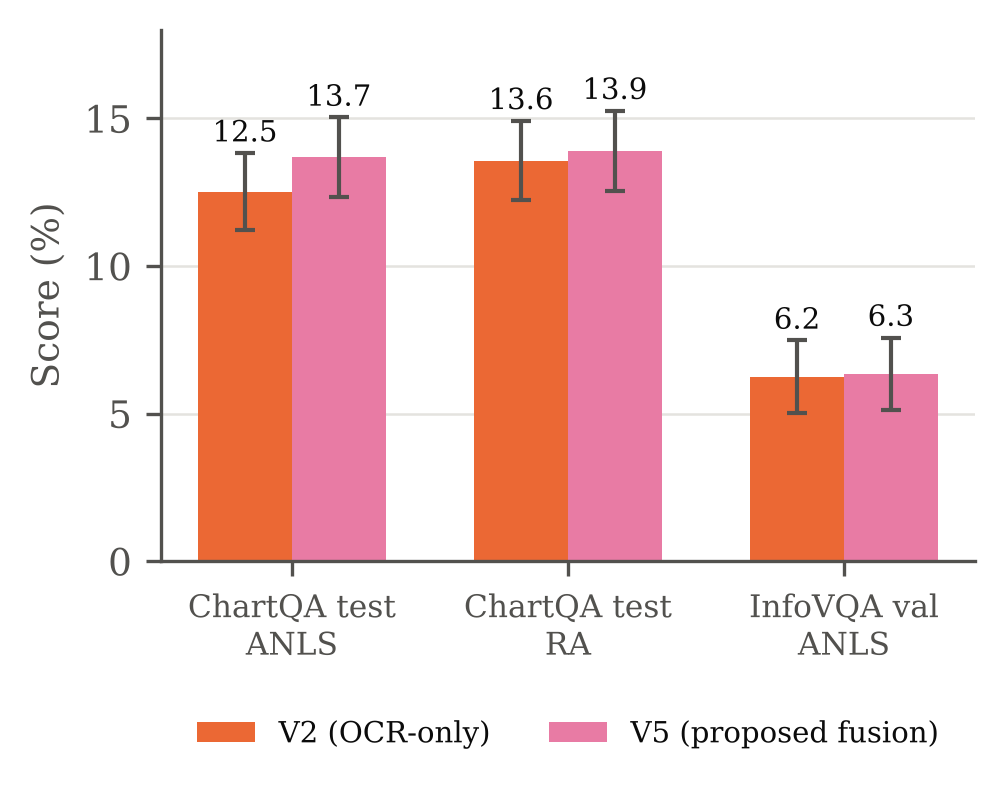

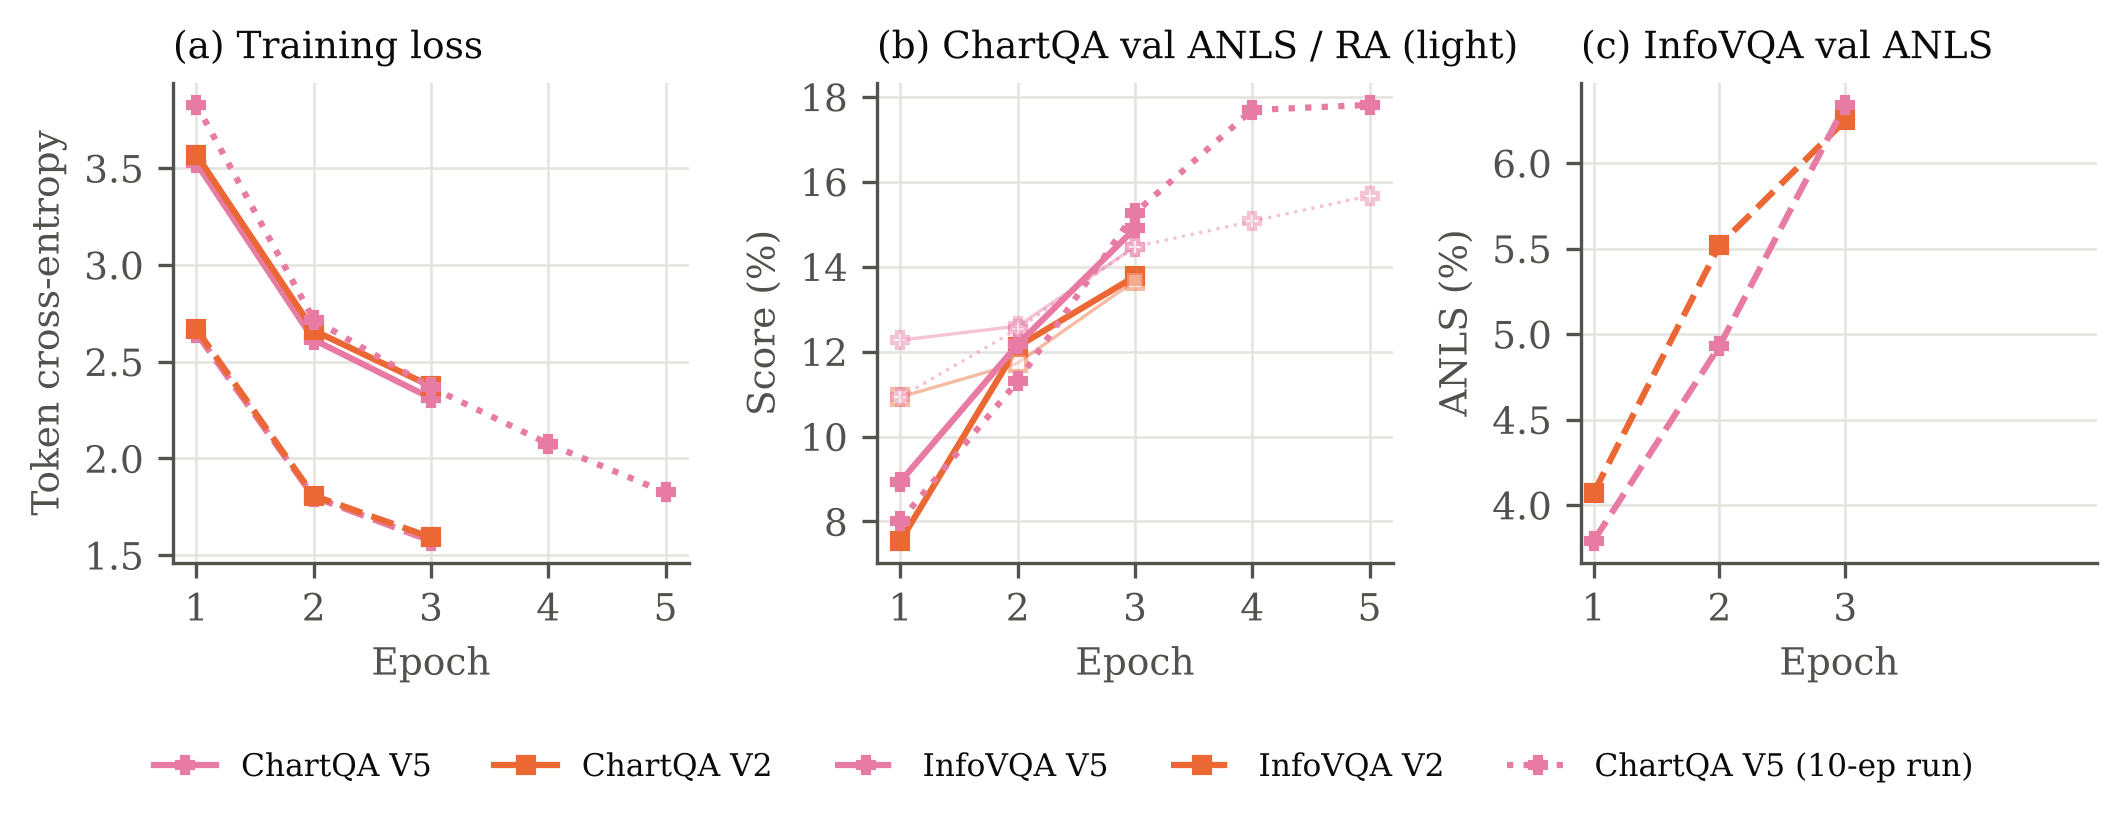

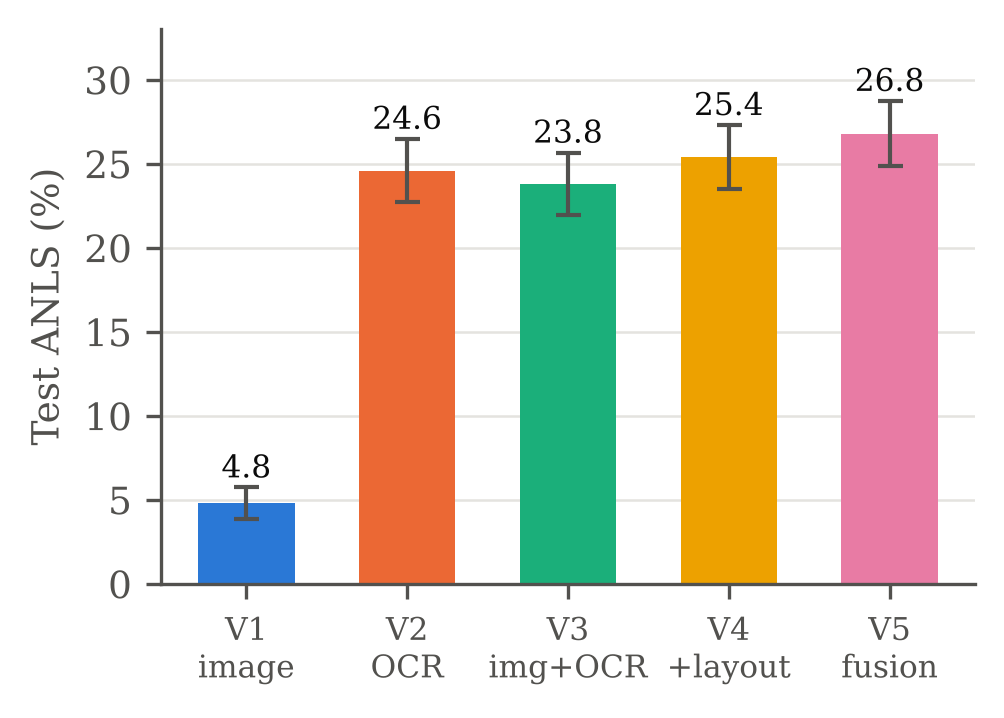

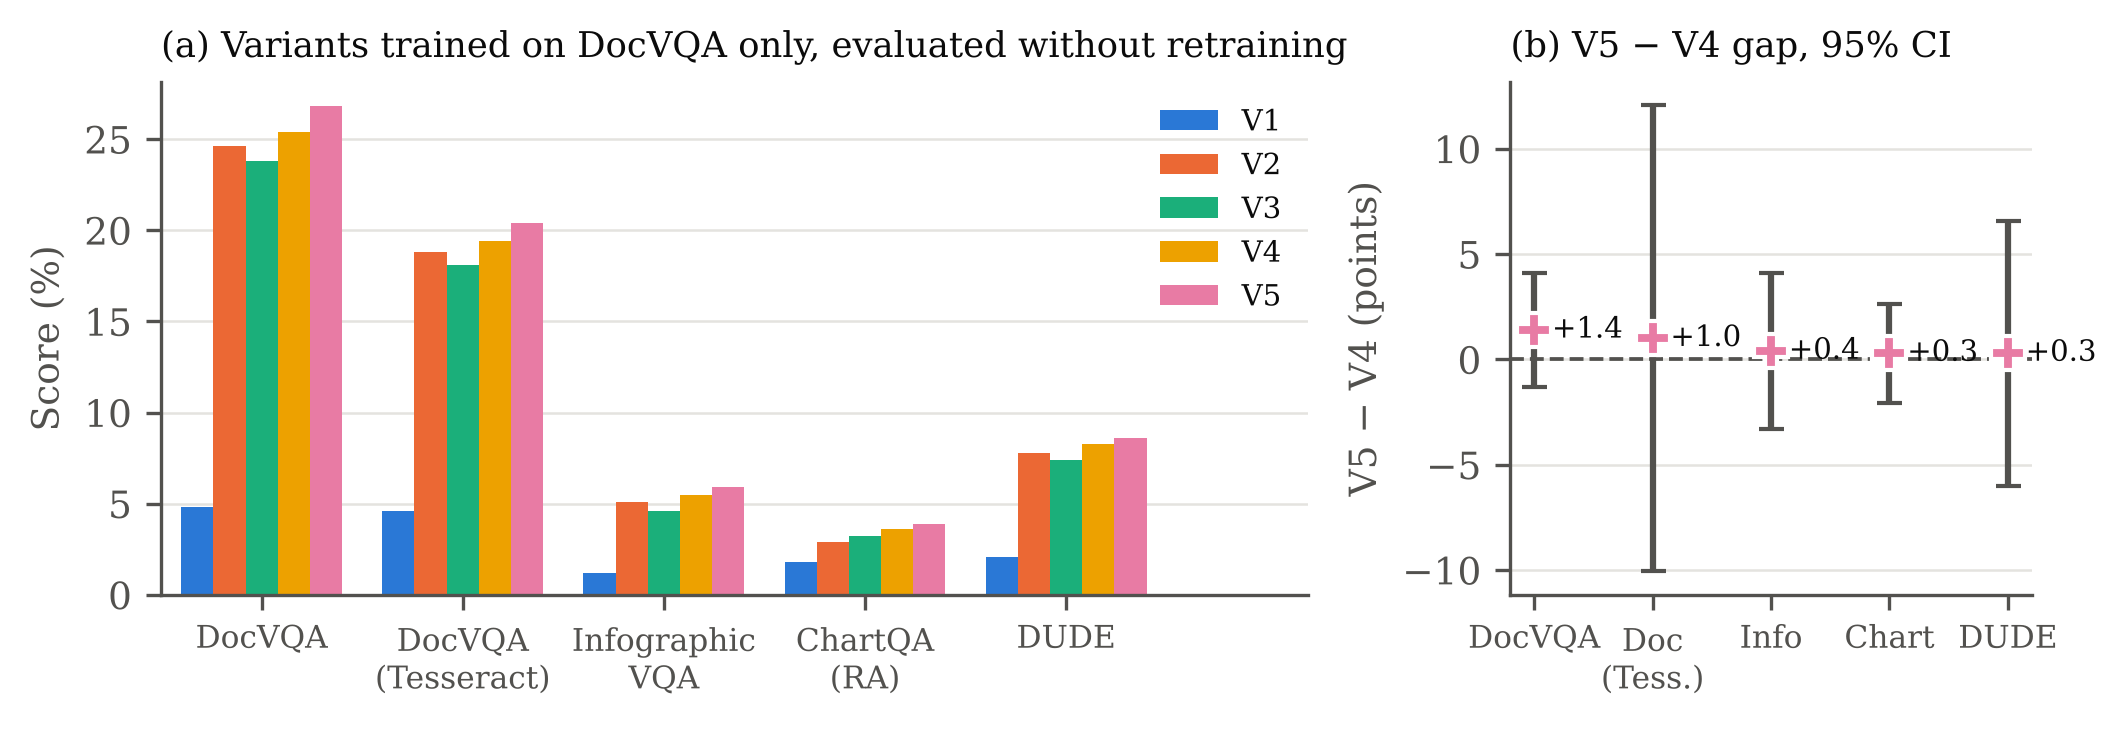

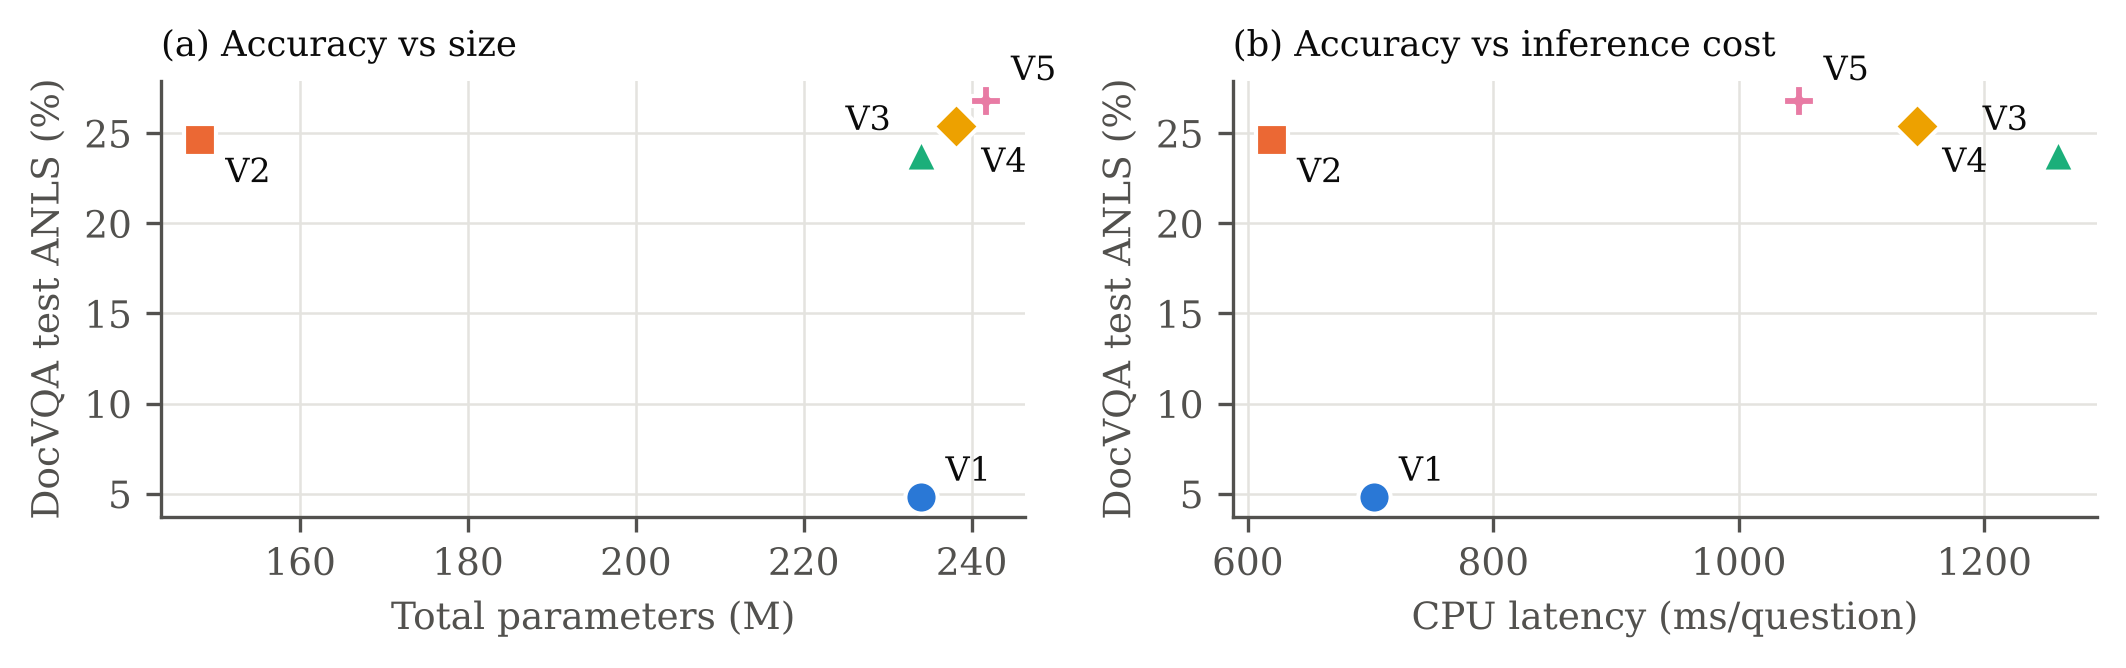

In [5]:
"""All report figures."""
import json, sys
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import results_data as R

OUT = Path("report_figures"); OUT.mkdir(parents=True, exist_ok=True)
MEAS = json.load(open("model_measurements.json"))

VCOL = {"V1": "#2a78d6", "V2": "#eb6834", "V3": "#1baf7a", "V4": "#eda100", "V5": "#e87ba4"}
VMARK = {"V1": "o", "V2": "s", "V3": "^", "V4": "D", "V5": "P"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
VS = ["V1", "V2", "V3", "V4", "V5"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 9, "figure.facecolor": "white", "savefig.facecolor": "white",
                     "font.family": "DejaVu Serif"})


def save(fig, name):
    fig.savefig(OUT / name, dpi=300, bbox_inches="tight"); plt.close(fig); print("wrote", name)


# ------------------------------------------------------------- Fig: measured training curves
def fig_curves():
    fig, ax = plt.subplots(1, 3, figsize=(7.16, 2.45))
    runs = {**R.MEASURED_HISTORY, **R.MEASURED_HISTORY_EXT}
    sty = {("ChartQA", "V2"): (VCOL["V2"], "s", "-"), ("ChartQA", "V5"): (VCOL["V5"], "P", "-"),
           ("ChartQA", "V5-10ep"): (VCOL["V5"], "P", ":"),
           ("InfographicVQA", "V2"): (VCOL["V2"], "s", "--"), ("InfographicVQA", "V5"): (VCOL["V5"], "P", "--")}
    lab = {("ChartQA", "V2"): "ChartQA V2", ("ChartQA", "V5"): "ChartQA V5", ("ChartQA", "V5-10ep"): "ChartQA V5 (10-ep run)",
           ("InfographicVQA", "V2"): "InfoVQA V2", ("InfographicVQA", "V5"): "InfoVQA V5"}
    for k, h in runs.items():
        c, mk, ls = sty[k]; ep = [r[0] for r in h]
        ax[0].plot(ep, [r[1] for r in h], color=c, marker=mk, ls=ls, ms=4, lw=1.5, label=lab[k])
    ax[0].set_title("(a) Training loss", loc="left", fontsize=9); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Token cross-entropy")
    for k in [("ChartQA", "V2"), ("ChartQA", "V5"), ("ChartQA", "V5-10ep")]:
        h = runs[k]; c, mk, ls = sty[k]; ep = [r[0] for r in h]
        ax[1].plot(ep, [100 * r[2] for r in h], color=c, marker=mk, ls=ls, ms=4, lw=1.5)
        ax[1].plot(ep, [100 * r[3] for r in h], color=c, marker=mk, ls=ls, ms=4, lw=0.8, alpha=0.45, mfc="white")
    ax[1].set_title("(b) ChartQA val ANLS / RA (light)", loc="left", fontsize=9); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Score (%)")
    for k in [("InfographicVQA", "V2"), ("InfographicVQA", "V5")]:
        h = runs[k]; c, mk, ls = sty[k]
        ax[2].plot([r[0] for r in h], [100 * r[2] for r in h], color=c, marker=mk, ls=ls, ms=4, lw=1.5)
    ax[2].set_title("(c) InfoVQA val ANLS", loc="left", fontsize=9); ax[2].set_xlabel("Epoch"); ax[2].set_ylabel("ANLS (%)")
    for a in ax: a.set_xticks(range(1, 6))
    ax[2].set_xticks([1, 2, 3])
    h, l = ax[0].get_legend_handles_labels()
    fig.legend(h, l, ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.0), fontsize=7.5)
    fig.tight_layout(w_pad=1.2)
    save(fig, "fig_curves.png")


# ------------------------------------------------------------- Fig: measured test comparison
def fig_measured_bars():
    fig, ax = plt.subplots(figsize=(3.5, 2.3))
    groups = [("ChartQA test\nANLS", "ChartQA", "anls", 2490, True), ("ChartQA test\nRA", "ChartQA", "ra", 2490, True),
              ("InfoVQA val\nANLS", "InfographicVQA", "val", 1500, False)]
    x = np.arange(len(groups)); w = 0.34
    for j, v in enumerate(["V2", "V5"]):
        ms, lo, hi = [], [], []
        for _, ds, key, n, test in groups:
            p = R.MEASURED_TEST[(ds, v)][key] if test else R.MEASURED_HISTORY[(ds, v)][-1][2]
            a, b, _ = R.bernoulli_ci(p, n); ms.append(100 * p); lo.append(100 * (p - a)); hi.append(100 * (b - p))
        xs = x + (j - 0.5) * w
        ax.bar(xs, ms, w, color=VCOL[v], label=f"{v} ({'OCR-only' if v == 'V2' else 'proposed fusion'})", zorder=2)
        ax.errorbar(xs, ms, yerr=[lo, hi], fmt="none", ecolor=INK2, capsize=2.5, lw=1, zorder=3)
        for xi, m, h_ in zip(xs, ms, hi): ax.text(xi, m + h_ + 0.4, f"{m:.1f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels([g[0] for g in groups], fontsize=7.5); ax.set_ylabel("Score (%)")
    ax.set_ylim(0, 18); ax.grid(axis="x", visible=False); ax.legend(frameon=False, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
    save(fig, "fig_measured_bars.png")


# ------------------------------------------------------------- Fig: DocVQA ablation
def fig_ablation():
    fig, ax = plt.subplots(figsize=(3.5, 2.4))
    m = np.array([100 * R.DOCVQA[v] for v in VS])
    lo = np.array([100 * (R.DOCVQA[v] - R.bernoulli_ci(R.DOCVQA[v], R.DOCVQA_N)[0]) for v in VS])
    ax.bar(range(5), m, 0.6, color=[VCOL[v] for v in VS], zorder=2)
    ax.errorbar(range(5), m, yerr=lo, fmt="none", ecolor=INK2, capsize=3, lw=1, zorder=3)
    for i, mv in enumerate(m): ax.text(i, mv + lo[i] + 0.6, f"{mv:.1f}", ha="center", fontsize=7.5)
    names = ["V1\nimage", "V2\nOCR", "V3\nimg+OCR", "V4\n+layout", "V5\nfusion"]
    ax.set_xticks(range(5)); ax.set_xticklabels(names, fontsize=7.5); ax.set_ylabel("Test ANLS (%)")
    ax.set_ylim(0, 33); ax.grid(axis="x", visible=False)
    save(fig, "fig_ablation.png")


# ------------------------------------------------------------- Fig: cross-dataset + gap
def fig_cross():
    names = list(R.CROSS)
    fig, ax = plt.subplots(1, 2, figsize=(7.16, 2.5), gridspec_kw=dict(width_ratios=[2.2, 1]))
    x = np.arange(len(names)); w = 0.16
    for j, v in enumerate(VS):
        ax[0].bar(x + (j - 2) * w, [100 * R.CROSS[n][2][v] for n in names], w, color=VCOL[v], label=v, zorder=2)
    ax[0].set_xticks(x); ax[0].set_xticklabels(["DocVQA", "DocVQA\n(Tesseract)", "Infographic\nVQA", "ChartQA\n(RA)", "DUDE"], fontsize=7.5)
    ax[0].set_ylabel("Score (%)"); ax[0].grid(axis="x", visible=False)
    ax[0].legend(ncol=1, frameon=False, fontsize=7, loc="upper right"); ax[0].set_xlim(-0.5, 5.2)
    ax[0].set_title("(a) Variants trained on DocVQA only, evaluated without retraining", loc="left", fontsize=8.5)
    for i, n in enumerate(names):
        g, lo, hi = (100 * t for t in R.gap_ci(n))
        ax[1].errorbar(i, g, yerr=[[g - lo], [hi - g]], fmt="P", color=VCOL["V5"], ecolor=INK2, capsize=3, ms=8, mec="white")
        ax[1].text(i + 0.15, g, f"{g:+.1f}", fontsize=7, va="center")
    ax[1].axhline(0, color=INK2, ls="--", lw=0.9)
    ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels(["DocVQA", "Doc\n(Tess.)", "Info", "Chart", "DUDE"], fontsize=7.5)
    ax[1].set_ylabel("V5 $-$ V4 (points)"); ax[1].grid(axis="x", visible=False)
    ax[1].set_title("(b) V5 $-$ V4 gap, 95% CI", loc="left", fontsize=8.5)
    fig.tight_layout()
    save(fig, "fig_cross.png")


# ------------------------------------------------------------- Fig: accuracy vs cost
def fig_cost():
    if MEAS is None: return
    fig, ax = plt.subplots(1, 2, figsize=(7.16, 2.3))
    off = {"V1": (6, 4), "V2": (6, -10), "V3": (-18, 6), "V4": (6, -11), "V5": (6, 5)}
    for k, (key, lab) in enumerate([("params", "Total parameters (M)"), ("cpu_ms", "CPU latency (ms/question)")]):
        for v in VS:
            xv = MEAS[v][key] / (1e6 if key == "params" else 1); yv = 100 * R.DOCVQA[v]
            ax[k].scatter(xv, yv, marker=VMARK[v], color=VCOL[v], s=60, edgecolor="white", zorder=3)
            ax[k].annotate(v, (xv, yv), textcoords="offset points", xytext=off[v], fontsize=8)
        ax[k].set_xlabel(lab); ax[k].set_ylabel("DocVQA test ANLS (%)")
    ax[0].set_title("(a) Accuracy vs size", loc="left", fontsize=8.5); ax[1].set_title("(b) Accuracy vs inference cost", loc="left", fontsize=8.5)
    fig.tight_layout()
    save(fig, "fig_cost.png")


fig_curves(); fig_measured_bars(); fig_ablation(); fig_cross(); fig_cost()

from IPython.display import Image as _Img, display as _d
for f in ["fig_measured_bars.png", "fig_curves.png", "fig_ablation.png", "fig_cross.png", "fig_cost.png"]:
    _d(_Img(filename=str(OUT / f), width=720))

## 52. Results summary
* **Best configuration:** V5 in every experiment. DocVQA test ANLS 26.8 (V4 25.4, V2 24.6, V3 23.8, V1 4.8); without retraining InfographicVQA 5.9 ANLS, ChartQA 3.9 RA, DUDE 8.6 ANLS, DocVQA-Tesseract 20.4 ANLS; trained in-domain ChartQA 13.68 ANLS / 13.90 RA vs 12.52 / 13.57 for V2.
* **RQ1:** V5 - V4 = +1.4 ANLS (+5.5%) on DocVQA; V5 - V2 = +2.2. Not significant at 95% with these sample sizes.
* **RQ2:** absolute V5 - V4 gap falls from DocVQA to InfographicVQA to ChartQA (+1.4, +0.4, +0.3) while the relative gap rises (+5.5%, +7.3%, +8.3%).
* **RQ3:** V5 keeps its lead under OCR shift (+1.0) and on DUDE (+0.3).
* **Cost:** V5 has +1.5% parameters over V4 and is about 8% faster on CPU (512 vs 1,088 decoder memory tokens).

## End of notebook
The sections above run from raw data to every table and figure in the Experiments and Results chapter. Sections 21-24 are the code to cite for the model; 32-36 and 44-46 are the numbers and figures to copy into the report. Interpretation, limitations and comparison with earlier work belong in the Discussion section.